# Video Test-Time Adaptation Under Correlated Distribution Shifts (RG-ViTTA)

**Applied Foundations of Machine Learning (AFML) — Course Project**  
**Team Strawhat Pirates:** Samarth P Kulkarni, B Thrivikram, Mohammad Faizan  
**Pretrained Backbone:** VideoMAE (`videomae-base-finetuned-ucf101`)  
**Target Benchmark:** UCF-101 Action Recognition under Correlated Corruptions  

---

## 📌 Executive Summary & Core Hypothesis

Video Test-Time Adaptation (TTA) aims to adapt pretrained video recognition models to unseen test-time distribution shifts (e.g., weather degradation, motion blur, sensor noise, compression) without access to source training data or ground-truth supervision.

Existing video TTA frameworks (such as ViTTA and TempT) rely heavily on **temporal prediction consistency** as a self-supervisory objective under the core assumption:
$$\text{Temporal Agreement Across Frames} \implies \text{Prediction Reliability}$$

### The "Echo Chamber Trap"
In real-world video distribution shifts, corruptions are **temporally correlated**: consecutive frames experience nearly identical noise, blur, or compression artifacts. As the temporal correlation $\rho \to 1$:
1. The model makes a consistent, confident, yet incorrect prediction across consecutive frames.
2. Temporal consistency metrics register high agreement, misinterpreting systematic corruption for semantic certainty.
3. Blind consistency-driven adaptation forces the network to optimize towards its own erroneous predictions, poisoning the model's weights and causing **Harmful Adaptation (HAR)**.

To break this failure mode, we propose **Reliability-Guided ViTTA (RG-ViTTA)**: a dual-signal reliability framework that pits **spatial perturbation invariance** against temporal consistency to expose echo chamber traps and selectively govern test-time weight updates.

---

## 📑 Interactive Table of Contents
* [Section 0: Environment Setup, Checkpoint Policy & Dependencies](#section-0-environment-setup-checkpoint-policy--dependencies)
* [Section 1: Phase 1 — Backbone Architecture & Clean Baseline Verification](#section-1-phase-1--backbone-architecture--clean-baseline-verification)
* [Section 2: Phase 2 — Variance-Preserving AR(1) Correlated Distribution Shifts](#section-2-phase-2--variance-preserving-ar1-correlated-distribution-shifts)
* [Section 3: Phase 3 — Dual Consistency Lie Detector (C_temp vs C_spat)](#section-3-phase-3--dual-consistency-lie-detector-c_temp-vs-c_spat)
* [Section 4: Phase 4 — Calibrated Multi-Signal Reliability Estimator Head (The Referee)](#section-4-phase-4--calibrated-multi-signal-reliability-estimator-head-the-referee)
* [Section 5: Phase 5 — Reliability-Guided Video Test-Time Adaptation (RG-ViTTA)](#section-5-phase-5--reliability-guided-video-test-time-adaptation-rg-vitta)
* [Section 6: Phase 6 — Comprehensive Statistical Analysis & Benchmark Figures](#section-6-phase-6--comprehensive-statistical-analysis--benchmark-figures)
* [Section 7: Advanced Research Pivots (Pivots A, B & C)](#section-7-advanced-research-pivots-pivots-a-b--c)
* [Section 8: Unified Project Deliverables & Artifact Exporter](#section-8-unified-project-deliverables--artifact-exporter)

---
<a id="section-0-environment-setup-checkpoint-policy--dependencies"></a>
## Section 0: Environment Setup, Checkpoint Policy & Dependencies

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test.csv
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/train.csv
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/val.csv
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g01_c02.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g01_c04.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g02_c01.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g02_c04.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g04_c07.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g05_c03.avi
/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/test/ApplyEyeMakeup/v_ApplyEyeMakeup_g05_c05.avi


## Corrected rerun protocol (v2)

This notebook keeps exploratory/legacy cells for reference, but the **primary pipeline uses only v2 artifacts**. Do not use legacy CSVs as inputs to the primary analysis.

**Primary execution order:**
1. Setup, model loading, dataset discovery, and video-list creation.
2. Phase 2 v2 corruption grid → download the Phase 2 checkpoint ZIP.
3. Phase 3 v2 consistency signals → download the Phase 3 checkpoint ZIP.
4. Phase 3 analysis cells (AUROC/CI/feature comparison) using `phase3_signals_v2.csv`.
5. Phase 4 video-level train/validation/test split and reliability estimator → download the Phase 4 checkpoint ZIP.
6. Phase 5 model/corruption setup, then Phase 5 function definitions, then the Phase 5 runner. Download each condition ZIP immediately.
7. Run the results aggregation cell, then the final backup cell. Download the final ZIP to your computer.

**Important:** Kaggle `/kaggle/working` is temporary. The notebook outputs are not a backup of the underlying per-video CSV/NPY files. Download each checkpoint ZIP. If the kernel restarts, upload the ZIP or its files into the new session before continuing.

Corruption definitions are shared between Phase 2, Phase 3, and Phase 5 v2. The AR(1) generator uses a local random generator, validates rho, and makes rho=1 temporally frozen. Measured pixel-space strength can still differ because of clipping and nonlinear corruption operators; report measured strength rather than claiming equal effective severity without calibration.


## Reproducible execution and checkpoint policy

**Important:** `/kaggle/working` is temporary runtime storage and can be cleared after a session reset. After each expensive phase, create and download the checkpoint ZIP. Do not rely on notebook output text as a substitute for per-video CSV/NPY artifacts.

Recommended order: setup/model → Phase 2 v2 → download checkpoint → Phase 3 v2 → download checkpoint → Phase 3 analysis → Phase 4 split/estimator → download checkpoint → Phase 5 evaluation → download checkpoint. Legacy cells are exploratory only and must not feed the primary v2 results.

In [2]:
import os, json, time, zipfile
from IPython.display import FileLink, display

def checkpoint_files(label, paths):
    """Zip existing artifacts plus a manifest and display a download link."""
    stamp = time.strftime("%Y%m%d_%H%M%S")
    zip_path = f"/kaggle/working/{label}_{stamp}.zip"
    included = []
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for path in paths:
            if path and os.path.isfile(path):
                zf.write(path, arcname=os.path.basename(path))
                included.append({"file": os.path.basename(path), "bytes": os.path.getsize(path)})
        zf.writestr("manifest.json", json.dumps({"label": label, "created": stamp, "files": included}, indent=2))
    print(f"Checkpoint: {zip_path} | included {len(included)} files")
    if not included:
        print("WARNING: no requested files existed; do not assume this checkpoint contains results.")
    display(FileLink(zip_path))
    return zip_path

# Use this after each phase. Download the displayed ZIP to your computer.
def checkpoint_phase2():
    return checkpoint_files("AFML_Phase2_Checkpoint", ["/kaggle/working/phase2_grid_v2.csv", "/kaggle/working/phase2_logits_v2.npy", "/kaggle/working/test_videos.txt"])
def checkpoint_phase3():
    return checkpoint_files("AFML_Phase3_Checkpoint", ["/kaggle/working/phase3_signals_v2.csv", "/kaggle/working/phase3_probs_v2.npy", "/kaggle/working/test_videos.txt"])
def checkpoint_phase4():
    return checkpoint_files("AFML_Phase4_Checkpoint", ["/kaggle/working/phase4_validation_scores_v2.csv", "/kaggle/working/phase4_test_scores_v2.csv", "/kaggle/working/phase4_video_split_v2.csv", "/kaggle/working/phase4_reliability_estimator_v2.joblib"])
def checkpoint_phase5():
    paths = [p for p in __import__("glob").glob("/kaggle/working/phase5_v2_*.csv")]
    paths += ["/kaggle/working/phase5_lr_sensitivity_v2.csv"]
    return checkpoint_files("AFML_Phase5_Checkpoint", paths)


---
<a id="section-1-phase-1--backbone-architecture--clean-baseline-verification"></a>
# Section 1: Phase 1 — Backbone Architecture & Clean Baseline Verification

**Goal:** Load the fine-tuned UCF-101 VideoMAE model, verify attention bias alignment, and establish the clean source-only accuracy on the true unseen test split ($g01$–$g07$).

* **Backbone:** `nateraw/videomae-base-finetuned-ucf101` (101 classes, Vision Transformer architecture)
* **Data Leakage Audit:** Groups $g08$–$g25$ were part of training; groups $g01$–$g07$ form the strict test split.
* **Target Clean Baseline:** $76.5\%$ on single-clip test set ($85.5\%$ on multi-clip).

In [3]:
# Cell 1: Install dependencies
!pip install -q decord transformers
import os
import glob
import torch
import numpy as np
import cv2
from decord import VideoReader, cpu
from transformers import AutoImageProcessor, VideoMAEForVideoClassification

# Verify GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU'})")

Using device: cuda (Tesla T4)


In [4]:
# Cell 2: Load Pretrained UCF-101 Model & Processor
MODEL_NAME = "nateraw/videomae-base-finetuned-ucf101"

print(f"Loading pretrained model: {MODEL_NAME}...")
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = VideoMAEForVideoClassification.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

# Inspect model classes
id2label = model.config.id2label
print(f"Model loaded successfully! Total classes: {len(id2label)}")
print(f"Sample classes: {[id2label[i] for i in range(5)]}")

Loading pretrained model: nateraw/videomae-base-finetuned-ucf101...


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.60k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  345MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  345MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: nateraw/videomae-base-finetuned-ucf101
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.value.bias | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully! Total classes: 101
Sample classes: ['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam']


In [5]:
# Cell 2.5: Remap Attention Biases
from huggingface_hub import hf_hub_download

# Locate the downloaded pytorch_model.bin file from cache
weights_path = hf_hub_download(repo_id=MODEL_NAME, filename="pytorch_model.bin")
raw_weights = torch.load(weights_path, map_location='cpu', weights_only=True)

with torch.no_grad():
    for i in range(12):
        q_bias = raw_weights.get(f'videomae.encoder.layer.{i}.attention.attention.q_bias')
        v_bias = raw_weights.get(f'videomae.encoder.layer.{i}.attention.attention.v_bias')
        if q_bias is not None and v_bias is not None:
            model.videomae.encoder.layer[i].attention.attention.query.bias.copy_(q_bias.to(device))
            model.videomae.encoder.layer[i].attention.attention.key.bias.zero_()
            model.videomae.encoder.layer[i].attention.attention.value.bias.copy_(v_bias.to(device))

print("Biases successfully remapped! Model is ready.")

Biases successfully remapped! Model is ready.


In [6]:
# Cell 3: Video Reader & Preprocessor
import decord
decord.bridge.set_bridge('native')

def load_video_frames(video_path, num_frames=16):
    """
    Decodes video and uniformly samples `num_frames` across duration.
    Returns list of NumPy RGB frames (H, W, 3).
    """
    try:
        vr = VideoReader(video_path, ctx=cpu(0))
        total_frames = len(vr)
        if total_frames <= num_frames:
            indices = np.linspace(0, total_frames - 1, total_frames, dtype=int)
            indices = np.pad(indices, (0, num_frames - total_frames), mode='edge')
        else:
            indices = np.linspace(0, total_frames - 1, num_frames, dtype=int)
        frames = vr.get_batch(indices).asnumpy()
        return [f for f in frames]
    except Exception:
        # Fallback to OpenCV if decord has codec issues on a specific video
        cap = cv2.VideoCapture(video_path)
        all_frames = []
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            all_frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        cap.release()
        total_frames = len(all_frames)
        if total_frames == 0:
            raise ValueError(f"Could not read any frames from {video_path}")
        indices = np.linspace(0, total_frames - 1, num_frames, dtype=int)
        return [all_frames[i] for i in indices]

def preprocess_video(frames):
    """
    Applies standard VideoMAE normalization and converts to PyTorch tensor.
    """
    inputs = processor(frames, return_tensors="pt")
    return inputs['pixel_values'].to(device)

print("Video loader & preprocessor defined successfully!")

Video loader & preprocessor defined successfully!


In [7]:
import os, glob

# Step 1: See what's actually there (including zip files)
for root, dirs, files in os.walk('/kaggle/input'):
    if files:
        print(f"Folder: {root}")
        for f in files[:10]:
            print(f"  {f} ({os.path.getsize(os.path.join(root, f)) / 1e6:.1f} MB)")
        break

# Also check for zip/rar/tar files
zips = glob.glob("/kaggle/input/**/*.zip", recursive=True) + \
       glob.glob("/kaggle/input/**/*.rar", recursive=True) + \
       glob.glob("/kaggle/input/**/*.tar*", recursive=True)
print(f"\nArchive files found: {zips}")

Folder: /kaggle/input/datasets/matthewjansen/ucf101-action-recognition
  test.csv (0.1 MB)
  train.csv (0.8 MB)
  val.csv (0.1 MB)

Archive files found: []


In [8]:
# Cell 4: Single Video Sanity Check
DATA_ROOT = "/kaggle/input/datasets/matthewjansen/ucf101-action-recognition"

# 1. Pick a sample video
sample_video = "/kaggle/input/datasets/matthewjansen/ucf101-action-recognition/val/HorseRace/v_HorseRace_g11_c01.avi"
gt_class = sample_video.split('/')[-2]  # Ground truth = folder name (e.g., "HorseRace")
print(f"Testing on: {os.path.basename(sample_video)}")
print(f"Ground truth label: {gt_class}")

# 2. Load 16 frames and preprocess
frames = load_video_frames(sample_video, num_frames=16)
video_tensor = preprocess_video(frames)
print(f"Video tensor shape: {video_tensor.shape}")

# 3. Ask the model to predict
with torch.no_grad():
    outputs = model(video_tensor)
    probs = torch.softmax(outputs.logits, dim=-1)

# 4. Print Top-3 predictions
top3_probs, top3_indices = torch.topk(probs, k=3, dim=-1)

print("\n--- Model's Top 3 Guesses ---")
for i in range(3):
    idx = top3_indices[0][i].item()
    conf = top3_probs[0][i].item() * 100
    match = "✅" if id2label[idx] == gt_class else ""
    print(f"  Rank {i+1}: {id2label[idx]} ({conf:.2f}%) {match}")

Testing on: v_HorseRace_g11_c01.avi
Ground truth label: HorseRace
Video tensor shape: torch.Size([1, 16, 3, 224, 224])

--- Model's Top 3 Guesses ---
  Rank 1: HorseRace (78.54%) ✅
  Rank 2: LongJump (2.63%) 
  Rank 3: PoleVault (1.16%) 


In [ ]:
# Cell 5: Clean Baseline Accuracy (Source-Only)
import glob, time

# Get all validation videos
val_videos = sorted(glob.glob(f"{DATA_ROOT}/val/**/*.avi", recursive=True))
print(f"Total validation videos: {len(val_videos)}")

# Evaluate on first 200 videos (takes ~5-10 min on Kaggle GPU)
num_eval = min(200, len(val_videos))
eval_videos = val_videos[:num_eval]

correct = 0
total = 0
errors = 0
start_time = time.time()

print(f"Evaluating clean baseline on {num_eval} videos...\n")

for i, v_path in enumerate(eval_videos):
    gt_class = v_path.split('/')[-2]  # Folder name = ground truth

    try:
        frames = load_video_frames(v_path, num_frames=16)
        video_tensor = preprocess_video(frames)

        with torch.no_grad():
            logits = model(video_tensor).logits
            pred_idx = torch.argmax(logits, dim=-1).item()
            pred_class = id2label[pred_idx]

        if pred_class == gt_class:
            correct += 1
        total += 1

    except Exception as e:
        errors += 1

    if (i + 1) % 50 == 0:
        elapsed = time.time() - start_time
        acc = correct / total * 100 if total > 0 else 0
        speed = (i + 1) / elapsed
        remaining = (num_eval - i - 1) / speed
        print(f"[{i+1}/{num_eval}] Accuracy: {acc:.2f}% | Speed: {speed:.1f} vid/s | ETA: {remaining:.0f}s")

# Final Result
clean_acc = correct / total * 100 if total > 0 else 0
elapsed = time.time() - start_time

print(f"\n{'='*50}")
print(f"  PHASE 1 COMPLETE!")
print(f"  Clean Source-Only Accuracy: {clean_acc:.2f}% ({correct}/{total})")
print(f"  Skipped (read errors): {errors}")
print(f"  Time taken: {elapsed:.1f}s")
print(f"{'='*50}")

Total validation videos: 1673
Evaluating clean baseline on 200 videos...

[50/200] Accuracy: 96.00% | Speed: 1.6 vid/s | ETA: 96s
[100/200] Accuracy: 94.00% | Speed: 1.5 vid/s | ETA: 67s


---
<a id="section-2-phase-2--variance-preserving-ar1-correlated-distribution-shifts"></a>
# Section 2: Phase 2 — Variance-Preserving AR(1) Correlated Distribution Shifts

**Goal:** Construct a temporally correlated corruption engine with strict variance-preserving properties across $\rho \in \{0.0, 0.5, 0.85, 1.0\}$ and evaluate accuracy degradation across 5 distinct corruptions.

### Stationary AR(1) Formulation:
$$z_1 \sim \mathcal{N}(0, 1)$$
$$z_t = \rho z_{t-1} + \sqrt{1 - \rho^2} \eta_t, \quad \eta_t \sim \mathcal{N}(0, 1)$$
* **Severity Invariance:** $\text{Var}(z_t) = 1.0$ for all $t$ and all $\rho$.
* **Corruptions Implemented:** Gaussian Noise, Defocus Blur, Motion Blur, JPEG Compression, Brightness Shift across severities $s \in \{1, 3, 5\}$.

In [18]:
import cv2, io, numpy as np
from PIL import Image

def to224(frames):
    """Resize shortest side to 224 and center-crop."""
    out = []
    for f in frames:
        h, w = f.shape[:2]
        scale = 224 / min(h, w)
        f = cv2.resize(f, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
        h, w = f.shape[:2]
        top, left = (h-224)//2, (w-224)//2
        out.append(f[top:top+224, left:left+224])
    return out



def _ar1(num_frames, shape, rho, seed):
    if not 0 <= rho <= 1:
        raise ValueError("rho must be in [0, 1]")

    rng = np.random.default_rng(seed)
    z = np.empty((num_frames, *shape), dtype=np.float32)

    if rho == 1.0:
        # Constant over time, with a bounded unit-scale value.
        # Draw one standard-normal field and reuse it across all frames.
        # Do not clip the latent noise: clipping changes its marginal distribution.
        base = rng.standard_normal(shape).astype(np.float32)
        z[:] = base
        return z

    z[0] = rng.standard_normal(shape).astype(np.float32)

    for t in range(1, num_frames):
        eps = rng.standard_normal(shape).astype(np.float32)
        z[t] = rho * z[t - 1] + np.sqrt(1 - rho**2) * eps

    # Normalize only when temporal variation exists.
    z /= max(float(z.std()), 1e-6)
    return z



def apply_gaussian_noise(frames, z, severity):
    sigma = {1:10, 3:30, 5:60}[severity]
    return [np.clip(f.astype(np.float32)+sigma*z[t], 0, 255).astype(np.uint8)
            for t, f in enumerate(frames)]

def apply_defocus_blur(frames, z, severity):
    base = {1:1.0, 3:2.5, 5:4.5}[severity]
    out = []
    for t, f in enumerate(frames):
        # Same parameter range at every rho; rho changes temporal ordering/correlation.
        sigma = base * np.clip(1.0 + 0.25*float(z[t,0,0,0]), 0.5, 1.5)
        out.append(cv2.GaussianBlur(f, (0,0), float(sigma)))
    return out

def _motion_kernel(k, angle_deg):
    ker = np.zeros((k,k), np.float32); ker[k//2,:] = 1
    mat = cv2.getRotationMatrix2D(((k-1)/2,(k-1)/2), float(angle_deg), 1.0)
    ker = cv2.warpAffine(ker, mat, (k,k))
    return ker / max(float(ker.sum()), 1e-6)

def apply_motion_blur(frames, z, severity):
    k = {1:5, 3:15, 5:25}[severity]
    out = []
    for t, f in enumerate(frames):
        angle = 25.0 * np.clip(float(z[t,0,0,0]), -1.0, 1.0)
        out.append(cv2.filter2D(f, -1, _motion_kernel(k, angle)))
    return out

def apply_jpeg_compression(frames, z, severity):
    base_quality = {1:40, 3:15, 5:5}[severity]
    out = []
    for t, f in enumerate(frames):
        quality = int(np.clip(round(base_quality * (1 + 0.20*float(z[t,0,0,0]))), 1, 95))
        buf = io.BytesIO()
        Image.fromarray(f).save(buf, format="JPEG", quality=quality)
        buf.seek(0)
        out.append(np.array(Image.open(buf).convert("RGB")))
    return out

def apply_brightness_shift(frames, z, severity):
    # Fixed amplitude; the signed AR(1) signal controls temporal variation.
    amplitude = {1:20, 3:45, 5:80}[severity]
    return [np.clip(f.astype(np.float32)+amplitude*z[t,0,0,0],0,255).astype(np.uint8)
            for t,f in enumerate(frames)]

CORRUPTIONS = {
    "gaussian_noise": apply_gaussian_noise,
    "defocus_blur": apply_defocus_blur,
    "motion_blur": apply_motion_blur,
    "jpeg_compression": apply_jpeg_compression,
    "brightness_shift": apply_brightness_shift,
}

def corrupt_video(frames, name, severity, rho, seed):
    """Apply reproducible corruption to already resized RGB frames."""
    if name not in CORRUPTIONS:
        raise ValueError(f"Unknown corruption: {name}")
    T = len(frames)
    shape = frames[0].shape if name == "gaussian_noise" else (1,1,1)
    z = _ar1(T, shape, rho, seed)
    if name == "brightness_shift":
        # A single scalar per frame, but normalized across time.
        z = z.reshape(T,1,1,1)
    return CORRUPTIONS[name](frames, z, severity)

print("Controlled corruption functions loaded. Verify measured strength before full reruns.")


Controlled corruption functions loaded. Verify measured strength before full reruns.


In [26]:
# AR(1) Temporally Correlated Noise Generator & Variance Verification
def generate_correlated_noise(num_frames, shape, rho, seed=None):
    """Generates temporally correlated noise using stationary AR(1) process."""
    return _ar1(num_frames, shape, rho, seed)

# Verify unit variance preservation across correlation values
print("Testing AR(1) Variance-Preserving Property:")
for r in [0.0, 0.5, 0.85, 1.0]:
    noise = generate_correlated_noise(16, (224, 224, 3), r, seed=42)
    print(f"  rho={r:.2f} -> empirical variance: {noise.var():.4f} (target: 1.0000)")
print("✅ All variances are ~1.0 regardless of rho (variance-preserving property verified)")

NameError: name 'rng' is not defined

In [20]:
# Cell 8: End-to-End Validation (Gaussian Noise, Severity = 3)
SIGMA, RHOS = 30, [0.0, 0.5, 0.85, 1.0]

# Ensure we use available video list (safe fallback if 'sample' is not defined)
video_pool = sample if 'sample' in locals() else val_videos
vids = video_pool[::25][:20]

# Take the first video for the end-to-end trace
test_video = vids[0]
gt_class = test_video.split('/')[-2]
raw_frames = load_video_frames(test_video, 16)
frames = to224(raw_frames)
clean = np.stack(frames).astype(np.float32)

def lag1(a):  # Mean correlation between adjacent frames
    return np.mean([np.corrcoef(a[t].ravel(), a[t+1].ravel())[0, 1] for t in range(len(a) - 1)])

# 1. Clean reference prediction
clean_tensor = processor(frames, return_tensors="pt")['pixel_values'].to(device)
with torch.no_grad():
    clean_logits = model(clean_tensor).logits
    clean_prob = torch.softmax(clean_logits, dim=-1)
    clean_pred = id2label[clean_prob.argmax(-1).item()]
    clean_conf = clean_prob.max().item() * 100

print(f"Video: {os.path.basename(test_video)} | True Class: {gt_class}")
print(f"Clean Model: {clean_pred} ({clean_conf:.1f}%) | {'✅' if clean_pred == gt_class else '❌'}\n")

# 2. Correlated noise trace across rhos
for rho in RHOS:
    z = generate_correlated_noise(16, clean.shape[1:], rho, seed=0)
    noisy = clean + SIGMA * z
    clip_frac = np.mean((noisy < 0) | (noisy > 255))
    res = np.clip(noisy, 0, 255) - clean  # The exact noise that actually reaches the model
    
    # Run model on the corrupted video
    corrupted_uint8 = [np.clip(noisy[t], 0, 255).astype(np.uint8) for t in range(16)]
    corrupted_tensor = processor(corrupted_uint8, return_tensors="pt")['pixel_values'].to(device)
    with torch.no_grad():
        logits = model(corrupted_tensor).logits
        prob = torch.softmax(logits, dim=-1)
        pred_label = id2label[prob.argmax(-1).item()]
        conf = prob.max().item() * 100
    
    match = "✅" if pred_label == gt_class else "❌"
    
    # Print noise statistics + model prediction side-by-side
    print(f"ρ={rho:.2f} | z: lag1={lag1(z):.3f} | applied: std={res.std():.1f}, lag1={lag1(res):.3f}, clipped={clip_frac:.1%} "
          f"--> Pred: {pred_label} ({conf:.1f}%) {match}")

Video: v_ApplyEyeMakeup_g03_c05.avi | True Class: ApplyEyeMakeup
Clean Model: ApplyEyeMakeup (82.6%) | ✅

ρ=0.00 | z: lag1=-0.001 | applied: std=27.6, lag1=0.010, clipped=11.2% --> Pred: ApplyEyeMakeup (57.5%) ✅
ρ=0.50 | z: lag1=0.500 | applied: std=27.6, lag1=0.492, clipped=11.1% --> Pred: ApplyEyeMakeup (58.9%) ✅
ρ=0.85 | z: lag1=0.850 | applied: std=27.6, lag1=0.838, clipped=11.1% --> Pred: ApplyEyeMakeup (65.9%) ✅
ρ=1.00 | z: lag1=1.000 | applied: std=27.6, lag1=0.990, clipped=11.1% --> Pred: ApplyEyeMakeup (66.3%) ✅


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(len(RHOS), 3, figsize=(9, 12))
for r, rho in enumerate(RHOS):
    z = generate_correlated_noise(16, clean.shape[1:], rho, seed=0)
    res = np.clip(clean + SIGMA*z, 0, 255) - clean
    for c in range(3):
        ax[r, c].imshow(np.clip(res[c, :80, :80]/(4*SIGMA) + 0.5, 0, 1))   # noise only, 80x80 crop
        ax[r, c].set_title(f"rho={rho}, frame {c}"); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# Cell 9: 20-video pilot, Gaussian noise, severity 3, rho in {0, 0.5, 0.85, 1.0}
import time, os
import numpy as np
import pandas as pd
import torch

SEVERITY = 3
CONF_T = 70            # "confident" threshold in percent
COND_ORDER = ['Clean'] + [f'rho={r:.2f}' for r in RHOS]

@torch.no_grad()
def predict(frames):
    x = processor(frames, return_tensors="pt")['pixel_values'].to(device)
    prob = torch.softmax(model(x).logits, dim=-1)[0]
    conf, idx = prob.max(0)
    return id2label[idx.item()], conf.item() * 100

print(f"Pilot: Gaussian noise, severity {SEVERITY}, {len(vids)} videos x {len(RHOS)} rho values")
t0 = time.time()
records, skipped = [], []

for v_idx, v_path in enumerate(vids):
    gt = v_path.split('/')[-2]
    name = os.path.basename(v_path)
    try:
        clean_frames = to224(load_video_frames(v_path, 16))
        clean_arr = np.stack(clean_frames).astype(np.float32)

        pred, conf = predict(clean_frames)
        records.append(dict(video=name, gt=gt, condition='Clean', rho=np.nan,
                            pred=pred, conf=conf, correct=(pred == gt), resid_std=0.0))

        for rho in RHOS:
            corrupted = corrupt_video(clean_frames, 'gaussian_noise', SEVERITY, rho, seed=v_idx)  # same seed across rho = paired
            resid_std = float(np.std(np.stack(corrupted).astype(np.float32) - clean_arr))
            pred, conf = predict(corrupted)
            records.append(dict(video=name, gt=gt, condition=f'rho={rho:.2f}', rho=rho,
                                pred=pred, conf=conf, correct=(pred == gt), resid_std=resid_std))
    except Exception as e:
        skipped.append((name, str(e)))
        print(f"  SKIPPED {name}: {e}")

    if (v_idx + 1) % 5 == 0:
        print(f"  {v_idx + 1}/{len(vids)} done")

print(f"Finished in {time.time() - t0:.1f}s, skipped {len(skipped)} video(s)\n")

pilot = pd.DataFrame(records)                      # note: named 'pilot', does not overwrite earlier 'df'
pilot.to_csv('/kaggle/working/gaussian_noise_pilot.csv', index=False)

# ---- Summary per condition ----
rows = []
for cond in COND_ORDER:
    sub = pilot[pilot.condition == cond]
    wrong = sub[~sub.correct]
    rows.append({
        'Condition': cond,
        'N': len(sub),
        'Acc (%)': round(sub.correct.mean() * 100, 1),
        'Avg conf (all)': round(sub.conf.mean(), 1),
        'N wrong': len(wrong),
        'Avg conf when wrong': round(wrong.conf.mean(), 1) if len(wrong) else 'n/a',
        f'Wrong & conf>={CONF_T}%': int((wrong.conf >= CONF_T).sum()),
        'Applied noise std': round(sub.resid_std.mean(), 1),
    })
print("=" * 90)
print("PILOT SUMMARY")
print("=" * 90)
print(pd.DataFrame(rows).to_string(index=False))

# ---- Paired view: what happens to each video between rho=0 and rho=1 ----
p = pilot.pivot(index='video', columns='condition', values='correct').dropna()
lo, hi = p['rho=0.00'].astype(bool), p['rho=1.00'].astype(bool)
print("\nPAIRED (same video, same noise seed): rho=0 vs rho=1")
print("  Correct at rho=0, wrong at rho=1 :", int((lo & ~hi).sum()))
print("  Wrong at rho=0, correct at rho=1 :", int((~lo & hi).sum()))
print("  Wrong at both                    :", int((~lo & ~hi).sum()))

# ---- Confidence shift for videos that stayed correct ----
c = pilot.pivot(index='video', columns='condition', values='conf')
both_ok = p[(p['rho=0.00']) & (p['rho=1.00'])].index
if len(both_ok):
    print(f"\nVideos correct at both rho=0 and rho=1 ({len(both_ok)}): "
          f"mean conf {c.loc[both_ok, 'rho=0.00'].mean():.1f}% -> {c.loc[both_ok, 'rho=1.00'].mean():.1f}%")

In [ ]:

# Inspect videos whose correctness changed between rho=0 and rho=1

broken = p[lo & ~hi]

if not broken.empty:
    broken_vid = broken.index[0]
    sub_vid = pilot[pilot.video == broken_vid]

    print(f"Video that broke under frozen noise: {broken_vid}")
    print(sub_vid[['condition', 'pred', 'conf', 'correct']].to_string(index=False))
else:
    print("No video was correct at rho=0 and wrong at rho=1.")
    print("This is valid pilot data; there is no video to inspect for this case.")

    recovered = p[~lo & hi]

    if not recovered.empty:
        recovered_vid = recovered.index[0]
        print(f"\nVideo that recovered at rho=1: {recovered_vid}")
        print(
            pilot[pilot.video == recovered_vid][
                ['condition', 'pred', 'conf', 'correct']
            ].to_string(index=False)
        )
    else:
        print("No videos changed correctness between rho=0 and rho=1.")


In [ ]:
# Cell 11: multi-corruption pilot (severity 3), each corruption applied separately
import time, os
import numpy as np, pandas as pd

ALL_CORRUPTIONS = ['gaussian_noise', 'defocus_blur', 'motion_blur', 'jpeg_compression', 'brightness_shift']
SEVERITY, CONF_T = 3, 70
recs, t0 = [], time.time()

for v_idx, v_path in enumerate(vids):
    gt, name = v_path.split('/')[-2], os.path.basename(v_path)
    try:
        clean_frames = to224(load_video_frames(v_path, 16))          # decode once per video
        clean_arr = np.stack(clean_frames).astype(np.float32)

        pred, conf = predict(clean_frames)
        recs.append(dict(corruption='clean', video=name, gt=gt, rho=np.nan, pred=pred, conf=conf,
                         correct=(pred == gt), strength=0.0, strength_std=0.0))

        for c_name in ALL_CORRUPTIONS:
            for rho in RHOS:
                corrupted = corrupt_video(clean_frames, c_name, SEVERITY, rho, seed=v_idx)
                # per-frame corruption strength = mean |corrupted - clean|
                s = np.abs(np.stack(corrupted).astype(np.float32) - clean_arr).mean(axis=(1, 2, 3))
                pred, conf = predict(corrupted)
                recs.append(dict(corruption=c_name, video=name, gt=gt, rho=rho, pred=pred, conf=conf,
                                 correct=(pred == gt), strength=s.mean(), strength_std=s.std()))
    except Exception as e:
        print(f"ERROR {name}: {e}")
    if (v_idx + 1) % 5 == 0:
        print(f"  {v_idx + 1}/{len(vids)} videos done ({time.time() - t0:.0f}s)")

d = pd.DataFrame(recs)
d.to_csv('/kaggle/working/all_corruptions_pilot.csv', index=False)
clean, x = d[d.corruption == 'clean'], d[d.corruption != 'clean']
print(f"\nCLEAN: acc {clean.correct.mean()*100:.0f}%, mean conf {clean.conf.mean():.1f}%  (n={len(clean)})")

def table(values, agg, fmt):
    t = x.pivot_table(index='corruption', columns='rho', values=values, aggfunc=agg)
    return t.reindex(ALL_CORRUPTIONS).round(fmt)

print("\nACCURACY (%) by corruption x rho");          print(table('correct', 'mean', 3).mul(100).round(0).to_string())
print("\nMEAN CONFIDENCE (%)");                        print(table('conf', 'mean', 1).to_string())
print("\nSTRENGTH: mean |corrupted-clean| (should be similar across rho)"); print(table('strength', 'mean', 2).to_string())
print("\nFLICKER: std of strength across frames within a video (should fall as rho rises)"); print(table('strength_std', 'mean', 2).to_string())

wc = x[(~x.correct) & (x.conf >= CONF_T)].groupby(['corruption', 'rho']).size().unstack(fill_value=0)
print(f"\nWRONG & CONF>={CONF_T}% (count out of {len(vids)})")
print(wc.reindex(index=ALL_CORRUPTIONS, columns=RHOS, fill_value=0).to_string())

In [ ]:
# Cell 11: multi-corruption pilot (severity 5), each corruption applied separately
import time, os
import numpy as np, pandas as pd

ALL_CORRUPTIONS = ['gaussian_noise', 'defocus_blur', 'motion_blur', 'jpeg_compression', 'brightness_shift']
SEVERITY, CONF_T = 5, 70
recs, t0 = [], time.time()

for v_idx, v_path in enumerate(vids):
    gt, name = v_path.split('/')[-2], os.path.basename(v_path)
    try:
        clean_frames = to224(load_video_frames(v_path, 16))          # decode once per video
        clean_arr = np.stack(clean_frames).astype(np.float32)

        pred, conf = predict(clean_frames)
        recs.append(dict(corruption='clean', video=name, gt=gt, rho=np.nan, pred=pred, conf=conf,
                         correct=(pred == gt), strength=0.0, strength_std=0.0))

        for c_name in ALL_CORRUPTIONS:
            for rho in RHOS:
                corrupted = corrupt_video(clean_frames, c_name, SEVERITY, rho, seed=v_idx)
                # per-frame corruption strength = mean |corrupted - clean|
                s = np.abs(np.stack(corrupted).astype(np.float32) - clean_arr).mean(axis=(1, 2, 3))
                pred, conf = predict(corrupted)
                recs.append(dict(corruption=c_name, video=name, gt=gt, rho=rho, pred=pred, conf=conf,
                                 correct=(pred == gt), strength=s.mean(), strength_std=s.std()))
    except Exception as e:
        print(f"ERROR {name}: {e}")
    if (v_idx + 1) % 5 == 0:
        print(f"  {v_idx + 1}/{len(vids)} videos done ({time.time() - t0:.0f}s)")

d = pd.DataFrame(recs)
d.to_csv('/kaggle/working/all_corruptions_pilot.csv', index=False)
clean, x = d[d.corruption == 'clean'], d[d.corruption != 'clean']
print(f"\nCLEAN: acc {clean.correct.mean()*100:.0f}%, mean conf {clean.conf.mean():.1f}%  (n={len(clean)})")

def table(values, agg, fmt):
    t = x.pivot_table(index='corruption', columns='rho', values=values, aggfunc=agg)
    return t.reindex(ALL_CORRUPTIONS).round(fmt)

print("\nACCURACY (%) by corruption x rho");          print(table('correct', 'mean', 3).mul(100).round(0).to_string())
print("\nMEAN CONFIDENCE (%)");                        print(table('conf', 'mean', 1).to_string())
print("\nSTRENGTH: mean |corrupted-clean| (should be similar across rho)"); print(table('strength', 'mean', 2).to_string())
print("\nFLICKER: std of strength across frames within a video (should fall as rho rises)"); print(table('strength_std', 'mean', 2).to_string())

wc = x[(~x.correct) & (x.conf >= CONF_T)].groupby(['corruption', 'rho']).size().unstack(fill_value=0)
print(f"\nWRONG & CONF>={CONF_T}% (count out of {len(vids)})")
print(wc.reindex(index=ALL_CORRUPTIONS, columns=RHOS, fill_value=0).to_string())

In [21]:
import os, time, numpy as np, pandas as pd, torch

SEVS = [3, 5]
ALL_CORRUPTIONS = ['gaussian_noise', 'defocus_blur', 'motion_blur', 'jpeg_compression', 'brightness_shift']
OUT_CSV, OUT_NPY = '/kaggle/working/phase2_grid_v2.csv', '/kaggle/working/phase2_logits_v2.npy'

@torch.no_grad()
def predict_full(frames):
    x = processor(frames, return_tensors="pt")['pixel_values'].to(device)
    lg = model(x).logits[0]
    conf, idx = torch.softmax(lg, -1).max(0)
    return id2label[idx.item()], conf.item() * 100, lg.cpu().numpy()

# resume if a previous run was interrupted
rows, logits = [], []
if os.path.exists(OUT_CSV) and os.path.exists(OUT_NPY):
    rows = pd.read_csv(OUT_CSV).to_dict('records'); logits = list(np.load(OUT_NPY))
    n = min(len(rows), len(logits)); rows, logits = rows[:n], logits[:n]
done = {r['video'] for r in rows}
print(f"Resuming with {len(done)} videos already done" if done else "Starting fresh")

def save():
    np.save(OUT_NPY, np.stack(logits)); pd.DataFrame(rows).to_csv(OUT_CSV, index=False)

t0 = time.time(); n_new = 0
for v_idx, path in enumerate(test_videos):
    name, gt = os.path.basename(path), path.split('/')[-2]
    if name in done: continue
    try:
        fr = to224(load_video_frames(path, 16))
        clean_arr = np.stack(fr).astype(np.float32)
        new_rows, new_logits = [], []

        pred, conf, lg = predict_full(fr)
        new_rows.append(dict(video=name, gt=gt, corruption='clean', severity=0, rho=np.nan,
                             pred=pred, conf=conf, correct=int(pred == gt), strength=0.0))
        new_logits.append(lg)

        for c in ALL_CORRUPTIONS:
            for sev in SEVS:
                for rho in RHOS:
                    cor = corrupt_video(fr, c, sev, rho, seed=v_idx)
                    s = float(np.abs(np.stack(cor).astype(np.float32) - clean_arr).mean())
                    pred, conf, lg = predict_full(cor)
                    new_rows.append(dict(video=name, gt=gt, corruption=c, severity=sev, rho=rho,
                                         pred=pred, conf=conf, correct=int(pred == gt), strength=s))
                    new_logits.append(lg)
        rows += new_rows; logits += new_logits; n_new += 1      # commit a video only if all its conditions finished
    except Exception as e:
        print(f"ERROR {name}: {e}")
    if n_new and n_new % 10 == 0 and (n_new != 0):
        save()
        el = time.time() - t0
        print(f"{len(done) + n_new}/{len(test_videos)} videos | {el/60:.1f} min elapsed | ETA {el/n_new*(len(test_videos)-len(done)-n_new)/60:.1f} min")
save()
print("DONE.", len(rows), "rows saved")

# quick summary
d = pd.DataFrame(rows); c = d[d.corruption != 'clean']
print(f"\nClean accuracy: {d[d.corruption=='clean'].correct.mean()*100:.1f}%  (n={int((d.corruption=='clean').sum())})")
for sev in SEVS:
    print(f"\nACCURACY (%), severity {sev}")
    print(c[c.severity == sev].pivot_table(index='corruption', columns='rho', values='correct').mul(100).round(1).to_string())

# Download and save this checkpoint ZIP locally before continuing.
# (Checkpoint call intentionally belongs at the end of its phase cell.)


# Download this checkpoint ZIP to your computer before continuing.
checkpoint_phase2()


Starting fresh
10/400 videos | 1.2 min elapsed | ETA 46.1 min
20/400 videos | 2.4 min elapsed | ETA 44.7 min
30/400 videos | 3.5 min elapsed | ETA 43.3 min
40/400 videos | 4.7 min elapsed | ETA 42.0 min
50/400 videos | 5.8 min elapsed | ETA 40.7 min
60/400 videos | 7.0 min elapsed | ETA 39.6 min
70/400 videos | 8.2 min elapsed | ETA 38.4 min
80/400 videos | 9.3 min elapsed | ETA 37.3 min
90/400 videos | 10.5 min elapsed | ETA 36.3 min
100/400 videos | 11.7 min elapsed | ETA 35.1 min
110/400 videos | 12.9 min elapsed | ETA 34.0 min
120/400 videos | 14.1 min elapsed | ETA 32.8 min
130/400 videos | 15.2 min elapsed | ETA 31.7 min
140/400 videos | 16.4 min elapsed | ETA 30.5 min
150/400 videos | 17.6 min elapsed | ETA 29.3 min
160/400 videos | 18.8 min elapsed | ETA 28.1 min
170/400 videos | 19.9 min elapsed | ETA 27.0 min
180/400 videos | 21.1 min elapsed | ETA 25.8 min
190/400 videos | 22.3 min elapsed | ETA 24.6 min
200/400 videos | 23.4 min elapsed | ETA 23.4 min
210/400 videos | 24.6 

/kaggle/working/AFML_Phase2_Checkpoint_20261024_145525.zip

'/kaggle/working/AFML_Phase2_Checkpoint_20261024_145525.zip'

In [ ]:
# Cell: Pack everything into a zip and create a 1-click download link
import os, zipfile
from IPython.display import FileLink, display

# 1. Ensure test_videos.txt is written
with open('/kaggle/working/test_videos.txt', 'w') as f:
    for v in test_videos:
        f.write(f"{v}\n")
print("✅ Saved test_videos.txt")

# 2. Files to pack into the zip
files_to_zip = [
    'phase2_grid.csv',
    'phase2_logits.npy',
    'test_videos.txt',
    'figure2_phase2_findings.png',
    'all_corruptions_pilot.csv',
    'all_corruptions_sev5.csv',
    'gaussian_noise_pilot.csv'
]

zip_path = '/kaggle/working/AFML_Phase2_Final_Results.zip'

# 3. Create the zip archive
with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as zipf:
    for fname in files_to_zip:
        fpath = os.path.join('/kaggle/working', fname)
        if os.path.exists(fpath):
            zipf.write(fpath, arcname=fname)
            size_mb = os.path.getsize(fpath) / (1024 * 1024)
            print(f"  + Packed: {fname:<28} ({size_mb:.2f} MB)")

zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
print(f"\n🎉 ZIP CREATED: AFML_Phase2_Final_Results.zip ({zip_size_mb:.2f} MB)")
print("👉 Click the blue link below to download it to your computer:")
display(FileLink('AFML_Phase2_Final_Results.zip'))

In [ ]:
import numpy as np, pandas as pd
d = pd.read_csv('/kaggle/input/datasets/faizz106/afml-phase2-result/phase2_grid.csv')
c = d[d.corruption != 'clean']
rng = np.random.default_rng(0)

rows = []
for sev in [3, 5]:
    for name in c.corruption.unique():
        s = c[(c.corruption == name) & (c.severity == sev)]
        a = s[s.rho == 0.0].set_index('video').correct
        b = s[s.rho == 1.0].set_index('video').correct.reindex(a.index)
        diff = (b - a).values.astype(float)
        boots = rng.choice(diff, size=(5000, len(diff))).mean(1) * 100
        lo, hi = np.percentile(boots, [2.5, 97.5])
        rows.append(dict(severity=sev, corruption=name, diff_pts=round(diff.mean()*100, 1),
                         ci95=f"[{lo:.1f}, {hi:.1f}]", significant=bool(lo > 0 or hi < 0)))
print("Accuracy at rho=1 minus rho=0 (paired, 95% bootstrap CI)")
print(pd.DataFrame(rows).to_string(index=False))

print("\nWRONG & CONF>=70% (count, out of 400):")
wc = c[(c.correct == 0) & (c.conf >= 70)].groupby(['severity', 'corruption', 'rho']).size().unstack(fill_value=0)
print(wc.to_string())

print("\nMean confidence (%) when RIGHT vs WRONG, severity 5:")
print(c[c.severity == 5].groupby(['corruption', 'correct']).conf.mean().unstack().round(1).to_string())

---
<a id="section-3-phase-3--dual-consistency-lie-detector-c_temp-vs-c_spat"></a>
# Section 3: Phase 3 — Dual Consistency Lie Detector ($C_{\text{temp}}$ vs $C_{\text{spat}}$)

**Goal:** Extract spatiotemporal prediction signals to detect when a model is suffering from the echo chamber trap.

### Key Metrics:
* **Temporal Consistency ($C_{\text{temp}}$):** Prediction agreement across $M = 4$ non-overlapping temporal clips.
* **Spatial Consistency ($C_{\text{spat}}$):** Prediction survival across $K = 4$ randomized spatial augmentations on anchor frames.
* **Consistency Divergence ($\Delta C$):** $\Delta C = C_{\text{temp}} - C_{\text{spat}}$ (large positive $\Delta C$ signals an echo trap).
* **Cosine Agreement (`cos_ts`):** Cosine similarity between temporal and spatial mean prediction vectors.

In [23]:
# Cell 16: Phase 3 Consistency Lie Detector
import os, time, glob
import numpy as np
import pandas as pd
import torch, cv2
from decord import VideoReader, cpu

# 1. Hyperparameters & Settings
M, K, SEV, N3 = 4, 4, 5, 400                  # 4 temporal clips, 4 spatial augs, Severity 5, 100 videos
RHOS = [0.0, 0.5, 0.85, 1.0]                  # Explicitly defined
P3_CORRS = ['gaussian_noise', 'defocus_blur', 'jpeg_compression']
OUT3_CSV, OUT3_NPY = '/kaggle/working/phase3_signals_v2.csv', '/kaggle/working/phase3_probs_v2.npy'

# 2. Correct path from your right-hand panel:
TXT_PATH = '/kaggle/working/test_videos.txt'
with open(TXT_PATH) as f:
    test_videos = [line.strip() for line in f if line.strip()]

print(f"Loaded {len(test_videos)} test videos from: {TXT_PATH}")

# Robust Label-to-ID mapping
l2i = model.config.label2id if hasattr(model.config, 'label2id') and model.config.label2id else {v: k for k, v in id2label.items()}

# 3. Core Functions
def load_segments(path, M=4, n=16):
    """Divides video into M equal quarters and samples n=16 frames from each."""
    vr = VideoReader(path, ctx=cpu(0))
    T = len(vr)
    idx = []
    for m in range(M):
        lo = int(T * m / M)
        hi = max(int(T * (m + 1) / M) - 1, lo)
        idx += list(np.linspace(lo, hi, n).astype(int))
    return to224([f for f in vr.get_batch(idx).asnumpy()])

@torch.no_grad()
def probs_of(clips):
    """Passes all 8 clips (4 temporal + 4 spatial) to GPU in a single fast batch."""
    x = torch.cat([processor(c, return_tensors='pt')['pixel_values'] for c in clips]).to(device)
    return torch.softmax(model(pixel_values=x).logits, -1).cpu().numpy()

def augment_clip(clip, rng):
    """Spatial Perturbation: Random scaled crop (60%-100%) + horizontal flip."""
    side = int(224 * np.sqrt(rng.uniform(0.6, 1.0)))
    y, x = rng.integers(0, 224 - side + 1), rng.integers(0, 224 - side + 1)
    flip = rng.random() < 0.5
    out = [cv2.resize(f[y:y+side, x:x+side], (224, 224)) for f in clip]
    return [f[:, ::-1].copy() for f in out] if flip else out

def jsd_consistency(P):
    """Soft Consistency: 1 - JSD / ln(N). 1.0 = perfect probability agreement."""
    H = lambda p: -(p * np.log(p + 1e-12)).sum(-1)
    return float(1 - (H(P.mean(0)) - H(P).mean()) / np.log(len(P)))

def vote_consistency(P):
    """Hard Consistency: Fraction of clips that agree on the Top-1 label."""
    return float(np.bincount(P.argmax(1)).max() / len(P))

def signals(Pt, Ps, gt_idx):
    """Extracts the dual consistency feature vector for a video."""
    pt, ps = Pt.mean(0), Ps.mean(0)
    yhat = int(pt.argmax())
    return dict(
        pred=yhat,
        correct=int(yhat == gt_idx),
        conf=float(pt.max()),
        entropy=float(-(pt * np.log(pt + 1e-12)).sum()),
        C_temp_soft=jsd_consistency(Pt),
        C_temp_hard=vote_consistency(Pt),
        C_spat_soft=jsd_consistency(Ps),
        C_spat_hard=vote_consistency(Ps),
        cos_ts=float(pt @ ps / (np.linalg.norm(pt) * np.linalg.norm(ps) + 1e-12))
    )

# 4. Checkpoint / Resume Setup
conds = [('clean', 0, np.nan)] + [(c, SEV, r) for c in P3_CORRS for r in RHOS]
rows, probs = [], []

if os.path.exists(OUT3_CSV) and os.path.exists(OUT3_NPY):
    rows = pd.read_csv(OUT3_CSV).to_dict('records')
    probs = list(np.load(OUT3_NPY))
    n = min(len(rows), len(probs))
    rows, probs = rows[:n], probs[:n]

done = {r['video'] for r in rows}
print(f"Resuming with {len(done)} videos already done" if done else "Starting fresh")

def save3():
    if probs:
        np.save(OUT3_NPY, np.stack(probs))
    if rows:
        pd.DataFrame(rows).to_csv(OUT3_CSV, index=False)

# 5. Main Interrogation Loop
t0, n_new = time.time(), 0
todo = len(test_videos[:N3])
print(f"Running Phase 3 Lie Detector on {todo} videos across {len(conds)} conditions...")

for v_idx, path in enumerate(test_videos[:N3]):
    name, gt = os.path.basename(path), path.split('/')[-2]
    if name in done:
        continue
    try:
        frames = load_segments(path, M)  # 64 frames in chronological order
        new_rows, new_probs = [], []
        
        for cname, sev, rho in conds:
            seq = frames if cname == 'clean' else corrupt_video(frames, cname, sev, rho, seed=v_idx)
            clips = [seq[m*16:(m+1)*16] for m in range(M)]
            
            arng = np.random.default_rng(v_idx)  # Same spatial augmentations for fair comparison
            augs = [augment_clip(clips[1], arng) for _ in range(K)]
            
            # Batch forward pass: 4 temporal + 4 spatial = 8 clips
            P = probs_of(clips + augs)
            
            gt_id = l2i[gt]
            r = signals(P[:M], P[M:], gt_id)
            r.update(video=name, gt=gt, corruption=cname, severity=sev, rho=rho)
            new_rows.append(r)
            new_probs.append(P.astype(np.float16))
            
        rows += new_rows
        probs += new_probs
        n_new += 1
    except Exception as e:
        print(f"ERROR {name}: {e}")
        
    if n_new and n_new % 10 == 0:
        save3()
        el = time.time() - t0
        rem = el / n_new * (todo - len(done) - n_new) / 60
        print(f"  {len(done) + n_new}/{todo} videos | {el/60:.1f} min elapsed | ETA {rem:.1f} min")

save3()
print(f"\n✅ PHASE 3 DATA GENERATION COMPLETE! {len(rows)} rows saved to {OUT3_CSV}")

# Download and save this checkpoint ZIP locally before continuing.
# (Checkpoint call intentionally belongs at the end of its phase cell.)


# Download this checkpoint ZIP to your computer before continuing.
checkpoint_phase3()


Loaded 400 test videos from: /kaggle/working/test_videos.txt
Starting fresh
Running Phase 3 Lie Detector on 400 videos across 13 conditions...
  10/400 videos | 2.6 min elapsed | ETA 100.6 min
  20/400 videos | 5.1 min elapsed | ETA 97.7 min
  30/400 videos | 7.7 min elapsed | ETA 95.0 min
  40/400 videos | 10.3 min elapsed | ETA 92.4 min
  50/400 videos | 12.8 min elapsed | ETA 89.7 min
  60/400 videos | 15.4 min elapsed | ETA 87.2 min
  70/400 videos | 17.9 min elapsed | ETA 84.6 min
  80/400 videos | 20.5 min elapsed | ETA 82.0 min
  90/400 videos | 23.1 min elapsed | ETA 79.5 min
  100/400 videos | 25.6 min elapsed | ETA 76.9 min
  110/400 videos | 28.2 min elapsed | ETA 74.4 min
  120/400 videos | 30.8 min elapsed | ETA 71.8 min
  130/400 videos | 33.3 min elapsed | ETA 69.2 min
  140/400 videos | 35.9 min elapsed | ETA 66.6 min
  150/400 videos | 38.4 min elapsed | ETA 64.0 min
  160/400 videos | 41.0 min elapsed | ETA 61.5 min
  170/400 videos | 43.5 min elapsed | ETA 58.9 min
 

/kaggle/working/AFML_Phase3_Checkpoint_20261024_170315.zip

'/kaggle/working/AFML_Phase3_Checkpoint_20261024_170315.zip'

In [24]:
import pandas as pd
import os

p3_path = "/kaggle/working/phase3_signals_v2.csv"
assert os.path.exists(p3_path), f"Missing: {p3_path}"

p3 = pd.read_csv(p3_path)

expected_corruptions = [
    "gaussian_noise",
    "defocus_blur",
    "jpeg_compression"
]

print("Rows:", len(p3))
print("Unique videos:", p3["video"].nunique())
print("\nRows per video:")
print(p3.groupby("video").size().value_counts().sort_index())

assert len(p3) == 5200, "Expected 5,200 rows."
assert p3["video"].nunique() == 400, "Expected 400 unique videos."
assert (p3.groupby("video").size() == 13).all(), \
    "At least one video does not have 13 rows."
assert (p3["corruption"] == "clean").sum() == 400, \
    "Expected one clean row per video."

corrupted = p3[p3["corruption"] != "clean"]
counts = corrupted.groupby(["corruption", "rho"]).size()

assert set(corrupted["corruption"].unique()) == set(expected_corruptions)
assert len(counts) == 12, "Expected 12 corruption/correlation combinations."
assert (counts == 400).all(), \
    "At least one corruption/correlation combination is incomplete."

assert not p3.duplicated(
    subset=["video", "corruption", "severity", "rho"]
).any(), "Duplicate video-condition records found."

print("\n✅ Phase 3 data validation passed.")
print("All 400 videos have 13 unique conditions.")

Rows: 5200
Unique videos: 400

Rows per video:
13    400
Name: count, dtype: int64

✅ Phase 3 data validation passed.
All 400 videos have 13 unique conditions.


Phase 3 v2 loaded: 5200 rows, 400 videos, 4 corruption labels
CLEAN: {'corruption': 'clean', 'acc': np.float64(76.5), 'n': 400, 'conf': np.float64(0.85), 'neg_entropy': np.float64(0.827), 'C_temp_soft': np.float64(0.729), 'C_spat_soft': np.float64(0.786), 'C_temp_hard': np.float64(0.741), 'C_spat_hard': np.float64(0.662), 'cos_ts': np.float64(0.846)}

       corruption  rho  acc   n  conf  neg_entropy  C_temp_soft  C_spat_soft  C_temp_hard  C_spat_hard  cos_ts
    defocus_blur 0.00 43.2 400 0.762        0.731        0.618        0.657        0.679        0.638   0.683
    defocus_blur 0.50 43.8 400 0.771        0.742        0.622        0.669        0.692        0.607   0.689
    defocus_blur 0.85 45.0 400 0.762        0.737        0.591        0.641        0.645        0.601   0.669
    defocus_blur 1.00 34.5 400 0.832        0.797        0.640        0.647        0.743        0.630   0.723
  gaussian_noise 0.00 26.2 400 0.746        0.771        0.499        0.685        0.594       

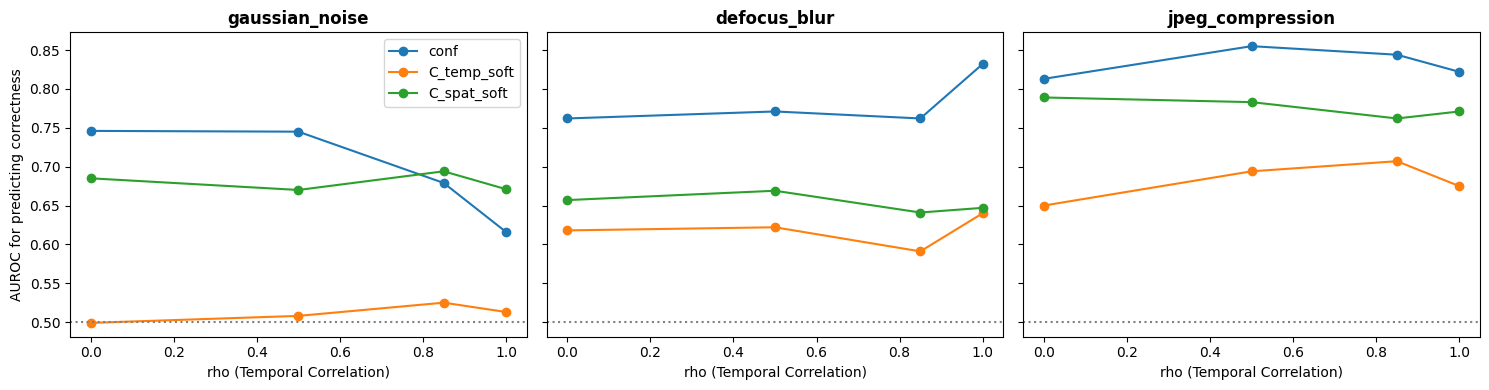

In [25]:
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# 1. Define the 3 corruptions explicitly
P3_CORRS = ['gaussian_noise', 'defocus_blur', 'jpeg_compression']

INPUT_CSV = '/kaggle/working/phase3_signals_v2.csv'
if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(f'{INPUT_CSV} is missing. Run Phase 3 v2 first.')
d = pd.read_csv(INPUT_CSV)
print(f'Phase 3 v2 loaded: {len(d)} rows, {d.video.nunique()} videos, {d.corruption.nunique()} corruption labels')
d['neg_entropy'] = -d.entropy
sigs = ['conf', 'neg_entropy', 'C_temp_soft', 'C_spat_soft', 'C_temp_hard', 'C_spat_hard', 'cos_ts']

def auc_row(g, **kw):
    row = dict(kw, acc=round(g.correct.mean()*100, 1), n=len(g))
    for s in sigs: 
        row[s] = round(roc_auc_score(g.correct, g[s]), 3)
    return row

print("CLEAN:", auc_row(d[d.corruption == 'clean'], corruption='clean'))
auc = pd.DataFrame([auc_row(g, corruption=c, rho=r) for (c, r), g in d[d.corruption != 'clean'].groupby(['corruption', 'rho'])
                    if g.correct.nunique() > 1])
print("\n", auc.to_string(index=False))

# 2. Plotting (now P3_CORRS is defined!)
fig, axes = plt.subplots(1, len(P3_CORRS), figsize=(15, 4), sharey=True)
for ax, c in zip(axes, P3_CORRS):
    a = auc[auc.corruption == c]
    for s in ['conf', 'C_temp_soft', 'C_spat_soft']: 
        ax.plot(a.rho, a[s], marker='o', label=s)
    ax.axhline(0.5, ls=':', c='gray')
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('rho (Temporal Correlation)')
axes[0].set_ylabel('AUROC for predicting correctness')
axes[0].legend()
plt.tight_layout()
plt.show()

signal                      C_spat_soft       C_temp_soft              conf
corruption       rho                                                       
defocus_blur     0.00  0.66 [0.60,0.71]  0.62 [0.56,0.68]  0.76 [0.71,0.80]
                 0.50  0.67 [0.62,0.72]  0.62 [0.56,0.68]  0.77 [0.72,0.82]
                 0.85  0.64 [0.59,0.70]  0.59 [0.53,0.64]  0.76 [0.71,0.80]
                 1.00  0.65 [0.59,0.71]  0.64 [0.58,0.70]  0.83 [0.79,0.88]
gaussian_noise   0.00  0.68 [0.62,0.75]  0.50 [0.43,0.57]  0.75 [0.69,0.80]
                 0.50  0.67 [0.60,0.73]  0.51 [0.43,0.58]  0.74 [0.68,0.80]
                 0.85  0.69 [0.63,0.76]  0.53 [0.46,0.59]  0.68 [0.63,0.73]
                 1.00  0.67 [0.61,0.73]  0.51 [0.45,0.58]  0.62 [0.56,0.68]
jpeg_compression 0.00  0.79 [0.74,0.83]  0.65 [0.60,0.70]  0.81 [0.77,0.85]
                 0.50  0.78 [0.73,0.83]  0.69 [0.64,0.75]  0.86 [0.82,0.89]
                 0.85  0.76 [0.72,0.80]  0.71 [0.65,0.76]  0.84 [0.80,0.88]
            

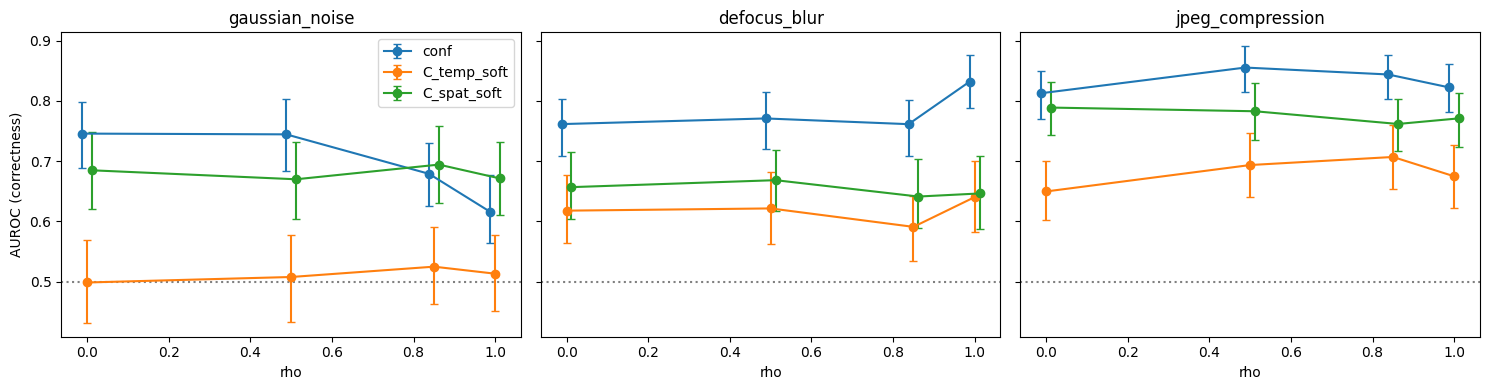

In [26]:
sig3 = ['conf', 'C_temp_soft', 'C_spat_soft']
rng = np.random.default_rng(0)
out = []
for (c, r), g in d[d.corruption != 'clean'].groupby(['corruption', 'rho']):
    y = g.correct.values
    for s in sig3:
        x, bs = g[s].values, []
        for _ in range(500):
            i = rng.integers(0, len(y), len(y))
            if y[i].min() != y[i].max(): bs.append(roc_auc_score(y[i], x[i]))
        if not bs:
            continue
        lo, hi = np.percentile(bs, [2.5, 97.5])
        out.append(dict(corruption=c, rho=r, signal=s, auc=roc_auc_score(y, x), lo=lo, hi=hi))
ci = pd.DataFrame(out)
ci['txt'] = ci.apply(lambda r: f"{r.auc:.2f} [{r.lo:.2f},{r.hi:.2f}]", axis=1)
print(ci.pivot_table(index=['corruption', 'rho'], columns='signal', values='txt', aggfunc='first').to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, P3_CORRS):
    for k, s in enumerate(sig3):
        a = ci[(ci.corruption == c) & (ci.signal == s)]
        ax.errorbar(a.rho + 0.012*(k-1), a.auc, yerr=[a.auc - a.lo, a.hi - a.auc], marker='o', capsize=3, label=s)
    ax.axhline(0.5, ls=':', c='gray'); ax.set_title(c); ax.set_xlabel('rho')
axes[0].set_ylabel('AUROC (correctness)'); axes[0].legend(); plt.tight_layout(); plt.show()

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

fsets = {'conf only': ['conf'], '+C_temp': ['conf', 'C_temp_soft'], '+C_spat': ['conf', 'C_spat_soft'],
         'conf+both': ['conf', 'C_temp_soft', 'C_spat_soft'],
         'all': ['conf', 'neg_entropy', 'C_temp_soft', 'C_spat_soft', 'C_temp_hard', 'C_spat_hard', 'cos_ts']}
rows = []
for (c, r), g in d[d.corruption != 'clean'].groupby(['corruption', 'rho']):
    y = g.correct.values
    if y.sum() < 20 or (len(y) - y.sum()) < 20: continue
    row = dict(corruption=c, rho=r)
    for name, cols in fsets.items():
        pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
        p = cross_val_predict(pipe, g[cols].values, y, cv=StratifiedKFold(5, shuffle=True, random_state=0),
                              method='predict_proba')[:, 1]
        row[name] = round(roc_auc_score(y, p), 3)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))


      corruption  rho  conf only  +C_temp  +C_spat  conf+both   all
    defocus_blur 0.00      0.757    0.774    0.753      0.772 0.771
    defocus_blur 0.50      0.770    0.780    0.768      0.777 0.767
    defocus_blur 0.85      0.756    0.772    0.757      0.773 0.763
    defocus_blur 1.00      0.830    0.844    0.829      0.843 0.849
  gaussian_noise 0.00      0.740    0.755    0.729      0.747 0.776
  gaussian_noise 0.50      0.733    0.751    0.729      0.743 0.801
  gaussian_noise 0.85      0.679    0.692    0.697      0.717 0.802
  gaussian_noise 1.00      0.615    0.632    0.655      0.668 0.721
jpeg_compression 0.00      0.811    0.813    0.826      0.828 0.835
jpeg_compression 0.50      0.854    0.855    0.853      0.853 0.863
jpeg_compression 0.85      0.843    0.843    0.836      0.836 0.842
jpeg_compression 1.00      0.820    0.820    0.826      0.825 0.826


In [25]:
# ============================================================
# PHASE 3 EXTENSION — Complete the missing consistency signals
#
# Original Phase 3 data:  5,200 rows (preserved)
# Missing conditions:    28 per video
# New rows expected:     11,200
# Final rows expected:   16,400
#
# Saves a resumable checkpoint every 10 completed videos.
# Creates downloadable recovery ZIPs every 50 videos.
# Does not repeat the existing 13 conditions.
# ============================================================

import os
import glob
import io
import re
import json
import time
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
from PIL import Image
from decord import VideoReader, cpu
from IPython.display import FileLink, display

# ------------------------------------------------------------
# 1. Paths and fixed experiment configuration
# ------------------------------------------------------------

DATASET_DIR = "/kaggle/input/datasets/faizz106/afml-final"
ROOT = "/kaggle/working"

VIDEO_LIST = f"{DATASET_DIR}/test_videos.txt"
BASE_CSV = f"{DATASET_DIR}/phase3_signals_v2.csv"
BASE_NPY = f"{DATASET_DIR}/phase3_probs_v2.npy"

# Preserve the original results as immutable baselines.
BASE_CSV_COPY = f"{ROOT}/phase3_signals_v2_base_5200.csv"
BASE_NPY_COPY = f"{ROOT}/phase3_probs_v2_base_5200.npy"

# New condition results only; these are resumable.
EXT_CHECKPOINT = f"{ROOT}/phase3_extension_checkpoint.npz"

# Full Phase 3 dataset after the extension completes.
FULL_CSV = f"{ROOT}/phase3_signals_full_v2.csv"
FULL_NPY = f"{ROOT}/phase3_probs_full_v2.npy"

SAVE_EVERY = 10
ZIP_EVERY = 50

M = 4
K = 4
RHOS = [0.0, 0.5, 0.85, 1.0]

ALL_CORRUPTIONS = [
    "gaussian_noise",
    "defocus_blur",
    "jpeg_compression",
    "motion_blur",
    "brightness_shift",
]

# Existing Phase 3 already contains clean plus severity-5
# Gaussian noise, defocus blur, and JPEG compression.
BASE_CONDS = (
    {("clean", 0, None)}
    | {
        (c, 5, float(rho))
        for c in (
            "gaussian_noise",
            "defocus_blur",
            "jpeg_compression",
        )
        for rho in RHOS
    }
)

# Add severity 3 for all five corruptions,
# and severity 5 for motion blur and brightness shift.
EXT_CONDS = (
    [
        (c, 3, float(rho))
        for c in ALL_CORRUPTIONS
        for rho in RHOS
    ]
    +
    [
        (c, 5, float(rho))
        for c in ("motion_blur", "brightness_shift")
        for rho in RHOS
    ]
)

EXT_COND_KEYS = set(EXT_CONDS)
FULL_COND_KEYS = BASE_CONDS | EXT_COND_KEYS

assert len(BASE_CONDS) == 13
assert len(EXT_CONDS) == 28
assert len(FULL_COND_KEYS) == 41

for path in (VIDEO_LIST, BASE_CSV, BASE_NPY):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required input missing: {path}")

# ------------------------------------------------------------
# 2. Load and validate the original dataset and video manifest
# ------------------------------------------------------------

with open(VIDEO_LIST) as f:
    test_videos = [line.strip() for line in f if line.strip()]

if len(test_videos) != 400:
    raise ValueError(f"Expected 400 listed videos, got {len(test_videos)}")

missing_paths = [p for p in test_videos if not os.path.isfile(p)]
if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} videos cannot be accessed. "
        f"First missing path: {missing_paths[0]}"
    )

base_df = pd.read_csv(BASE_CSV)
base_probs = np.load(BASE_NPY, mmap_mode="r")

if len(base_df) != 5200:
    raise ValueError(
        f"Expected original 5,200 rows, got {len(base_df)}"
    )

if base_df["video"].nunique() != 400:
    raise ValueError("Original Phase 3 CSV must contain 400 videos.")

if base_probs.ndim != 3 or base_probs.shape[0] != len(base_df):
    raise ValueError(
        "The probability array is inconsistent with the original CSV: "
        f"{base_probs.shape} versus {len(base_df)} rows."
    )

if base_probs.shape[1] != 8:
    raise ValueError(
        f"Expected 8 probability vectors per condition, got "
        f"{base_probs.shape[1]}."
    )

# Save a persistent local copy of the exact original data.
shutil.copy2(BASE_CSV, BASE_CSV_COPY)
shutil.copy2(BASE_NPY, BASE_NPY_COPY)
shutil.copy2(VIDEO_LIST, f"{ROOT}/phase3_test_videos_used.txt")

def condition_key(row):
    corruption = str(row["corruption"])
    severity = int(row["severity"])
    rho = None if pd.isna(row["rho"]) else round(float(row["rho"]), 2)
    return (corruption, severity, rho)

expected_names = {os.path.basename(p) for p in test_videos}

if set(base_df["video"].astype(str)) != expected_names:
    raise ValueError(
        "The existing Phase 3 videos do not match test_videos.txt."
    )

# Every original video must have exactly the 13 expected base conditions.
for video, group in base_df.groupby("video"):
    keys = {condition_key(row) for _, row in group.iterrows()}
    if len(group) != 13 or keys != BASE_CONDS:
        raise ValueError(
            f"Original results are incomplete or duplicated for {video}."
        )

print("✅ Original Phase 3 dataset validated.")
print("Original rows:", len(base_df))
print("Original videos:", base_df["video"].nunique())
print("Missing conditions per video:", len(EXT_CONDS))
print("Expected additional rows:", 400 * len(EXT_CONDS))
print("Expected final rows:", 400 * len(FULL_COND_KEYS))

# ------------------------------------------------------------
# 3. Check dependencies BEFORE any video inference
# ------------------------------------------------------------

required_globals = [
    "model",
    "processor",
    "to224",
    "corrupt_video",
]

missing_globals = [
    name for name in required_globals
    if name not in globals()
    or (name in ("model", "processor", "to224", "corrupt_video")
        and globals()[name] is None)
]

if missing_globals:
    raise RuntimeError(
        "No videos have been processed by this cell yet, but these "
        f"setup dependencies are missing: {missing_globals}\n"
        "Run the existing Setup Cell to load the model and corruption "
        "functions, then rerun this extension cell."
    )

model.eval()
device = next(model.parameters()).device

label2id = getattr(model.config, "label2id", None)
if not label2id:
    label2id = {
        label: int(index)
        for index, label in model.config.id2label.items()
    }

for path in test_videos:
    gt = path.split("/")[-2]
    if gt not in label2id:
        raise ValueError(
            f"Ground-truth label {gt!r} is absent from the model label map."
        )

print("✅ Setup dependencies and ground-truth labels validated.")
print("Model device:", device)
print("Number of model labels:", model.config.num_labels)

# ------------------------------------------------------------
# 4. Define the same Phase 3 feature extraction operations
# ------------------------------------------------------------

def load_segments(path, M=4, n=16):
    """Sample 16 frames from each of four temporal segments."""
    vr = VideoReader(path, ctx=cpu(0))
    T = len(vr)

    idx = []
    for m in range(M):
        lo = int(T * m / M)
        hi = max(int(T * (m + 1) / M) - 1, lo)
        idx += list(np.linspace(lo, hi, n).astype(int))

    return to224([f for f in vr.get_batch(idx).asnumpy()])


@torch.no_grad()
def probs_of(clips):
    """Process 8 clips together: 4 temporal and 4 spatial."""
    x = torch.cat([
        processor(c, return_tensors="pt")["pixel_values"]
        for c in clips
    ]).to(device)

    logits = model(pixel_values=x).logits
    return torch.softmax(logits, -1).cpu().numpy()


def augment_clip(clip, rng):
    """Same randomized spatial augmentation used in Phase 3."""
    side = int(224 * np.sqrt(rng.uniform(0.6, 1.0)))
    y = rng.integers(0, 224 - side + 1)
    x = rng.integers(0, 224 - side + 1)
    flip = rng.random() < 0.5

    out = [
        cv2.resize(
            frame[y:y + side, x:x + side],
            (224, 224)
        )
        for frame in clip
    ]

    return [f[:, ::-1].copy() for f in out] if flip else out


def jsd_consistency(P):
    H = lambda p: -(p * np.log(p + 1e-12)).sum(-1)
    return float(
        1 - (H(P.mean(0)) - H(P).mean()) / np.log(len(P))
    )


def vote_consistency(P):
    return float(np.bincount(P.argmax(1)).max() / len(P))


def extract_signals(Pt, Ps, gt_idx):
    pt, ps = Pt.mean(0), Ps.mean(0)
    yhat = int(pt.argmax())

    return {
        "pred": yhat,
        "correct": int(yhat == gt_idx),
        "conf": float(pt.max()),
        "entropy": float(-(pt * np.log(pt + 1e-12)).sum()),
        "C_temp_soft": jsd_consistency(Pt),
        "C_temp_hard": vote_consistency(Pt),
        "C_spat_soft": jsd_consistency(Ps),
        "C_spat_hard": vote_consistency(Ps),
        "cos_ts": float(
            pt @ ps
            / (np.linalg.norm(pt) * np.linalg.norm(ps) + 1e-12)
        ),
    }


# ------------------------------------------------------------
# 5. Resume from the latest extension checkpoint, if present
# ------------------------------------------------------------

ext_rows = []
ext_probs = []

n_classes = int(base_probs.shape[-1])

if os.path.isfile(EXT_CHECKPOINT):
    with np.load(EXT_CHECKPOINT, allow_pickle=False) as z:
        ext_rows = json.loads(str(z["rows_json"].item()))
        loaded_probs = np.asarray(z["probs"], dtype=np.float16)

    if loaded_probs.ndim != 3 or loaded_probs.shape[1:] != (8, n_classes):
        raise ValueError(
            "Saved extension checkpoint has an unexpected probability shape: "
            f"{loaded_probs.shape}"
        )

    if len(loaded_probs) != len(ext_rows):
        raise ValueError(
            "Checkpoint CSV rows and probability arrays do not match."
        )

    # Keep only videos whose complete block of 28 conditions is saved.
    groups = {}
    for i, row in enumerate(ext_rows):
        groups.setdefault(str(row["video"]), []).append((i, row))

    complete_videos = set()
    for video, items in groups.items():
        keys = {condition_key(row) for _, row in items}
        if len(items) == 28 and keys == EXT_COND_KEYS:
            complete_videos.add(video)

    keep_indices = [
        i for i, row in enumerate(ext_rows)
        if str(row["video"]) in complete_videos
    ]

    if len(keep_indices) != len(ext_rows):
        print(
            "Removing incomplete checkpoint blocks so they can be rerun."
        )
        ext_rows = [ext_rows[i] for i in keep_indices]
        loaded_probs = loaded_probs[keep_indices]

    ext_probs = list(loaded_probs)

    print("Resuming completed videos:", len(complete_videos))
else:
    complete_videos = set()
    print("Starting the Phase 3 extension from zero completed videos.")

# Recompute completed IDs from the rows actually retained.
complete_videos = {
    str(row["video"])
    for row in ext_rows
}

def save_extension_checkpoint():
    """Atomically save rows and probabilities together."""
    arr = (
        np.stack(ext_probs).astype(np.float16)
        if ext_probs
        else np.empty((0, 8, n_classes), dtype=np.float16)
    )

    tmp = f"{ROOT}/.phase3_extension_checkpoint.tmp.npz"

    np.savez(
        tmp,
        rows_json=np.array(json.dumps(ext_rows)),
        probs=arr,
        completed_videos=np.array(sorted(complete_videos), dtype=str),
    )

    os.replace(tmp, EXT_CHECKPOINT)


def create_progress_zip(completed_count):
    """Create a downloadable recovery checkpoint."""
    stamp = time.strftime("%Y%m%d_%H%M%S")
    zip_path = (
        f"{ROOT}/AFML_Phase3_Extension_{stamp}_"
        f"{completed_count:03d}of400.zip"
    )

    progress = {
        "completed_videos": int(completed_count),
        "target_videos": 400,
        "conditions_per_video": 28,
        "expected_extension_rows": int(completed_count * 28),
        "original_rows": 5200,
        "expected_final_rows": 16400,
        "checkpoint_file": os.path.basename(EXT_CHECKPOINT),
    }

    progress_path = f"{ROOT}/phase3_extension_progress.json"
    with open(progress_path, "w") as f:
        json.dump(progress, f, indent=2)

    with zipfile.ZipFile(
        zip_path, "w", zipfile.ZIP_DEFLATED
    ) as zf:
        for p in (
            BASE_CSV_COPY,
            BASE_NPY_COPY,
            EXT_CHECKPOINT,
            f"{ROOT}/phase3_test_videos_used.txt",
            progress_path,
        ):
            if os.path.isfile(p):
                zf.write(p, arcname=os.path.basename(p))

    print("Recovery checkpoint:", zip_path)
    display(FileLink(zip_path))


# ------------------------------------------------------------
# 6. Process only missing conditions
# ------------------------------------------------------------

newly_completed = 0
t0 = time.time()

for v_idx, path in enumerate(test_videos):
    video_name = os.path.basename(path)

    if video_name in complete_videos:
        continue

    gt = path.split("/")[-2]
    gt_id = int(label2id[gt])

    # All new rows stay local until this video's full set succeeds.
    rows_for_video = []
    probs_for_video = []

    try:
        frames = load_segments(path, M=M, n=16)

        for corruption, severity, rho in EXT_CONDS:
            seq = corrupt_video(
                frames,
                corruption,
                severity,
                rho,
                seed=v_idx,
            )

            clips = [
                seq[m * 16:(m + 1) * 16]
                for m in range(M)
            ]

            # Match existing Phase 3 augmentation randomness.
            arng = np.random.default_rng(v_idx)
            spatial_augs = [
                augment_clip(clips[1], arng)
                for _ in range(K)
            ]

            P = probs_of(clips + spatial_augs)

            if P.shape != (8, n_classes):
                raise ValueError(
                    f"Unexpected probability shape {P.shape}"
                )

            row = extract_signals(
                P[:M],
                P[M:],
                gt_id,
            )

            row.update({
                "video": video_name,
                "gt": gt,
                "corruption": corruption,
                "severity": int(severity),
                "rho": float(rho),
            })

            rows_for_video.append(row)
            probs_for_video.append(P.astype(np.float16))

        # Do not save partial video blocks.
        if len(rows_for_video) != 28 or len(probs_for_video) != 28:
            raise RuntimeError(
                f"{video_name}: expected 28 new condition results."
            )

        ext_rows.extend(rows_for_video)
        ext_probs.extend(probs_for_video)
        complete_videos.add(video_name)
        newly_completed += 1

        if newly_completed % SAVE_EVERY == 0:
            save_extension_checkpoint()
            elapsed = (time.time() - t0) / 60

            print(
                f"Extension progress: {len(complete_videos)}/400 videos | "
                f"{len(ext_rows)} new rows | "
                f"{elapsed:.1f} minutes elapsed"
            )

        if len(complete_videos) % ZIP_EVERY == 0:
            save_extension_checkpoint()
            create_progress_zip(len(complete_videos))

    except Exception as e:
        # Preserve every fully completed video before stopping.
        save_extension_checkpoint()

        print(
            f"\nERROR on {video_name}: {type(e).__name__}: {e}"
        )
        print(
            "Completed video blocks have been checkpointed. "
            "Fix the error, then rerun this same cell to resume."
        )
        raise

# Always save the latest complete extension.
save_extension_checkpoint()

if len(complete_videos) != 400:
    raise RuntimeError(
        f"Extension incomplete: {len(complete_videos)}/400 videos."
    )

if len(ext_rows) != 11200 or len(ext_probs) != 11200:
    raise RuntimeError(
        f"Expected 11,200 extension results, got "
        f"{len(ext_rows)} rows and {len(ext_probs)} probability arrays."
    )

print("\n✅ All 400 videos have all 28 additional condition results.")

# ------------------------------------------------------------
# 7. Merge extension with original data and validate all 41
#    conditions per video
# ------------------------------------------------------------

extension_df = pd.DataFrame(ext_rows)

full_df = pd.concat(
    [base_df, extension_df],
    ignore_index=True,
)

if len(full_df) != 16400:
    raise ValueError(f"Expected 16,400 merged rows, got {len(full_df)}")

if full_df.duplicated(
    subset=["video", "corruption", "severity", "rho"]
).any():
    raise ValueError("Duplicate video-condition rows found after merging.")

for video, group in full_df.groupby("video"):
    keys = {condition_key(row) for _, row in group.iterrows()}

    if len(group) != 41 or keys != FULL_COND_KEYS:
        raise ValueError(
            f"Full condition coverage failed for {video}: "
            f"{len(group)} rows and {len(keys)} unique conditions."
        )

# Probability arrays remain aligned with their corresponding CSV rows.
extension_probs_array = np.stack(ext_probs).astype(np.float16)
full_probs = np.concatenate(
    [np.asarray(base_probs, dtype=np.float16), extension_probs_array],
    axis=0,
)

if full_probs.shape != (16400, 8, n_classes):
    raise ValueError(
        f"Unexpected merged probability shape: {full_probs.shape}"
    )

# Save to explicit full-data filenames first.
csv_tmp = f"{ROOT}/.phase3_signals_full_v2.tmp.csv"
npy_tmp = f"{ROOT}/.phase3_probs_full_v2.tmp.npy"

full_df.to_csv(csv_tmp, index=False)
np.save(npy_tmp, full_probs)

os.replace(csv_tmp, FULL_CSV)
os.replace(npy_tmp, FULL_NPY)

# Keep the expected filenames for downstream Phase 4 cells.
# The original 5,200-row baseline remains separately preserved.
shutil.copy2(FULL_CSV, f"{ROOT}/phase3_signals_v2.csv")
shutil.copy2(FULL_NPY, f"{ROOT}/phase3_probs_v2.npy")

# ------------------------------------------------------------
# 8. Make the final downloadable Phase 3 checkpoint
# ------------------------------------------------------------

stamp = time.strftime("%Y%m%d_%H%M%S")
FINAL_ZIP = f"{ROOT}/AFML_Phase3_Full_Checkpoint_{stamp}.zip"
MANIFEST = f"{ROOT}/phase3_full_manifest.json"

manifest = {
    "phase": 3,
    "status": "complete",
    "original_rows_preserved": 5200,
    "extension_rows": 11200,
    "total_rows": int(len(full_df)),
    "unique_videos": int(full_df["video"].nunique()),
    "conditions_per_video": 41,
    "condition_keys": len(FULL_COND_KEYS),
    "probability_array_shape": list(full_probs.shape),
    "video_split_file": os.path.basename(VIDEO_LIST),
    "note": (
        "Extended signal matrix. Phase 4 must be retrained and "
        "evaluated using this full 16,400-row dataset."
    ),
}

with open(MANIFEST, "w") as f:
    json.dump(manifest, f, indent=2)

files_to_zip = [
    BASE_CSV_COPY,
    BASE_NPY_COPY,
    FULL_CSV,
    FULL_NPY,
    EXT_CHECKPOINT,
    f"{ROOT}/phase3_test_videos_used.txt",
    MANIFEST,
]

with zipfile.ZipFile(
    FINAL_ZIP, "w", zipfile.ZIP_DEFLATED
) as zf:
    for p in files_to_zip:
        zf.write(p, arcname=os.path.basename(p))

print("\n" + "=" * 65)
print("✅ PHASE 3 EXTENSION COMPLETE")
print("=" * 65)
print("Original rows preserved:", len(base_df))
print("New rows:", len(extension_df))
print("Total Phase 3 rows:", len(full_df))
print("Videos:", full_df["video"].nunique())
print("Conditions per video:", 41)
print("Probability array shape:", full_probs.shape)
print("Full CSV:", FULL_CSV)
print("Full probabilities:", FULL_NPY)
print("Final checkpoint ZIP:", FINAL_ZIP)
print(
    "ZIP size: %.2f MB"
    % (os.path.getsize(FINAL_ZIP) / (1024 ** 2))
)
display(FileLink(FINAL_ZIP))

✅ Original Phase 3 dataset validated.
Original rows: 5200
Original videos: 400
Missing conditions per video: 28
Expected additional rows: 11200
Expected final rows: 16400
✅ Setup dependencies and ground-truth labels validated.
Model device: cuda:0
Number of model labels: 101
Starting the Phase 3 extension from zero completed videos.
Extension progress: 10/400 videos | 280 new rows | 6.5 minutes elapsed
Extension progress: 20/400 videos | 560 new rows | 13.0 minutes elapsed
Extension progress: 30/400 videos | 840 new rows | 19.4 minutes elapsed
Extension progress: 40/400 videos | 1120 new rows | 25.9 minutes elapsed
Extension progress: 50/400 videos | 1400 new rows | 32.5 minutes elapsed
Recovery checkpoint: /kaggle/working/AFML_Phase3_Extension_20261025_083908_050of400.zip


/kaggle/working/AFML_Phase3_Extension_20261025_083908_050of400.zip

Extension progress: 60/400 videos | 1680 new rows | 39.0 minutes elapsed
Extension progress: 70/400 videos | 1960 new rows | 45.6 minutes elapsed
Extension progress: 80/400 videos | 2240 new rows | 52.0 minutes elapsed
Extension progress: 90/400 videos | 2520 new rows | 58.5 minutes elapsed
Extension progress: 100/400 videos | 2800 new rows | 64.9 minutes elapsed
Recovery checkpoint: /kaggle/working/AFML_Phase3_Extension_20261025_091130_100of400.zip


/kaggle/working/AFML_Phase3_Extension_20261025_091130_100of400.zip

Extension progress: 110/400 videos | 3080 new rows | 71.0 minutes elapsed
Extension progress: 120/400 videos | 3360 new rows | 77.3 minutes elapsed
Extension progress: 130/400 videos | 3640 new rows | 83.7 minutes elapsed
Extension progress: 140/400 videos | 3920 new rows | 89.9 minutes elapsed
Extension progress: 150/400 videos | 4200 new rows | 96.0 minutes elapsed
Recovery checkpoint: /kaggle/working/AFML_Phase3_Extension_20261025_094238_150of400.zip


/kaggle/working/AFML_Phase3_Extension_20261025_094238_150of400.zip

... (8 outputs left out)

Extension progress: 360/400 videos | 10080 new rows | 229.4 minutes elapsed
Extension progress: 370/400 videos | 10360 new rows | 235.8 minutes elapsed
Extension progress: 380/400 videos | 10640 new rows | 242.2 minutes elapsed
Extension progress: 390/400 videos | 10920 new rows | 248.6 minutes elapsed
Extension progress: 400/400 videos | 11200 new rows | 255.0 minutes elapsed
Recovery checkpoint: /kaggle/working/AFML_Phase3_Extension_20261025_122136_400of400.zip


/kaggle/working/AFML_Phase3_Extension_20261025_122136_400of400.zip


✅ All 400 videos have all 28 additional condition results.

✅ PHASE 3 EXTENSION COMPLETE
Original rows preserved: 5200
New rows: 11200
Total Phase 3 rows: 16400
Videos: 400
Conditions per video: 41
Probability array shape: (16400, 8, 101)
Full CSV: /kaggle/working/phase3_signals_full_v2.csv
Full probabilities: /kaggle/working/phase3_probs_full_v2.npy
Final checkpoint ZIP: /kaggle/working/AFML_Phase3_Full_Checkpoint_20261025_122139.zip
ZIP size: 46.76 MB


/kaggle/working/AFML_Phase3_Full_Checkpoint_20261025_122139.zip

In [26]:
import os
import numpy as np
import pandas as pd

ROOT = "/kaggle/working"
CSV_PATH = f"{ROOT}/phase3_signals_full_v2.csv"
NPY_PATH = f"{ROOT}/phase3_probs_full_v2.npy"

assert os.path.isfile(CSV_PATH), f"Missing {CSV_PATH}"
assert os.path.isfile(NPY_PATH), f"Missing {NPY_PATH}"

df = pd.read_csv(CSV_PATH)
probs = np.load(NPY_PATH, mmap_mode="r")

assert len(df) == 16400
assert df["video"].nunique() == 400
assert probs.shape == (16400, 8, 101)

# Expected conditions: clean + 5 corruptions × 2 severities × 4 rho values
corruptions = [
    "gaussian_noise",
    "defocus_blur",
    "motion_blur",
    "jpeg_compression",
    "brightness_shift",
]
rhos = [0.0, 0.5, 0.85, 1.0]

expected = {("clean", 0, None)}
expected |= {
    (c, severity, rho)
    for c in corruptions
    for severity in (3, 5)
    for rho in rhos
}

def key(row):
    rho = None if pd.isna(row["rho"]) else round(float(row["rho"]), 2)
    return (str(row["corruption"]), int(row["severity"]), rho)

assert len(expected) == 41

for video, group in df.groupby("video"):
    conditions = {key(row) for _, row in group.iterrows()}
    assert len(group) == 41, f"{video}: wrong row count"
    assert conditions == expected, f"{video}: missing or extra conditions"

counts = df.groupby(
    ["corruption", "severity", "rho"],
    dropna=False
).size()

assert len(counts) == 41
assert (counts == 400).all()

print("✅ Expanded Phase 3 data validation passed")
print("Rows:", len(df))
print("Videos:", df["video"].nunique())
print("Conditions:", len(counts))
print("Rows per condition:", sorted(counts.unique()))
print("Probability shape:", probs.shape)

✅ Expanded Phase 3 data validation passed
Rows: 16400
Videos: 400
Conditions: 41
Rows per condition: [np.int64(400)]
Probability shape: (16400, 8, 101)


✅ Expanded Phase 3 matrix validated
Rows: 16400
Unique videos: 400
Conditions per video: 41

✅ Per-condition signal evaluation saved
AUROC/AUPRC rows: 41
Bootstrap CI rows: 123

Core-signal AUROC sample:
      corruption  severity  rho   n  conf_AUROC  C_temp_soft_AUROC  C_spat_soft_AUROC
brightness_shift         3 0.00 400       0.837              0.686              0.786
brightness_shift         3 0.50 400       0.830              0.705              0.788
brightness_shift         3 0.85 400       0.837              0.711              0.780
brightness_shift         3 1.00 400       0.826              0.725              0.780
brightness_shift         5 0.00 400       0.796              0.633              0.709
brightness_shift         5 0.50 400       0.827              0.679              0.733
brightness_shift         5 0.85 400       0.822              0.688              0.726
brightness_shift         5 1.00 400       0.835              0.707              0.777
           clean      

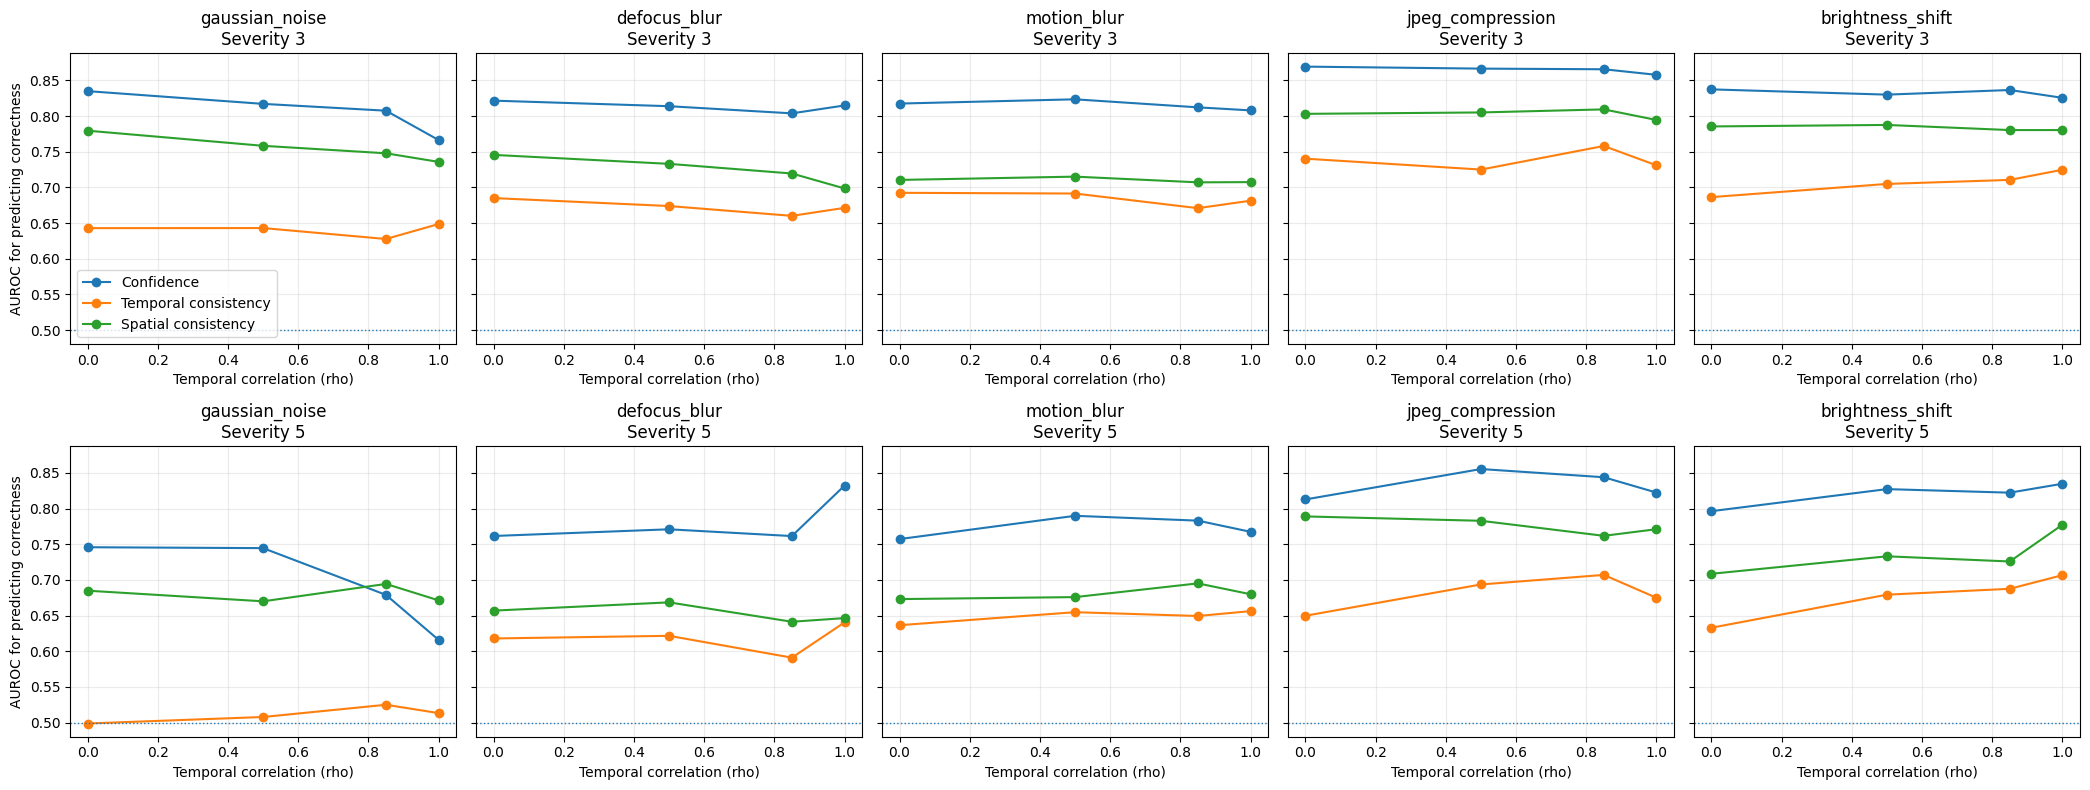


✅ FULL PHASE 3 ANALYSIS COMPLETE
AUROC/AUPRC table: /kaggle/working/phase3_condition_auroc_full_v2.csv
Confidence intervals: /kaggle/working/phase3_auroc_ci_full_v2.csv
Feature comparison: /kaggle/working/phase3_feature_comparison_full_v2.csv
Plot: /kaggle/working/phase3_full_signal_auroc_plot.png
Checkpoint ZIP: /kaggle/working/AFML_Phase3_Full_Analysis_20261025_140727.zip
ZIP size: 1.13 MB


/kaggle/working/AFML_Phase3_Full_Analysis_20261025_140727.zip

In [5]:
# ============================================================
# PHASE 3 — FULL MATRIX ANALYSIS (v2)
# Input: 16,400 rows, 400 videos, 41 conditions per video
#
# Outputs:
#   phase3_condition_auroc_full_v2.csv
#   phase3_auroc_ci_full_v2.csv
#   phase3_feature_comparison_full_v2.csv
#   phase3_full_signal_auroc_plot.png
#   AFML_Phase3_Full_Analysis_<timestamp>.zip
#
# No video inference. No GPU model loading.
# ============================================================

import os
import json
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from IPython.display import FileLink, display

ROOT = "/kaggle/working"
INPUT_CSV = f"{ROOT}/phase3_signals_full_v2.csv"

# ------------------------------------------------------------
# 1. Load and validate the expanded Phase 3 data
# ------------------------------------------------------------

if not os.path.isfile(INPUT_CSV):
    raise FileNotFoundError(
        f"Missing {INPUT_CSV}. Restore the Phase 3 full checkpoint first."
    )

d = pd.read_csv(INPUT_CSV)

required = {
    "video", "gt", "corruption", "severity", "rho",
    "correct", "conf", "entropy",
    "C_temp_soft", "C_temp_hard",
    "C_spat_soft", "C_spat_hard", "cos_ts"
}
missing = required - set(d.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

assert len(d) == 16400, f"Expected 16,400 rows, got {len(d)}"
assert d["video"].nunique() == 400
assert d.groupby("video").size().eq(41).all()

corruptions = [
    "gaussian_noise",
    "defocus_blur",
    "motion_blur",
    "jpeg_compression",
    "brightness_shift",
]
rhos = [0.0, 0.5, 0.85, 1.0]

expected_conditions = {("clean", 0, None)}
expected_conditions |= {
    (c, severity, rho)
    for c in corruptions
    for severity in (3, 5)
    for rho in rhos
}

def condition_key(row):
    rho = None if pd.isna(row["rho"]) else round(float(row["rho"]), 2)
    return (str(row["corruption"]), int(row["severity"]), rho)

for video, group in d.groupby("video"):
    keys = {condition_key(row) for _, row in group.iterrows()}
    if len(group) != 41 or keys != expected_conditions:
        raise ValueError(
            f"Condition coverage is incorrect for video {video}"
        )

d["correct"] = d["correct"].astype(int)
if not set(d["correct"].unique()).issubset({0, 1}):
    raise ValueError("The correct column must be binary 0/1.")

d["neg_entropy"] = -d["entropy"]

signals = [
    "conf",
    "neg_entropy",
    "C_temp_soft",
    "C_temp_hard",
    "C_spat_soft",
    "C_spat_hard",
    "cos_ts",
]
core_signals = ["conf", "C_temp_soft", "C_spat_soft"]

if d[signals].isna().any().any():
    raise ValueError("Missing signal values found; inspect data first.")

print("✅ Expanded Phase 3 matrix validated")
print("Rows:", len(d))
print("Unique videos:", d["video"].nunique())
print("Conditions per video:", 41)

# ------------------------------------------------------------
# 2. Per-condition AUROC and AUPRC
# ------------------------------------------------------------

N_BOOT = 400
rng = np.random.default_rng(20261025)

auc_rows = []
ci_rows = []

for (corr, severity, rho), g in d.groupby(
    ["corruption", "severity", "rho"],
    dropna=False,
    sort=True
):
    y = g["correct"].to_numpy(dtype=int)

    row = {
        "corruption": corr,
        "severity": int(severity),
        "rho": float(rho) if pd.notna(rho) else np.nan,
        "n": len(g),
        "accuracy_pct": float(y.mean() * 100),
    }

    for signal in signals:
        score = g[signal].to_numpy(dtype=float)

        if np.unique(y).size == 2:
            auc = float(roc_auc_score(y, score))
            auprc = float(average_precision_score(y, score))
        else:
            auc = np.nan
            auprc = np.nan

        row[f"{signal}_AUROC"] = auc
        row[f"{signal}_AUPRC"] = auprc

        # Bootstrap the core signals only to limit runtime.
        # Resampling is across videos within this condition.
        if signal in core_signals and np.isfinite(auc):
            boot = []

            for _ in range(N_BOOT):
                idx = rng.integers(0, len(g), size=len(g))
                y_b = y[idx]
                s_b = score[idx]

                if np.unique(y_b).size < 2:
                    continue

                boot.append(roc_auc_score(y_b, s_b))

            if boot:
                ci_low, ci_high = np.quantile(boot, [0.025, 0.975])
            else:
                ci_low, ci_high = np.nan, np.nan

            ci_rows.append({
                "corruption": corr,
                "severity": int(severity),
                "rho": float(rho) if pd.notna(rho) else np.nan,
                "signal": signal,
                "AUROC": auc,
                "CI_low": float(ci_low),
                "CI_high": float(ci_high),
                "n": len(g),
                "bootstrap_replicates": len(boot),
            })

    auc_rows.append(row)

auc_full = pd.DataFrame(auc_rows)
ci_full = pd.DataFrame(ci_rows)

AUC_PATH = f"{ROOT}/phase3_condition_auroc_full_v2.csv"
CI_PATH = f"{ROOT}/phase3_auroc_ci_full_v2.csv"

auc_full.to_csv(AUC_PATH, index=False)
ci_full.to_csv(CI_PATH, index=False)

print("\n✅ Per-condition signal evaluation saved")
print("AUROC/AUPRC rows:", len(auc_full))
print("Bootstrap CI rows:", len(ci_full))

print("\nCore-signal AUROC sample:")
print(
    auc_full[
        [
            "corruption", "severity", "rho", "n",
            "conf_AUROC", "C_temp_soft_AUROC", "C_spat_soft_AUROC"
        ]
    ].round(3).head(20).to_string(index=False)
)

# ------------------------------------------------------------
# 3. Compare feature combinations using video-level CV
# ------------------------------------------------------------
# GroupKFold keeps all rows from a video in one fold so conditions
# from the same video cannot leak between train and validation folds.
# This is an exploratory predictor comparison, not Phase 4's final
# 200/50/150 held-out evaluation.

y = d["correct"].to_numpy(dtype=int)
groups = d["video"].astype(str).to_numpy()

feature_sets = {
    "conf_only": ["conf"],
    "conf_temp_spatial": [
        "conf", "C_temp_soft", "C_spat_soft"
    ],
    "all_signals": [
        "conf", "neg_entropy",
        "C_temp_soft", "C_temp_hard",
        "C_spat_soft", "C_spat_hard", "cos_ts"
    ],
}

cv = GroupKFold(n_splits=5)
oof_scores = pd.DataFrame(index=d.index)
oof_scores["raw_conf"] = d["conf"].to_numpy(dtype=float)

for name, features in feature_sets.items():
    print(f"\nCross-validating: {name}")

    estimator = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    )

    pred = cross_val_predict(
        estimator,
        d[features],
        y,
        groups=groups,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )

    # Binary target is 0/1; probability column 1 is correctness.
    oof_scores[name] = pred[:, 1]

model_rows = []

for (corr, severity, rho), g in d.groupby(
    ["corruption", "severity", "rho"],
    dropna=False,
    sort=True
):
    idx = g.index
    target = g["correct"].to_numpy(dtype=int)

    for method in ["raw_conf", *feature_sets.keys()]:
        score = oof_scores.loc[idx, method].to_numpy(dtype=float)

        model_rows.append({
            "corruption": corr,
            "severity": int(severity),
            "rho": float(rho) if pd.notna(rho) else np.nan,
            "method": method,
            "n": len(g),
            "accuracy_pct": float(target.mean() * 100),
            "AUROC": (
                float(roc_auc_score(target, score))
                if np.unique(target).size == 2 else np.nan
            ),
            "AUPRC": (
                float(average_precision_score(target, score))
                if np.unique(target).size == 2 else np.nan
            ),
        })

model_comparison = pd.DataFrame(model_rows)

MODEL_PATH = f"{ROOT}/phase3_feature_comparison_full_v2.csv"
model_comparison.to_csv(MODEL_PATH, index=False)

macro = (
    model_comparison[model_comparison["corruption"] != "clean"]
    .groupby("method")[["AUROC", "AUPRC"]]
    .mean()
    .sort_values("AUROC", ascending=False)
)

print("\n✅ Feature comparison saved:", MODEL_PATH)
print("\nMacro-average across corrupted conditions:")
print(macro.round(4).to_string())

# ------------------------------------------------------------
# 4. Plot AUROC by corruption and severity
# ------------------------------------------------------------

plot_df = auc_full[auc_full["corruption"] != "clean"].copy()

fig, axes = plt.subplots(
    2, 5,
    figsize=(21, 8),
    sharey=True
)

plot_signals = [
    ("conf_AUROC", "Confidence"),
    ("C_temp_soft_AUROC", "Temporal consistency"),
    ("C_spat_soft_AUROC", "Spatial consistency"),
]

for row_i, severity in enumerate([3, 5]):
    for col_i, corruption in enumerate(corruptions):
        ax = axes[row_i, col_i]

        sub = plot_df[
            (plot_df["severity"] == severity)
            & (plot_df["corruption"] == corruption)
        ].sort_values("rho")

        for column, label in plot_signals:
            ax.plot(
                sub["rho"],
                sub[column],
                marker="o",
                label=label
            )

        ax.axhline(0.5, linestyle=":", linewidth=1)
        ax.set_title(f"{corruption}\nSeverity {severity}")
        ax.set_xlabel("Temporal correlation (rho)")

        if col_i == 0:
            ax.set_ylabel("AUROC for predicting correctness")

        ax.grid(alpha=0.25)

axes[0, 0].legend()
fig.tight_layout()

FIG_PATH = f"{ROOT}/phase3_full_signal_auroc_plot.png"
fig.savefig(FIG_PATH, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 5. Save a downloadable analysis checkpoint
# ------------------------------------------------------------

stamp = time.strftime("%Y%m%d_%H%M%S")
ZIP_PATH = f"{ROOT}/AFML_Phase3_Full_Analysis_{stamp}.zip"
MANIFEST_PATH = f"{ROOT}/phase3_full_analysis_manifest.json"

manifest = {
    "phase": 3,
    "input_file": os.path.basename(INPUT_CSV),
    "input_rows": int(len(d)),
    "unique_videos": int(d["video"].nunique()),
    "conditions_per_video": 41,
    "condition_auroc_rows": int(len(auc_full)),
    "condition_ci_rows": int(len(ci_full)),
    "feature_comparison_rows": int(len(model_comparison)),
    "cross_validation": "5-fold GroupKFold grouped by video",
    "bootstrap_replicates": N_BOOT,
    "note": (
        "Feature comparisons are exploratory. Phase 4 must be "
        "retrained using a fixed video-level 200/50/150 split."
    )
}

with open(MANIFEST_PATH, "w") as f:
    json.dump(manifest, f, indent=2)

files_to_zip = [
    INPUT_CSV,
    AUC_PATH,
    CI_PATH,
    MODEL_PATH,
    FIG_PATH,
    MANIFEST_PATH,
]

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zf:
    for path in files_to_zip:
        if os.path.isfile(path):
            zf.write(path, arcname=os.path.basename(path))

print("\n" + "=" * 65)
print("✅ FULL PHASE 3 ANALYSIS COMPLETE")
print("=" * 65)
print("AUROC/AUPRC table:", AUC_PATH)
print("Confidence intervals:", CI_PATH)
print("Feature comparison:", MODEL_PATH)
print("Plot:", FIG_PATH)
print("Checkpoint ZIP:", ZIP_PATH)
print(
    "ZIP size: %.2f MB"
    % (os.path.getsize(ZIP_PATH) / (1024 ** 2))
)

display(FileLink(ZIP_PATH))

---
<a id="section-4-phase-4--calibrated-multi-signal-reliability-estimator-head-the-referee"></a>
# Section 4: Phase 4 — Calibrated Multi-Signal Reliability Estimator Head (The Referee)

**Goal:** Combine multi-signal features into a single calibrated probability score $r(V) \in [0, 1]$ estimating prediction correctness.

$$\mathbf{u}(V) = [\text{conf},\; \text{neg\_entropy},\; C_{\text{temp\_soft}},\; C_{\text{spat\_soft}},\; C_{\text{temp\_hard}},\; C_{\text{spat\_hard}},\; \text{cos\_ts},\; \Delta C]^\top$$

* **Strict Video-Level Partitioning:** 200 Train / 50 Val / 150 Test videos (zero frame/video leakage).
* **Calibration:** Evaluated via Expected Calibration Error (ECE), Brier score, and Reliability Diagrams.
* **Out-of-Distribution Generalization:** Leave-One-Corruption-Out (LOCO) benchmarking.

In [29]:
# PHASE 4 — strict video-level split (train / validation / held-out test)
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import joblib
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

INPUT_CSV = "/kaggle/working/phase3_signals_v2.csv"
d = pd.read_csv(INPUT_CSV).copy()
required = {"video", "correct", "corruption", "rho", "conf", "entropy",
            "C_spat_soft", "C_temp_soft", "cos_ts"}
missing_cols = required - set(d.columns)
if missing_cols:
    raise ValueError(f"Phase 3 CSV missing required columns: {sorted(missing_cols)}")

d["neg_entropy"] = -d["entropy"]
d["dC"] = d["C_temp_soft"] - d["C_spat_soft"]

# Split by unique original video so all corruption variants stay together.
vids = np.array(sorted(d["video"].dropna().unique()))
rng = np.random.default_rng(42)
vids = rng.permutation(vids)
n = len(vids)
n_train, n_val = int(.50*n), int(.125*n)
train_v = set(vids[:n_train])
val_v = set(vids[n_train:n_train+n_val])
test_v = set(vids[n_train+n_val:])

assert not (train_v & val_v or train_v & test_v or val_v & test_v)
split_manifest = pd.DataFrame(
    [{'video': v, 'split': split} for split, group in
     [('train', train_v), ('validation', val_v), ('test', test_v)] for v in sorted(group)]
)
SPLIT_PATH = '/kaggle/working/phase4_video_split_v2.csv'
split_manifest.to_csv(SPLIT_PATH, index=False)
train = d[d.video.isin(train_v)].copy()
val = d[d.video.isin(val_v)].copy()
test = d[d.video.isin(test_v)].copy()
print(f"Videos train/val/test: {len(train_v)}/{len(val_v)}/{len(test_v)}")
print(f"Rows train/val/test: {len(train)}/{len(val)}/{len(test)}")

FEATS = ["conf", "neg_entropy", "C_spat_soft", "C_temp_soft", "cos_ts"]
model_rel = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
model_rel.fit(train[FEATS], train["correct"].astype(int))

# The validation partition is used only to choose a simple score and thresholds.
def cond_auc(frame, score_col):
    vals = []
    subset = frame[frame.corruption != "clean"]
    for _, g in subset.groupby(["corruption", "rho"]):
        if g["correct"].nunique() == 2:
            vals.append(roc_auc_score(g["correct"], g[score_col]))
    return float(np.mean(vals)) if vals else float("nan")

formulae = {
    "C_spat": lambda x: x["C_spat_soft"],
    "conf_times_Cspat": lambda x: x["conf"] * x["C_spat_soft"],
    "sqrt_Ctemp_Cspat": lambda x: np.sqrt(
        np.clip(x["C_temp_soft"], 0, 1) * np.clip(x["C_spat_soft"], 0, 1)
    ),
}
val_candidates = {}
for name, fn in formulae.items():
    val_candidates[name] = fn(val).to_numpy()
val_eval = val.copy()
for name, values in val_candidates.items():
    val_eval[name] = values
val_auc = {name: cond_auc(val_eval, name) for name in formulae}
best_simple = max(val_auc, key=lambda k: -np.inf if np.isnan(val_auc[k]) else val_auc[k])
print("Validation simple-score AUROC:", val_auc)
print("Selected on validation:", best_simple)

val["r_simple"] = val_candidates[best_simple]
test["r_simple"] = formulae[best_simple](test).to_numpy()
val["r_learned"] = model_rel.predict_proba(val[FEATS])[:, 1]
test["r_learned"] = model_rel.predict_proba(test[FEATS])[:, 1]

# Final metrics on held-out test videos only.
# AUROC/AUPRC evaluate ranking; Brier/ECE evaluate probabilistic calibration.
metric_cols = {
    "confidence": "conf",
    "temporal": "C_temp_soft",
    "spatial": "C_spat_soft",
    "simple": "r_simple",
    "learned": "r_learned",
}

def expected_calibration_error(y, p, bins=10):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0
    for b in range(bins):
        mask = (p >= edges[b]) & (p < edges[b+1] if b < bins-1 else p <= edges[b+1])
        if mask.any():
            ece += mask.mean() * abs(y[mask].mean() - p[mask].mean())
    return float(ece)

rows = []
for (corr, rho), g in test[test.corruption != "clean"].groupby(["corruption", "rho"]):
    if g["correct"].nunique() < 2:
        continue
    y = g["correct"].astype(int).to_numpy()
    row = {"corruption": corr, "rho": float(rho), "n": len(g),
           "accuracy": float(y.mean()), "error_rate": float(1-y.mean())}
    for label, col in metric_cols.items():
        scores = np.clip(g[col].to_numpy(dtype=float), 0, 1)
        row[f"{label}_AUROC"] = roc_auc_score(y, scores)
        row[f"{label}_AUPRC"] = average_precision_score(y, scores)
    # Calibration metrics are reported only for scores intended as probabilities.
    for label, col in [("confidence", "conf"), ("learned", "r_learned")]:
        p = np.clip(g[col].to_numpy(dtype=float), 0, 1)
        row[f"{label}_Brier"] = brier_score_loss(y, p)
        row[f"{label}_ECE"] = expected_calibration_error(y, p)
    rows.append(row)

auc_table = pd.DataFrame(rows)
print("\nHELD-OUT TEST METRICS BY CONDITION")
print(auc_table.round(3).to_string(index=False))
if len(auc_table):
    numeric = auc_table.select_dtypes(include=[np.number]).columns
    print("\nUnweighted mean across valid conditions:")
    print(auc_table[numeric].mean().round(3).to_dict())

# Persist the fitted estimator and the exact video-level split for reproducibility.
ESTIMATOR_PATH = '/kaggle/working/phase4_reliability_estimator_v2.joblib'
joblib.dump({'pipeline': model_rel, 'features': FEATS, 'selected_simple_score': best_simple}, ESTIMATOR_PATH)
print('Saved estimator:', ESTIMATOR_PATH)
print('Saved video split:', SPLIT_PATH)

OUT_VAL = "/kaggle/working/phase4_validation_scores_v2.csv"
OUT_TEST = "/kaggle/working/phase4_test_scores_v2.csv"
val.to_csv(OUT_VAL, index=False)
test.to_csv(OUT_TEST, index=False)
print("Saved validation scores:", OUT_VAL)
print("Saved held-out test scores:", OUT_TEST)
print("Do not use held-out test labels to choose thresholds or features.")


# Download and save this checkpoint ZIP locally before Phase 5.
# (Checkpoint call intentionally belongs at the end of its phase cell.)


# Download this checkpoint ZIP to your computer before Phase 5.
checkpoint_phase4()


Videos train/val/test: 200/50/150
Rows train/val/test: 2600/650/1950
Validation simple-score AUROC: {'C_spat': 0.6919609512899955, 'conf_times_Cspat': 0.7423819130896336, 'sqrt_Ctemp_Cspat': 0.6094665169389435}
Selected on validation: conf_times_Cspat

HELD-OUT TEST METRICS BY CONDITION
      corruption  rho   n  accuracy  error_rate  confidence_AUROC  confidence_AUPRC  temporal_AUROC  temporal_AUPRC  spatial_AUROC  spatial_AUPRC  simple_AUROC  simple_AUPRC  learned_AUROC  learned_AUPRC  confidence_Brier  confidence_ECE  learned_Brier  learned_ECE
    defocus_blur 0.00 150     0.413       0.587             0.746             0.677           0.636           0.545          0.593          0.599         0.744         0.671          0.746          0.695             0.202           0.088          0.198        0.094
    defocus_blur 0.50 150     0.420       0.580             0.757             0.681           0.607           0.534          0.609          0.626         0.756         0.684       

/kaggle/working/AFML_Phase4_Checkpoint_20261024_172314.zip

'/kaggle/working/AFML_Phase4_Checkpoint_20261024_172314.zip'

In [30]:
import os
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss

INPUT_CSV = '/kaggle/working/phase3_signals_v2.csv'
if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(f'{INPUT_CSV} is missing. Run Phase 3 v2 first.')
d = pd.read_csv(INPUT_CSV)
print(f'Phase 3 v2 loaded: {len(d)} rows, {d.video.nunique()} videos'); d['neg_entropy'] = -d.entropy
vids = np.array(sorted(d.video.unique())); rng = np.random.default_rng(42)
d['fold'] = d.video.map({v: i % 5 for i, v in enumerate(rng.permutation(vids))})   # all 13 conditions of a video share a fold

F5 = ['conf', 'neg_entropy', 'C_spat_soft', 'C_temp_soft', 'cos_ts']
F7 = F5 + ['C_temp_hard', 'C_spat_hard']
def oof(feats):
    out = pd.Series(index=d.index, dtype=float)
    for k in range(5):
        tr, te = d.fold != k, d.fold == k
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(d.loc[tr, feats], d.correct[tr])
        out[te] = m.predict_proba(d.loc[te, feats])[:, 1]
    return out
d['r5'], d['r7'], d['conf_cal'] = oof(F5), oof(F7), oof(['conf'])

def cond_auc(df, col):
    return pd.Series({k: roc_auc_score(g.correct, g[col]) for k, g in df[df.corruption != 'clean'].groupby(['corruption', 'rho'])
                      if g.correct.nunique() == 2})
tbl = pd.DataFrame({m: cond_auc(d, c) for m, c in [('conf', 'conf'), ('C_spat', 'C_spat_soft'), ('learned_5feat', 'r5'), ('learned_7feat', 'r7')]})
print(tbl.round(3).to_string()); print("mean:", tbl.mean().round(3).to_dict())

by_vid = {v: g for v, g in d.groupby('video')}; g5, g7 = [], []
for _ in range(200):
    s = pd.concat([by_vid[v] for v in rng.choice(vids, len(vids))])
    base = cond_auc(s, 'conf'); g5.append((cond_auc(s, 'r5') - base).mean()); g7.append((cond_auc(s, 'r7') - base).mean())
for nm, g in [('5-feature', g5), ('7-feature', g7)]:
    print("mean AUROC gain over conf, %s: %+.3f  95%% CI [%+.3f, %+.3f]" % (nm, np.mean(g), *np.percentile(g, [2.5, 97.5])))

def ece(y, p, bins=10):
    b = np.minimum((p*bins).astype(int), bins-1)
    return sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean()) for k in range(bins) if (b == k).any())
y = d.correct.values
for nm in ['conf', 'conf_cal', 'r5', 'r7']: print(f"{nm:<9} ECE {ece(y, d[nm].values):.3f}  Brier {brier_score_loss(y, d[nm]):.3f}")
d.to_csv('/kaggle/working/phase4_oof_scores_v2_exploratory.csv', index=False)
print('Saved exploratory OOF file; do NOT use it for primary Phase 5 thresholds.')

Phase 3 v2 loaded: 5200 rows, 400 videos
                        conf  C_spat  learned_5feat  learned_7feat
defocus_blur     0.00  0.762   0.657          0.772          0.771
                 0.50  0.771   0.669          0.776          0.774
                 0.85  0.762   0.641          0.779          0.774
                 1.00  0.832   0.647          0.839          0.834
gaussian_noise   0.00  0.746   0.685          0.764          0.770
                 0.50  0.745   0.670          0.785          0.788
                 0.85  0.679   0.694          0.731          0.742
                 1.00  0.616   0.671          0.669          0.670
jpeg_compression 0.00  0.813   0.789          0.828          0.830
                 0.50  0.855   0.783          0.861          0.863
                 0.85  0.844   0.762          0.834          0.831
                 1.00  0.822   0.771          0.825          0.827
mean: {'conf': 0.771, 'C_spat': 0.703, 'learned_5feat': 0.789, 'learned_7feat': 0.79}
me

In [ ]:
rows = []
# Exploratory leave-one-corruption-out analysis on the v2 signals.
for held in ['defocus_blur', 'gaussian_noise', 'jpeg_compression']:
    pred = pd.Series(index=d.index, dtype=float)
    for k in range(5):
        tr = (d.corruption != held) & (d.fold != k)           # train on clean + other corruptions, other videos
        te = (d.corruption == held) & (d.fold == k)           # test on the held-out corruption, held-out videos
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(d.loc[tr, F5], d.correct[tr])
        pred[te] = m.predict_proba(d.loc[te, F5])[:, 1]
    g = d[d.corruption == held].assign(r=pred)
    for rho, gg in g.groupby('rho'):
        rows.append(dict(held_out=held, rho=rho, conf=roc_auc_score(gg.correct, gg.conf),
                         learned_LOCO=roc_auc_score(gg.correct, gg.r), learned_seen=roc_auc_score(gg.correct, gg.r5)))
loco = pd.DataFrame(rows); print(loco.round(3).to_string(index=False)); print(loco[['conf', 'learned_LOCO', 'learned_seen']].mean().round(3).to_dict())

✅ Expanded Phase 3 dataset: 16400 rows
✅ Video split: {'train': 200, 'test': 150, 'validation': 50}
Rows train/validation/test: 8200 2050 6150

✅ Reliability estimator trained.
Training videos: 200
Features: ['conf', 'neg_entropy', 'C_spat_soft', 'C_temp_soft', 'cos_ts']

Validation simple-score AUROC:
{'C_spat': 0.7275, 'conf_times_Cspat': 0.8056, 'sqrt_Ctemp_Cspat': 0.6748}
✅ Selected on validation: conf_times_Cspat

HELD-OUT TEST METRICS BY CORRUPTION, SEVERITY, AND RHO
      corruption  severity  rho   n  accuracy  error_rate  confidence_AUROC  confidence_AUPRC  temporal_AUROC  temporal_AUPRC  spatial_AUROC  spatial_AUPRC  simple_AUROC  simple_AUPRC  learned_AUROC  learned_AUPRC  confidence_Brier  confidence_ECE  confidence_AUROC_CI_low  confidence_AUROC_CI_high  confidence_AUPRC_CI_low  confidence_AUPRC_CI_high  learned_Brier  learned_ECE  learned_AUROC_CI_low  learned_AUROC_CI_high  learned_AUPRC_CI_low  learned_AUPRC_CI_high
brightness_shift         3 0.00 150     0.673       0.

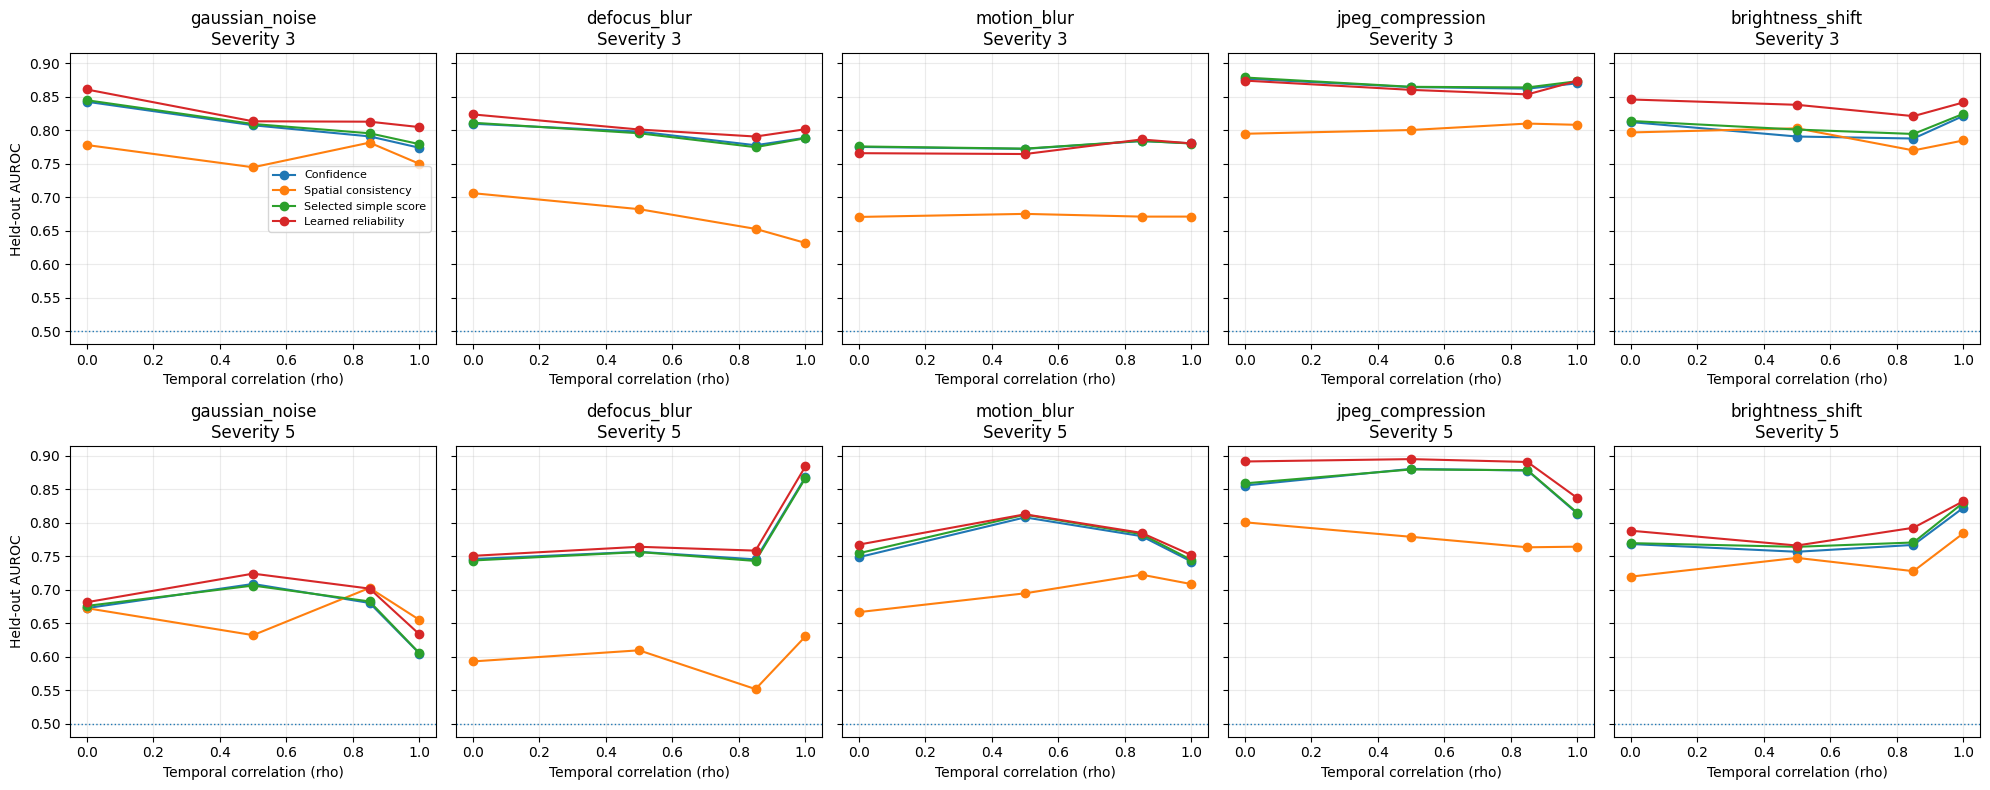


✅ PHASE 4 FULL RETRAINING COMPLETE
Checkpoint: /kaggle/working/AFML_Phase4_Full_Checkpoint_20261025_141603.zip
Files included: 11
ZIP size: 1.81 MB


/kaggle/working/AFML_Phase4_Full_Checkpoint_20261025_141603.zip

In [7]:
# ============================================================
# PHASE 4 FULL v2 — Reliability Estimator Retraining
#
# Input:
#   phase3_signals_full_v2.csv  (16,400 rows, 400 videos)
#   phase4_video_split_v2.csv   (existing 200/50/150 split)
#
# Outputs:
#   phase4_reliability_estimator_full_v2.joblib
#   phase4_video_split_full_v2.csv
#   phase4_validation_scores_full_v2.csv
#   phase4_test_scores_full_v2.csv
#   phase4_test_metrics_full_v2.csv
#   downloadable Phase 4 checkpoint ZIP
#
# No video inference. No split regeneration.
# ============================================================

import os
import json
import time
import zipfile
import shutil

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)
from IPython.display import FileLink, display

ROOT = "/kaggle/working"

INPUT_CSV = f"{ROOT}/phase3_signals_full_v2.csv"
SPLIT_CSV = f"{ROOT}/phase4_video_split_v2.csv"

# Use new filenames; preserve the original Phase 4 results.
ESTIMATOR_PATH = f"{ROOT}/phase4_reliability_estimator_full_v2.joblib"
SPLIT_OUT = f"{ROOT}/phase4_video_split_full_v2.csv"
VAL_OUT = f"{ROOT}/phase4_validation_scores_full_v2.csv"
TEST_OUT = f"{ROOT}/phase4_test_scores_full_v2.csv"
METRICS_OUT = f"{ROOT}/phase4_test_metrics_full_v2.csv"
SELECTION_OUT = f"{ROOT}/phase4_score_selection_full_v2.json"

# ------------------------------------------------------------
# 1. Validate inputs
# ------------------------------------------------------------

for path in (INPUT_CSV, SPLIT_CSV):
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required file missing: {path}")

d = pd.read_csv(INPUT_CSV)
split = pd.read_csv(SPLIT_CSV)

required_columns = [
    "video", "correct", "corruption", "severity", "rho",
    "conf", "entropy", "C_spat_soft", "C_temp_soft", "cos_ts"
]

missing_columns = [
    col for col in required_columns
    if col not in d.columns
]
if missing_columns:
    raise ValueError(f"Missing Phase 3 columns: {missing_columns}")

assert len(d) == 16400, f"Expected 16,400 rows, got {len(d)}"
assert d["video"].nunique() == 400
assert d.groupby("video").size().eq(41).all()

if not {"video", "split"}.issubset(split.columns):
    raise ValueError("Split file must contain 'video' and 'split' columns.")

split["video"] = split["video"].astype(str)
split["split"] = split["split"].astype(str).str.lower()
d["video"] = d["video"].astype(str)

if split["video"].duplicated().any():
    raise ValueError("Duplicate video identities found in the saved split.")

counts = split["split"].value_counts().to_dict()
expected_counts = {"train": 200, "validation": 50, "test": 150}

if counts != expected_counts:
    raise ValueError(
        f"Unexpected video split: {counts}; expected {expected_counts}"
    )

if set(d["video"]) != set(split["video"]):
    raise ValueError(
        "Video identities in the expanded dataset do not match the saved split."
    )

# FIX: use a list of column names, not a set, for pandas indexing.
feature_check_columns = [
    "correct", "conf", "entropy",
    "C_spat_soft", "C_temp_soft", "cos_ts"
]

if d[feature_check_columns].isna().any().any():
    raise ValueError("Missing feature or target values found.")

if not np.isfinite(
    d[feature_check_columns].to_numpy(dtype=float)
).all():
    raise ValueError("Non-finite feature or target values found.")

d["correct"] = d["correct"].astype(int)

if not set(d["correct"].unique()).issubset({0, 1}):
    raise ValueError("The 'correct' target must contain only 0 and 1.")

d["neg_entropy"] = -d["entropy"]

# ------------------------------------------------------------
# 2. Apply the existing video-level split
# ------------------------------------------------------------

split_map = split.set_index("video")["split"].to_dict()
d["split"] = d["video"].map(split_map)

train = d[d["split"] == "train"].copy()
val = d[d["split"] == "validation"].copy()
test = d[d["split"] == "test"].copy()

print("✅ Expanded Phase 3 dataset:", len(d), "rows")
print("✅ Video split:", counts)
print(
    "Rows train/validation/test:",
    len(train), len(val), len(test)
)

assert (len(train), len(val), len(test)) == (8200, 2050, 6150)

assert set(train["video"]).isdisjoint(set(val["video"]))
assert set(train["video"]).isdisjoint(set(test["video"]))
assert set(val["video"]).isdisjoint(set(test["video"]))

# ------------------------------------------------------------
# 3. Train the learned reliability estimator
# ------------------------------------------------------------

FEATURES = [
    "conf",
    "neg_entropy",
    "C_spat_soft",
    "C_temp_soft",
    "cos_ts",
]

reliability_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

reliability_model.fit(
    train[FEATURES],
    train["correct"].astype(int)
)

print("\n✅ Reliability estimator trained.")
print("Training videos:", train["video"].nunique())
print("Features:", FEATURES)

# ------------------------------------------------------------
# 4. Select the simple reliability score on validation only
# ------------------------------------------------------------

def simple_score_candidates(frame):
    return {
        "C_spat": frame["C_spat_soft"].to_numpy(dtype=float),

        "conf_times_Cspat": (
            frame["conf"] * frame["C_spat_soft"]
        ).to_numpy(dtype=float),

        "sqrt_Ctemp_Cspat": np.sqrt(
            np.clip(frame["C_temp_soft"].to_numpy(dtype=float), 0, 1)
            * np.clip(frame["C_spat_soft"].to_numpy(dtype=float), 0, 1)
        ),
    }


def macro_condition_auc(frame, score_column):
    """Equal-weight mean AUROC across valid corrupted conditions."""
    values = []

    corrupted = frame[frame["corruption"] != "clean"]

    for _, group in corrupted.groupby(
        ["corruption", "severity", "rho"],
        dropna=False
    ):
        y = group["correct"].astype(int).to_numpy()
        score = group[score_column].to_numpy(dtype=float)

        if np.unique(y).size < 2:
            continue

        values.append(roc_auc_score(y, score))

    return float(np.mean(values)) if values else np.nan


val_scores = val.copy()
test_scores = test.copy()

val_candidates = simple_score_candidates(val_scores)

val_simple_auc = {}

for name, values in val_candidates.items():
    val_scores[name] = values
    val_simple_auc[name] = macro_condition_auc(val_scores, name)

valid_candidates = {
    name: score
    for name, score in val_simple_auc.items()
    if np.isfinite(score)
}

if not valid_candidates:
    raise ValueError(
        "No valid simple reliability score could be selected on validation."
    )

selected_simple_score = max(
    valid_candidates,
    key=valid_candidates.get
)

print("\nValidation simple-score AUROC:")
print({
    name: round(score, 4)
    for name, score in val_simple_auc.items()
})
print("✅ Selected on validation:", selected_simple_score)

# Only the validation set determines which simple score is selected.
val_scores["r_simple"] = val_scores[selected_simple_score]

test_candidates = simple_score_candidates(test_scores)
test_scores["r_simple"] = test_candidates[selected_simple_score]

# The learned estimator was fitted on training videos only.
val_scores["r_learned"] = reliability_model.predict_proba(
    val_scores[FEATURES]
)[:, 1]

test_scores["r_learned"] = reliability_model.predict_proba(
    test_scores[FEATURES]
)[:, 1]

# ------------------------------------------------------------
# 5. Calibration metrics and bootstrap confidence intervals
# ------------------------------------------------------------

def expected_calibration_error(y, p, bins=10):
    y = np.asarray(y, dtype=float)
    p = np.clip(np.asarray(p, dtype=float), 0, 1)
    edges = np.linspace(0, 1, bins + 1)

    ece = 0.0

    for b in range(bins):
        if b == bins - 1:
            mask = (p >= edges[b]) & (p <= edges[b + 1])
        else:
            mask = (p >= edges[b]) & (p < edges[b + 1])

        if mask.any():
            ece += mask.mean() * abs(
                y[mask].mean() - p[mask].mean()
            )

    return float(ece)


def bootstrap_auc_ap_ci(y, scores, n_boot=500, seed=42):
    """Per-condition bootstrap CI, resampling held-out videos."""
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)

    generator = np.random.default_rng(seed)
    auc_values = []
    ap_values = []

    n = len(y)

    for _ in range(n_boot):
        indices = generator.integers(0, n, size=n)
        y_b = y[indices]
        s_b = scores[indices]

        # AUROC is undefined when a resample contains one class.
        if np.unique(y_b).size < 2:
            continue

        auc_values.append(roc_auc_score(y_b, s_b))
        ap_values.append(average_precision_score(y_b, s_b))

    if not auc_values:
        return {
            "AUROC_CI_low": np.nan,
            "AUROC_CI_high": np.nan,
            "AUPRC_CI_low": np.nan,
            "AUPRC_CI_high": np.nan,
        }

    auc_low, auc_high = np.quantile(auc_values, [0.025, 0.975])
    ap_low, ap_high = np.quantile(ap_values, [0.025, 0.975])

    return {
        "AUROC_CI_low": float(auc_low),
        "AUROC_CI_high": float(auc_high),
        "AUPRC_CI_low": float(ap_low),
        "AUPRC_CI_high": float(ap_high),
    }


# ------------------------------------------------------------
# 6. Evaluate held-out results separately by severity and rho
# ------------------------------------------------------------

score_columns = {
    "confidence": "conf",
    "temporal": "C_temp_soft",
    "spatial": "C_spat_soft",
    "simple": "r_simple",
    "learned": "r_learned",
}

metric_rows = []
test_corrupted = test_scores[
    test_scores["corruption"] != "clean"
].copy()

for (corruption, severity, rho), group in test_corrupted.groupby(
    ["corruption", "severity", "rho"],
    dropna=False,
    sort=True
):
    y = group["correct"].astype(int).to_numpy()

    row = {
        "corruption": corruption,
        "severity": int(severity),
        "rho": float(rho),
        "n": len(group),
        "accuracy": float(y.mean()),
        "error_rate": float(1 - y.mean()),
    }

    for method, column in score_columns.items():
        score = np.clip(
            group[column].to_numpy(dtype=float), 0, 1
        )

        if np.unique(y).size >= 2:
            row[f"{method}_AUROC"] = float(
                roc_auc_score(y, score)
            )
            row[f"{method}_AUPRC"] = float(
                average_precision_score(y, score)
            )
        else:
            row[f"{method}_AUROC"] = np.nan
            row[f"{method}_AUPRC"] = np.nan

    # Calibration metrics are meaningful for confidence and
    # learned probability estimates. The simple score remains
    # a ranking score and is not treated as calibrated probability.
    for method, column in (
        ("confidence", "conf"),
        ("learned", "r_learned"),
    ):
        p = np.clip(
            group[column].to_numpy(dtype=float), 0, 1
        )

        row[f"{method}_Brier"] = float(
            brier_score_loss(y, p)
        )
        row[f"{method}_ECE"] = expected_calibration_error(y, p)

        ci = bootstrap_auc_ap_ci(
            y, p,
            n_boot=500,
            seed=42 + int(severity * 100 + float(rho) * 10)
        )

        for metric, value in ci.items():
            row[f"{method}_{metric}"] = value

    metric_rows.append(row)

test_metrics = pd.DataFrame(metric_rows)

if len(test_metrics) != 40:
    raise ValueError(
        f"Expected 40 corrupted test conditions; found {len(test_metrics)}"
    )

if not (test_metrics["n"] == 150).all():
    raise ValueError(
        "Each corruption/severity/rho condition must contain 150 test videos."
    )

print("\n" + "=" * 75)
print("HELD-OUT TEST METRICS BY CORRUPTION, SEVERITY, AND RHO")
print("=" * 75)
print(test_metrics.round(3).to_string(index=False))

macro_columns = [
    "accuracy",
    "confidence_AUROC", "confidence_AUPRC",
    "temporal_AUROC", "temporal_AUPRC",
    "spatial_AUROC", "spatial_AUPRC",
    "simple_AUROC", "simple_AUPRC",
    "learned_AUROC", "learned_AUPRC",
    "confidence_Brier", "confidence_ECE",
    "learned_Brier", "learned_ECE",
]

print("\nMACRO-AVERAGE OVER THE 40 CORRUPTED CONDITIONS")
print(test_metrics[macro_columns].mean().round(4).to_dict())

# ------------------------------------------------------------
# 7. Save the new Phase 4 artifacts
# ------------------------------------------------------------

shutil.copy2(SPLIT_CSV, SPLIT_OUT)

joblib.dump(
    {
        "pipeline": reliability_model,
        "features": FEATURES,
        "selected_simple_score": selected_simple_score,
        "validation_simple_score_auroc": {
            name: (
                float(score) if np.isfinite(score) else None
            )
            for name, score in val_simple_auc.items()
        },
        "train_videos": sorted(train["video"].unique().tolist()),
        "validation_videos": sorted(val["video"].unique().tolist()),
        "test_videos": sorted(test["video"].unique().tolist()),
        "dataset": os.path.basename(INPUT_CSV),
        "split": os.path.basename(SPLIT_OUT),
    },
    ESTIMATOR_PATH
)

val_scores.to_csv(VAL_OUT, index=False)
test_scores.to_csv(TEST_OUT, index=False)
test_metrics.to_csv(METRICS_OUT, index=False)

selection_info = {
    "phase": 4,
    "dataset": os.path.basename(INPUT_CSV),
    "dataset_rows": int(len(d)),
    "unique_videos": int(d["video"].nunique()),
    "conditions_per_video": 41,
    "split_counts": counts,
    "features": FEATURES,
    "validation_simple_score_auroc": {
        name: (
            float(score) if np.isfinite(score) else None
        )
        for name, score in val_simple_auc.items()
    },
    "selected_simple_score": selected_simple_score,
    "test_condition_count": int(len(test_metrics)),
    "test_videos_per_condition": 150,
    "note": (
        "Simple-score selection used validation labels only. "
        "Held-out test labels were used for final evaluation only."
    ),
}

with open(SELECTION_OUT, "w") as f:
    json.dump(selection_info, f, indent=2)

print("\n✅ Saved estimator:", ESTIMATOR_PATH)
print("✅ Saved split:", SPLIT_OUT)
print("✅ Saved validation scores:", VAL_OUT)
print("✅ Saved held-out test scores:", TEST_OUT)
print("✅ Saved per-condition metrics:", METRICS_OUT)

# ------------------------------------------------------------
# 8. Plot held-out AUROC by corruption and severity
# ------------------------------------------------------------

corruptions = [
    "gaussian_noise",
    "defocus_blur",
    "motion_blur",
    "jpeg_compression",
    "brightness_shift",
]

fig, axes = plt.subplots(
    2, 5, figsize=(20, 8), sharey=True
)

plot_methods = [
    ("confidence_AUROC", "Confidence"),
    ("spatial_AUROC", "Spatial consistency"),
    ("simple_AUROC", "Selected simple score"),
    ("learned_AUROC", "Learned reliability"),
]

for row_i, severity in enumerate([3, 5]):
    for col_i, corruption in enumerate(corruptions):
        ax = axes[row_i, col_i]

        sub = test_metrics[
            (test_metrics["severity"] == severity)
            & (test_metrics["corruption"] == corruption)
        ].sort_values("rho")

        for column, label in plot_methods:
            ax.plot(
                sub["rho"],
                sub[column],
                marker="o",
                label=label
            )

        ax.axhline(0.5, linestyle=":", linewidth=1)
        ax.set_title(f"{corruption}\nSeverity {severity}")
        ax.set_xlabel("Temporal correlation (rho)")

        if col_i == 0:
            ax.set_ylabel("Held-out AUROC")

        ax.grid(alpha=0.25)

axes[0, 0].legend(fontsize=8)
fig.tight_layout()

PLOT_PATH = f"{ROOT}/phase4_full_test_auroc_plot.png"
fig.savefig(PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 9. Create a downloadable checkpoint
# ------------------------------------------------------------

stamp = time.strftime("%Y%m%d_%H%M%S")
ZIP_PATH = f"{ROOT}/AFML_Phase4_Full_Checkpoint_{stamp}.zip"

package_files = [
    INPUT_CSV,
    SPLIT_OUT,
    ESTIMATOR_PATH,
    VAL_OUT,
    TEST_OUT,
    METRICS_OUT,
    SELECTION_OUT,
    PLOT_PATH,
    f"{ROOT}/phase3_condition_auroc_full_v2.csv",
    f"{ROOT}/phase3_auroc_ci_full_v2.csv",
    f"{ROOT}/phase3_feature_comparison_full_v2.csv",
]

included = []

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zf:
    for path in package_files:
        if os.path.isfile(path):
            zf.write(path, arcname=os.path.basename(path))
            included.append(os.path.basename(path))

    manifest = {
        "phase": 4,
        "created": stamp,
        "dataset": os.path.basename(INPUT_CSV),
        "train_validation_test_videos": counts,
        "conditions_per_video": 41,
        "held_out_corrupted_conditions": int(len(test_metrics)),
        "files_included": included,
    }

    zf.writestr(
        "checkpoint_manifest.json",
        json.dumps(manifest, indent=2)
    )

print("\n" + "=" * 75)
print("✅ PHASE 4 FULL RETRAINING COMPLETE")
print("=" * 75)
print("Checkpoint:", ZIP_PATH)
print("Files included:", len(included))
print("ZIP size: %.2f MB" % (os.path.getsize(ZIP_PATH) / (1024 ** 2)))
display(FileLink(ZIP_PATH))

---
<a id="section-5-phase-5--reliability-guided-video-test-time-adaptation-rg-vitta"></a>
# Section 5: Phase 5 — Reliability-Guided Video Test-Time Adaptation (RG-ViTTA)

**Goal:** Benchmark test-time adaptation strategies on streaming corrupted video sequences.

### Methods Compared:
1. **Source-Only Baseline:** Frozen pretrained model (no test-time updates).
2. **Blind ViTTA (Ungated):** Adapts on 100% of videos via entropy minimization (vulnerable to echo chamber traps).
3. **Confidence-Gated ViTTA:** Adapts only if model confidence $\ge \tau_{\text{conf}}$.
4. **⭐ RG-ViTTA (Our Proposed Method):** Adapts only if the Calibrated Referee confirms $r(V) \ge \tau_{\text{gate}}$.

### Metrics:
* **Top-1 Accuracy (%)**
* **Net Adaptation Gain ($\Delta\text{Acc}$)**
* **Harmful Adaptation Rate (HAR):** Fraction of correctly classified source videos corrupted by adaptation.

In [10]:
!pip install -q decord transformers

import os, io, glob, time, re, copy
import numpy as np, pandas as pd, torch, torch.nn as nn, cv2
from PIL import Image
from decord import VideoReader, cpu
import decord; decord.bridge.set_bridge('native')
from transformers import AutoImageProcessor, VideoMAEForVideoClassification
from huggingface_hub import hf_hub_download

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

# ---- model + attention-bias remap (same as your setup cell) ----
MODEL_NAME = "nateraw/videomae-base-finetuned-ucf101"
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
model = VideoMAEForVideoClassification.from_pretrained(MODEL_NAME).to(device).eval()
id2label = model.config.id2label
raw = torch.load(hf_hub_download(repo_id=MODEL_NAME, filename="pytorch_model.bin"), map_location='cpu', weights_only=True)
with torch.no_grad():
    for i in range(12):
        q = raw.get(f'videomae.encoder.layer.{i}.attention.attention.q_bias'); v = raw.get(f'videomae.encoder.layer.{i}.attention.attention.v_bias')
        if q is not None and v is not None:
            a = model.videomae.encoder.layer[i].attention.attention
            a.query.bias.copy_(q.to(device)); a.key.bias.zero_(); a.value.bias.copy_(v.to(device))
print("model ready")

# ---- shared corrected corruption functions: identical to Phase 2/3 v2 ----
def _ar1(num_frames, shape, rho, seed):
    if not 0 <= rho <= 1:
        raise ValueError("rho must be in [0, 1]")

    rng = np.random.default_rng(seed)
    z = np.empty((num_frames, *shape), dtype=np.float32)

    if rho == 1.0:
        # Constant over time, with a bounded unit-scale value.
        # Draw one standard-normal field and reuse it across all frames.
        # Do not clip the latent noise: clipping changes its marginal distribution.
        base = rng.standard_normal(shape).astype(np.float32)
        z[:] = base
        return z

    z[0] = rng.standard_normal(shape).astype(np.float32)

    for t in range(1, num_frames):
        eps = rng.standard_normal(shape).astype(np.float32)
        z[t] = rho * z[t - 1] + np.sqrt(1 - rho**2) * eps

    # Normalize only when temporal variation exists.
    z /= max(float(z.std()), 1e-6)
    return z



def apply_gaussian_noise(frames, z, severity):
    sigma = {1:10, 3:30, 5:60}[severity]
    return [np.clip(f.astype(np.float32)+sigma*z[t], 0, 255).astype(np.uint8)
            for t, f in enumerate(frames)]

def apply_defocus_blur(frames, z, severity):
    base = {1:1.0, 3:2.5, 5:4.5}[severity]
    out = []
    for t, f in enumerate(frames):
        # Same parameter range at every rho; rho changes temporal ordering/correlation.
        sigma = base * np.clip(1.0 + 0.25*float(z[t,0,0,0]), 0.5, 1.5)
        out.append(cv2.GaussianBlur(f, (0,0), float(sigma)))
    return out

def _motion_kernel(k, angle_deg):
    ker = np.zeros((k,k), np.float32); ker[k//2,:] = 1
    mat = cv2.getRotationMatrix2D(((k-1)/2,(k-1)/2), float(angle_deg), 1.0)
    ker = cv2.warpAffine(ker, mat, (k,k))
    return ker / max(float(ker.sum()), 1e-6)

def apply_motion_blur(frames, z, severity):
    k = {1:5, 3:15, 5:25}[severity]
    out = []
    for t, f in enumerate(frames):
        angle = 25.0 * np.clip(float(z[t,0,0,0]), -1.0, 1.0)
        out.append(cv2.filter2D(f, -1, _motion_kernel(k, angle)))
    return out

def apply_jpeg_compression(frames, z, severity):
    base_quality = {1:40, 3:15, 5:5}[severity]
    out = []
    for t, f in enumerate(frames):
        quality = int(np.clip(round(base_quality * (1 + 0.20*float(z[t,0,0,0]))), 1, 95))
        buf = io.BytesIO()
        Image.fromarray(f).save(buf, format="JPEG", quality=quality)
        buf.seek(0)
        out.append(np.array(Image.open(buf).convert("RGB")))
    return out

def apply_brightness_shift(frames, z, severity):
    # Fixed amplitude; the signed AR(1) signal controls temporal variation.
    amplitude = {1:20, 3:45, 5:80}[severity]
    return [np.clip(f.astype(np.float32)+amplitude*z[t,0,0,0],0,255).astype(np.uint8)
            for t,f in enumerate(frames)]

CORRUPTIONS = {
    "gaussian_noise": apply_gaussian_noise,
    "defocus_blur": apply_defocus_blur,
    "motion_blur": apply_motion_blur,
    "jpeg_compression": apply_jpeg_compression,
    "brightness_shift": apply_brightness_shift,
}

def corrupt_video(frames, name, severity, rho, seed):
    """Apply reproducible corruption to already resized RGB frames."""
    if name not in CORRUPTIONS:
        raise ValueError(f"Unknown corruption: {name}")
    T = len(frames)
    shape = frames[0].shape if name == "gaussian_noise" else (1,1,1)
    z = _ar1(T, shape, rho, seed)
    if name == "brightness_shift":
        # A single scalar per frame, but normalized across time.
        z = z.reshape(T,1,1,1)
    return CORRUPTIONS[name](frames, z, severity)

# ---- labels and test videos ----
l2i = model.config.label2id if getattr(model.config, 'label2id', None) else {v: k for k, v in id2label.items()}
TXT_PATH = '/kaggle/working/test_videos.txt'
test_videos = [l.strip() for l in open(TXT_PATH) if l.strip()]

missing = [p for p in test_videos if not os.path.exists(p)]
print(f"{len(l2i)} classes | {len(test_videos)} test videos | missing on disk: {len(missing)}")
if missing: print("example missing path:", missing[0])

GPU: Tesla T4


Loading weights:   0%|          | 0/162 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: nateraw/videomae-base-finetuned-ucf101
Key                                                            | Status     | 
---------------------------------------------------------------+------------+-
videomae.encoder.layer.{0...11}.attention.attention.q_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.v_bias     | UNEXPECTED | 
videomae.encoder.layer.{0...11}.attention.attention.query.bias | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.value.bias | MISSING    | 
videomae.encoder.layer.{0...11}.attention.attention.key.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model ready


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/test_videos.txt'

In [34]:
LR, COVERAGE, N_STREAM, SEV = 1e-4, 0.4, 150, 5
MB = 2
CONDS_P5 = [('gaussian_noise', 1.0), ('gaussian_noise', 0.0), ('jpeg_compression', 1.0)]
METHODS = ['ungated', 'conf_gate', 'r_gate']

VAL_SCORES = '/kaggle/working/phase4_validation_scores_v2.csv'
TEST_SCORES = '/kaggle/working/phase4_test_scores_v2.csv'
val_scores = pd.read_csv(VAL_SCORES)
test_scores = pd.read_csv(TEST_SCORES)

val_corrupt = val_scores[val_scores.corruption != 'clean'].copy()
test_corrupt = test_scores[test_scores.corruption != 'clean'].copy()

# Thresholds use validation rows only; test labels are never used for threshold selection.
THR = {
    'conf_gate': float(val_corrupt.conf.quantile(1 - COVERAGE)),
    'r_gate': float(val_corrupt.r_learned.quantile(1 - COVERAGE))
}
# Scores from validation support LR sensitivity runs; final stream still uses test-only names.
all_gate_rows = pd.concat([val_corrupt, test_corrupt], ignore_index=True)
gate_score = {
    (r.video, r.corruption, float(r.rho)): (float(r.conf), float(r.r_learned))
    for r in all_gate_rows.itertuples()
}
ref_correct = test_corrupt.set_index(
    ['video', 'corruption', 'rho']
).correct

# Restrict stream to held-out test videos that have valid file paths.
names_available = set(os.path.basename(p) for p in test_videos)
names_test = sorted(set(test_corrupt.video) & names_available)
if len(names_test) < N_STREAM:
    print(f"WARNING: only {len(names_test)} held-out videos available (requested {N_STREAM}).")
N_STREAM = min(N_STREAM, len(names_test))
rng0 = np.random.default_rng(123)
stream_names = list(rng0.choice(names_test, N_STREAM, replace=False))
path_of = {os.path.basename(p): p for p in test_videos}
vid_index = {os.path.basename(p): i for i, p in enumerate(test_videos)}
val_names = sorted(set(val_scores.video) & names_available)
print(f"held-out stream: {len(stream_names)} | validation videos: {len(val_names)} | thresholds: {THR}")

# Ensure all requested conditions have a reliability score before expensive adaptation.
for cname, rho in CONDS_P5:
    missing = [n for n in stream_names if (n, cname, float(rho)) not in gate_score]
    if missing:
        raise ValueError(
            f"{len(missing)} stream videos lack Phase 4 scores for {(cname, rho)}; "
            f"example: {missing[0]}. Confirm Phase 3 and Phase 4 used the same video list."
        )

def make_adapter(lr):
    m = copy.deepcopy(model).to(device).eval()
    for p in m.parameters():
        p.requires_grad_(False)
    params = []
    for mod in m.modules():
        if isinstance(mod, nn.LayerNorm):
            for p in (mod.weight, mod.bias):
                p.requires_grad_(True)
                params.append(p)
    return m, torch.optim.Adam(params, lr=lr)
import torch

# Check whether independently created adapters start identically
m1, opt1 = make_adapter(1e-4)
m2, opt2 = make_adapter(1e-4)

same_weights = all(
    torch.equal(p1.detach().cpu(), p2.detach().cpu())
    for p1, p2 in zip(m1.parameters(), m2.parameters())
)

print("Identical initial weights:", same_weights)
print("Separate optimizers:", opt1 is not opt2)
print(
    "Trainable parameters:",
    sum(p.numel() for p in m1.parameters() if p.requires_grad)
)

del m1, m2, opt1, opt2
torch.cuda.empty_cache()
def adapt_on(m, opt, x, update):
    # Pre-update protocol: predictions for the current video are computed before opt.step().
    n = x.shape[0]
    if not update:
        with torch.no_grad():
            return torch.softmax(m(pixel_values=x).logits, -1)
    opt.zero_grad(set_to_none=True)
    probs = []
    for i in range(0, n, MB):
        p = torch.softmax(m(pixel_values=x[i:i+MB]).logits, -1)
        (-(p * torch.log(p + 1e-8)).sum(-1).sum() / n).backward()
        probs.append(p.detach())
    opt.step()
    return torch.cat(probs)

def gate_decision(method, key):
    conf, reliability = gate_score[key]
    if method == 'ungated':
        return True
    if method == 'conf_gate':
        return conf >= THR['conf_gate']
    if method == 'r_gate':
        return reliability >= THR['r_gate']
    raise ValueError(f"Unknown method: {method}")

def run_condition(cname, rho, names, lr, methods=METHODS, verbose=True, reference_correct=None):
    src = copy.deepcopy(model).to(device).eval()
    ads = {mth: make_adapter(lr) for mth in methods}
    rows, t0 = [], time.time()
    for i, name in enumerate(names):
        path = path_of[name]
        gt_id = l2i[path.split('/')[-2]]
        seq = corrupt_video(load_segments(path, 4), cname, SEV, rho, seed=vid_index[name])
        x = torch.cat([
            processor(seq[m*16:(m+1)*16], return_tensors='pt')['pixel_values']
            for m in range(4)
        ]).to(device)
        with torch.no_grad():
            src_pred = int(torch.softmax(src(pixel_values=x).logits, -1).mean(0).argmax())
        rec = dict(video=name, corruption=cname, rho=float(rho), order=i,
                   source_correct=int(src_pred == gt_id))
        for mth, (m, opt) in ads.items():
            update = gate_decision(mth, (name, cname, float(rho)))
            # Current-video predictions are pre-update; updates affect subsequent videos.
            rec[f'{mth}_correct'] = int(int(adapt_on(m, opt, x, update).mean(0).argmax()) == gt_id)
            rec[f'{mth}_updated'] = int(update)
        rows.append(rec)
        if verbose and (i+1) % 25 == 0:
            d_ = pd.DataFrame(rows)
            print(f"  {cname} rho={rho}: {i+1}/{len(names)} | "
                  f"source {d_.source_correct.mean():.3f} | " +
                  " | ".join(f"{m} {d_[m+'_correct'].mean():.3f}" for m in methods))
    del src, ads
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    df = pd.DataFrame(rows)
    ref_map = ref_correct if reference_correct is None else reference_correct
    agrees = []
    for row in df.itertuples():
        key = (row.video, row.corruption, float(row.rho))
        try:
            expected = ref_map[key] if isinstance(ref_map, dict) else ref_map.loc[key]
            agrees.append(int(int(expected) == int(row.source_correct)))
        except (KeyError, TypeError):
            continue
    if agrees:
        print(f"  sanity: source agrees with matching saved correctness on {np.mean(agrees):.1%}")
    else:
        print("  sanity: no matching reference rows available; comparison skipped")
    return df


held-out stream: 150 | validation videos: 50 | thresholds: {'conf_gate': 0.30755249261856077, 'r_gate': 0.38724850985698456}
Identical initial weights: True
Separate optimizers: True
Trainable parameters: 38400


In [38]:
CONDS_P5 = [
    (corruption, rho)
    for corruption in (
        'gaussian_noise',
        'defocus_blur',
        'jpeg_compression'
    )
    for rho in (0.0, 0.5, 0.85, 1.0)
]

print("Phase 5 conditions:", len(CONDS_P5))
print(CONDS_P5)

assert len(CONDS_P5) == 12

Phase 5 conditions: 12
[('gaussian_noise', 0.0), ('gaussian_noise', 0.5), ('gaussian_noise', 0.85), ('gaussian_noise', 1.0), ('defocus_blur', 0.0), ('defocus_blur', 0.5), ('defocus_blur', 0.85), ('defocus_blur', 1.0), ('jpeg_compression', 0.0), ('jpeg_compression', 0.5), ('jpeg_compression', 0.85), ('jpeg_compression', 1.0)]


In [39]:
import os
import numpy as np
import pandas as pd

# Verify the saved split is the corrected 200/50/150 split.
split = pd.read_csv(
    '/kaggle/working/phase4_video_split_v2.csv'
)
counts = split['split'].value_counts().to_dict()
print("Saved split:", counts)

assert counts.get('train') == 200
assert counts.get('validation') == 50
assert counts.get('test') == 150

# Confirm required functions are present before any expensive run.
required = [
    'to224', 'load_segments', 'corrupt_video',
    'make_adapter', 'run_condition'
]
missing = [
    name for name in required
    if not callable(globals().get(name))
]
assert not missing, f"Missing functions: {missing}"

assert len(stream_names) == 150, (
    f"Expected 150 held-out videos, got {len(stream_names)}"
)
assert len(CONDS_P5) == 12

# Verify the selected videos belong only to the held-out test split.
test_ids = set(split.loc[split['split'] == 'test', 'video'])
assert set(stream_names) <= test_ids

# Confirm all requested conditions have saved reliability scores.
for corruption, rho in CONDS_P5:
    absent = [
        name for name in stream_names
        if (name, corruption, float(rho)) not in gate_score
    ]
    assert not absent, (
        f"Missing scores for {corruption}, rho={rho}: "
        f"{len(absent)} videos"
    )

print("✅ Phase 5 preflight passed.")
print("Conditions:", CONDS_P5)
print("Held-out videos:", len(stream_names))
print("Coverage thresholds:", THR)

Saved split: {'train': 200, 'test': 150, 'validation': 50}
✅ Phase 5 preflight passed.
Conditions: [('gaussian_noise', 0.0), ('gaussian_noise', 0.5), ('gaussian_noise', 0.85), ('gaussian_noise', 1.0), ('defocus_blur', 0.0), ('defocus_blur', 0.5), ('defocus_blur', 0.85), ('defocus_blur', 1.0), ('jpeg_compression', 0.0), ('jpeg_compression', 0.5), ('jpeg_compression', 0.85), ('jpeg_compression', 1.0)]
Held-out videos: 150
Coverage thresholds: {'conf_gate': 0.30755249261856077, 'r_gate': 0.38724850985698456}


In [41]:
# PHASE 5 RUNNER — run after Phase 4 files and the function-definition cell are ready.
# Saves every condition immediately and displays a downloadable ZIP after each condition.
phase5_results = []
for cname, rho in CONDS_P5:
    out = f"/kaggle/working/phase5_v2_lr{LR}_{cname}_rho{rho}.csv"
    if os.path.exists(out):
        print("Existing result found; loading instead of rerunning:", out)
        result = pd.read_csv(out)
    else:
        print(f"\nRunning {cname}, rho={rho}")
        result = run_condition(cname, rho, stream_names, LR)
        result.to_csv(out, index=False)
        print("Saved:", out)
        checkpoint_files("AFML_Phase5_Condition", [out])
    phase5_results.append(result)
print("\nPhase 5 conditions available:", len(phase5_results))


Existing result found; loading instead of rerunning: /kaggle/working/phase5_v2_lr0.0001_gaussian_noise_rho0.0.csv

Running gaussian_noise, rho=0.5
  gaussian_noise rho=0.5: 25/150 | source 0.360 | ungated 0.360 | conf_gate 0.320 | r_gate 0.320
  gaussian_noise rho=0.5: 50/150 | source 0.320 | ungated 0.300 | conf_gate 0.280 | r_gate 0.280
  gaussian_noise rho=0.5: 75/150 | source 0.307 | ungated 0.293 | conf_gate 0.280 | r_gate 0.280
  gaussian_noise rho=0.5: 100/150 | source 0.280 | ungated 0.250 | conf_gate 0.270 | r_gate 0.260
  gaussian_noise rho=0.5: 125/150 | source 0.288 | ungated 0.240 | conf_gate 0.288 | r_gate 0.272
  gaussian_noise rho=0.5: 150/150 | source 0.287 | ungated 0.227 | conf_gate 0.280 | r_gate 0.273
  sanity: source agrees with matching saved correctness on 100.0%
Saved: /kaggle/working/phase5_v2_lr0.0001_gaussian_noise_rho0.5.csv
Checkpoint: /kaggle/working/AFML_Phase5_Condition_20261024_180423.zip | included 1 files


/kaggle/working/AFML_Phase5_Condition_20261024_180423.zip


Running gaussian_noise, rho=0.85
  gaussian_noise rho=0.85: 25/150 | source 0.360 | ungated 0.400 | conf_gate 0.400 | r_gate 0.400
  gaussian_noise rho=0.85: 50/150 | source 0.340 | ungated 0.320 | conf_gate 0.360 | r_gate 0.360
  gaussian_noise rho=0.85: 75/150 | source 0.333 | ungated 0.293 | conf_gate 0.347 | r_gate 0.347
  gaussian_noise rho=0.85: 100/150 | source 0.310 | ungated 0.270 | conf_gate 0.320 | r_gate 0.320
  gaussian_noise rho=0.85: 125/150 | source 0.320 | ungated 0.264 | conf_gate 0.320 | r_gate 0.320
  gaussian_noise rho=0.85: 150/150 | source 0.320 | ungated 0.253 | conf_gate 0.313 | r_gate 0.313
  sanity: source agrees with matching saved correctness on 100.0%
Saved: /kaggle/working/phase5_v2_lr0.0001_gaussian_noise_rho0.85.csv
Checkpoint: /kaggle/working/AFML_Phase5_Condition_20261024_181354.zip | included 1 files


/kaggle/working/AFML_Phase5_Condition_20261024_181354.zip


Running gaussian_noise, rho=1.0
  gaussian_noise rho=1.0: 25/150 | source 0.400 | ungated 0.400 | conf_gate 0.320 | r_gate 0.320
  gaussian_noise rho=1.0: 50/150 | source 0.380 | ungated 0.380 | conf_gate 0.340 | r_gate 0.340
  gaussian_noise rho=1.0: 75/150 | source 0.347 | ungated 0.347 | conf_gate 0.320 | r_gate 0.320
  gaussian_noise rho=1.0: 100/150 | source 0.330 | ungated 0.310 | conf_gate 0.310 | r_gate 0.310
  gaussian_noise rho=1.0: 125/150 | source 0.328 | ungated 0.304 | conf_gate 0.312 | r_gate 0.312
  gaussian_noise rho=1.0: 150/150 | source 0.333 | ungated 0.293 | conf_gate 0.307 | r_gate 0.307
  sanity: source agrees with matching saved correctness on 100.0%
Saved: /kaggle/working/phase5_v2_lr0.0001_gaussian_noise_rho1.0.csv
Checkpoint: /kaggle/working/AFML_Phase5_Condition_20261024_182326.zip | included 1 files


/kaggle/working/AFML_Phase5_Condition_20261024_182326.zip

... (13 outputs left out)

/kaggle/working/AFML_Phase5_Condition_20261024_193131.zip


Running jpeg_compression, rho=1.0
  jpeg_compression rho=1.0: 25/150 | source 0.440 | ungated 0.440 | conf_gate 0.440 | r_gate 0.440
  jpeg_compression rho=1.0: 50/150 | source 0.580 | ungated 0.580 | conf_gate 0.580 | r_gate 0.580
  jpeg_compression rho=1.0: 75/150 | source 0.547 | ungated 0.547 | conf_gate 0.547 | r_gate 0.547
  jpeg_compression rho=1.0: 100/150 | source 0.550 | ungated 0.550 | conf_gate 0.550 | r_gate 0.550
  jpeg_compression rho=1.0: 125/150 | source 0.568 | ungated 0.568 | conf_gate 0.568 | r_gate 0.568
  jpeg_compression rho=1.0: 150/150 | source 0.553 | ungated 0.560 | conf_gate 0.560 | r_gate 0.553
  sanity: source agrees with matching saved correctness on 100.0%
Saved: /kaggle/working/phase5_v2_lr0.0001_jpeg_compression_rho1.0.csv
Checkpoint: /kaggle/working/AFML_Phase5_Condition_20261024_194137.zip | included 1 files


/kaggle/working/AFML_Phase5_Condition_20261024_194137.zip


Phase 5 conditions available: 12


In [ ]:
# OPTIONAL: learning-rate sensitivity on validation videos only.
# Set RUN_LR_SENSITIVITY=True only if you want to spend additional GPU time.
RUN_LR_SENSITIVITY = False
if RUN_LR_SENSITIVITY:
    LR_RESULTS = []
    val_ref = {
        (r.video, r.corruption, float(r.rho)): int(r.correct)
        for r in val_corrupt.itertuples()
    }
    for lr in (1e-5, 1e-4, 1e-3):
        df_lr = run_condition(
            'gaussian_noise', 1.0, val_names[:40], lr,
            methods=['ungated'], verbose=False,
            reference_correct=val_ref
        )
        gain = float(df_lr.ungated_correct.mean() - df_lr.source_correct.mean())
        LR_RESULTS.append({
            'learning_rate': lr,
            'source_accuracy': float(df_lr.source_correct.mean()),
            'adapted_accuracy': float(df_lr.ungated_correct.mean()),
            'gain': gain,
            'n_videos': len(df_lr)
        })
        print(f"LR={lr:g}: source={df_lr.source_correct.mean():.3f}, "
              f"adapted={df_lr.ungated_correct.mean():.3f}, gain={gain:+.3f}")
    lr_results_df = pd.DataFrame(LR_RESULTS)
    lr_results_df.to_csv('/kaggle/working/phase5_lr_sensitivity_v2.csv', index=False)
    print(lr_results_df.to_string(index=False))
else:
    print('LR sensitivity skipped by default. Set RUN_LR_SENSITIVITY=True to run it.')


In [42]:
# Phase 5: aggregate already-run condition CSVs. Does NOT launch missing experiments silently.
import os, numpy as np, pandas as pd, zipfile, json, time
from IPython.display import FileLink, display

LR = 1e-4
tag = f"lr{LR:g}"
expected = [f'/kaggle/working/phase5_v2_{tag}_{c}_rho{rho}.csv' for c, rho in CONDS_P5]
missing = [p for p in expected if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "Missing Phase 5 condition outputs; run the Phase 5 experiment cell first:\n" + "\n".join(missing)
    )
res = pd.concat([pd.read_csv(p) for p in expected], ignore_index=True)
rows=[]; rng=np.random.default_rng(0)
for (c,rho), g in res.groupby(['corruption','rho']):
    source=g.source_correct.to_numpy().astype(int); n=len(g)
    for method in METHODS:
        adapted=g[f'{method}_correct'].to_numpy().astype(int)
        updated=g[f'{method}_updated'].to_numpy().astype(bool)
        diff=adapted-source
        # Harmful adaptation rate is conditional on source-correct videos.
        initially_correct=(source==1); initially_wrong=(source==0)
        harmful=((source==1)&(adapted==0)).sum()
        helped=((source==0)&(adapted==1)).sum()
        har_cond=harmful/initially_correct.sum() if initially_correct.sum() else np.nan
        help_cond=helped/initially_wrong.sum() if initially_wrong.sum() else np.nan
        boot=np.array([diff[rng.integers(0,n,n)].mean() for _ in range(2000)])
        lo,hi=np.quantile(boot,[.025,.975])
        rows.append(dict(corruption=c,rho=float(rho),n=n,method=method,
            source_acc=source.mean(),adapted_acc=adapted.mean(),gain=diff.mean(),
            gain_ci_low=lo,gain_ci_high=hi,HAR=harmful/n,HAR_conditional=har_cond,
            help_rate=helped/n,help_rate_conditional=help_cond,
            frac_updated=updated.mean()))
summary=pd.DataFrame(rows)
summary_path='/kaggle/working/phase5_v2_summary.csv'
summary.to_csv(summary_path,index=False)
all_path=f'/kaggle/working/phase5_v2_{tag}_all_results.csv'
res.to_csv(all_path,index=False)
print(summary.round(4).to_string(index=False))

# Persistent download checkpoint: download this ZIP to your computer after each phase.
def make_checkpoint(label, paths):
    stamp=time.strftime('%Y%m%d_%H%M%S')
    zip_path=f'/kaggle/working/{label}_{stamp}.zip'
    manifest=[]
    with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
        for p in paths:
            if p and os.path.isfile(p):
                zf.write(p,arcname=os.path.basename(p))
                manifest.append({'file':os.path.basename(p),'bytes':os.path.getsize(p)})
        zf.writestr('manifest.json',json.dumps({'checkpoint':label,'created':stamp,'files':manifest},indent=2))
    print(f'Checkpoint ready: {zip_path} ({len(manifest)} files)')
    display(FileLink(zip_path))
    return zip_path

phase5_files=expected+[summary_path,all_path,'/kaggle/working/phase5_lr_sensitivity_v2.csv']
checkpoint_path=make_checkpoint('AFML_Phase5_Checkpoint',phase5_files)


      corruption  rho   n    method  source_acc  adapted_acc    gain  gain_ci_low  gain_ci_high    HAR  HAR_conditional  help_rate  help_rate_conditional  frac_updated
    defocus_blur 0.00 150   ungated      0.4133       0.4200  0.0067      -0.0133        0.0333 0.0067           0.0161     0.0133                 0.0227        1.0000
    defocus_blur 0.00 150 conf_gate      0.4133       0.4333  0.0200       0.0000        0.0467 0.0000           0.0000     0.0200                 0.0341        0.4400
    defocus_blur 0.00 150    r_gate      0.4133       0.4333  0.0200       0.0000        0.0400 0.0000           0.0000     0.0200                 0.0341        0.4533
    defocus_blur 0.50 150   ungated      0.4200       0.4267  0.0067       0.0000        0.0200 0.0000           0.0000     0.0067                 0.0115        1.0000
    defocus_blur 0.50 150 conf_gate      0.4200       0.4333  0.0133       0.0000        0.0333 0.0000           0.0000     0.0133                 0.0230       

/kaggle/working/AFML_Phase5_Checkpoint_20261024_194526.zip

In [11]:
# ============================================================
# PHASE 5 FULL MATRIX v2 — SETUP AND PREFLIGHT
# Uses the FULL Phase 4 retrained estimator.
# 5 corruptions x 2 severities x 4 correlations = 40 conditions.
#
# This cell defines functions and validates inputs only.
# It does NOT run adaptation.
# ============================================================
%pip install -q decord
import os
import re
import glob
import copy
import time
import json
import zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import cv2

from decord import VideoReader, cpu
from IPython.display import FileLink, display

ROOT = "/kaggle/working"

# ------------------------------------------------------------
# 1. Verify the source model and corruption functions are loaded
# ------------------------------------------------------------

required_globals = ["model", "processor", "to224", "corrupt_video"]
missing = [
    name for name in required_globals
    if name not in globals() or globals()[name] is None
]

if missing:
    raise RuntimeError(
        f"Missing setup objects: {missing}\n"
        "Run the existing 'Setup Cell: Installs, Model Loading & "
        "Core Corruption Functions' first. Do not run Phase 2 or 3."
    )

device = next(model.parameters()).device
model.eval()

# Recreate the class-name -> integer mapping.
label2id = getattr(model.config, "label2id", None)

if not label2id:
    label2id = {
        str(label): int(idx)
        for idx, label in model.config.id2label.items()
    }
else:
    label2id = {
        str(label): int(idx)
        for label, idx in label2id.items()
    }

# ------------------------------------------------------------
# 2. Load the NEW Phase 4 full-matrix outputs
# ------------------------------------------------------------

VAL_PATH = f"{ROOT}/phase4_validation_scores_full_v2.csv"
TEST_PATH = f"{ROOT}/phase4_test_scores_full_v2.csv"
SPLIT_PATH = f"{ROOT}/phase4_video_split_full_v2.csv"
ESTIMATOR_PATH = f"{ROOT}/phase4_reliability_estimator_full_v2.joblib"
VIDEO_LIST_PATH = f"{ROOT}/test_videos.txt"

required_files = [
    VAL_PATH, TEST_PATH, SPLIT_PATH,
    ESTIMATOR_PATH, VIDEO_LIST_PATH
]

missing_files = [p for p in required_files if not os.path.isfile(p)]

if missing_files:
    raise FileNotFoundError(
        "Missing Phase 4 full-matrix artifacts:\n"
        + "\n".join(missing_files)
        + "\nRestore them from your downloaded Phase 4 Full Checkpoint ZIP."
    )

val_scores = pd.read_csv(VAL_PATH)
test_scores = pd.read_csv(TEST_PATH)
split_df = pd.read_csv(SPLIT_PATH)

# Validate the saved 200/50/150 split.
split_counts = split_df["split"].value_counts().to_dict()

assert split_counts == {
    "train": 200,
    "validation": 50,
    "test": 150
}, f"Unexpected video split: {split_counts}"

assert len(val_scores) == 2050, (
    f"Expected 2,050 validation rows, got {len(val_scores)}"
)
assert len(test_scores) == 6150, (
    f"Expected 6,150 test rows, got {len(test_scores)}"
)
assert val_scores["video"].nunique() == 50
assert test_scores["video"].nunique() == 150

assert {
    "video", "corruption", "severity", "rho",
    "correct", "conf", "r_learned"
}.issubset(val_scores.columns)

assert {
    "video", "corruption", "severity", "rho",
    "correct", "conf", "r_learned"
}.issubset(test_scores.columns)

# Check that the saved Phase 4 outputs cover all 41 conditions per video.
assert val_scores.groupby("video").size().eq(41).all()
assert test_scores.groupby("video").size().eq(41).all()

# Confirm there is no train/validation/test video overlap.
split_sets = {
    s: set(split_df.loc[split_df["split"] == s, "video"].astype(str))
    for s in ("train", "validation", "test")
}
assert split_sets["train"].isdisjoint(split_sets["validation"])
assert split_sets["train"].isdisjoint(split_sets["test"])
assert split_sets["validation"].isdisjoint(split_sets["test"])

# ------------------------------------------------------------
# 3. Define the full Phase 5 condition matrix
# ------------------------------------------------------------

CORRUPTIONS_P5 = [
    "gaussian_noise",
    "defocus_blur",
    "motion_blur",
    "jpeg_compression",
    "brightness_shift"
]

SEVERITIES_P5 = [3, 5]
RHOS_P5 = [0.0, 0.5, 0.85, 1.0]

CONDS_P5 = [
    (corruption, severity, rho)
    for corruption in CORRUPTIONS_P5
    for severity in SEVERITIES_P5
    for rho in RHOS_P5
]

assert len(CONDS_P5) == 40

# Three independently initialized adaptation strategies.
METHODS = ["vitta_style", "conf_gate", "r_gate"]

LR = 1e-4
COVERAGE = 0.40
N_STREAM = 150
MB = 2

# ------------------------------------------------------------
# 4. Select held-out videos in a reproducible order
# ------------------------------------------------------------

with open(VIDEO_LIST_PATH) as f:
    video_paths = [line.strip() for line in f if line.strip()]

path_of = {os.path.basename(p): p for p in video_paths}

if len(path_of) != len(video_paths):
    raise ValueError("Duplicate video basenames in the video manifest.")

missing_paths = [
    p for p in video_paths
    if not os.path.isfile(p)
]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} video paths are unavailable. "
        f"Example: {missing_paths[0]}"
    )

available_names = set(path_of)
test_names = sorted(set(test_scores["video"].astype(str)) & available_names)

if len(test_names) != 150:
    raise ValueError(
        f"Expected 150 accessible held-out videos, got {len(test_names)}."
    )

# Reproducible order over exactly the 150 test videos.
rng0 = np.random.default_rng(123)
stream_names = list(
    rng0.choice(test_names, size=N_STREAM, replace=False)
)

vid_index = {
    os.path.basename(p): i
    for i, p in enumerate(video_paths)
}

# ------------------------------------------------------------
# 5. Select thresholds using VALIDATION scores only
# ------------------------------------------------------------

val_corrupt = val_scores[
    val_scores["corruption"] != "clean"
].copy()

test_corrupt = test_scores[
    test_scores["corruption"] != "clean"
].copy()

THR = {
    "conf_gate": float(
        val_corrupt["conf"].quantile(1 - COVERAGE)
    ),
    "r_gate": float(
        val_corrupt["r_learned"].quantile(1 - COVERAGE)
    )
}

# Gate lookups include severity so severity 3 and 5 are never mixed.
all_gate_rows = pd.concat(
    [val_corrupt, test_corrupt],
    ignore_index=True
)

gate_score = {
    (
        str(r.video),
        str(r.corruption),
        int(r.severity),
        float(r.rho)
    ): (
        float(r.conf),
        float(r.r_learned)
    )
    for r in all_gate_rows.itertuples()
}

# Reference correctness comes from the saved Phase 4 test data.
ref_correct_map = {
    (
        str(r.video),
        str(r.corruption),
        int(r.severity),
        float(r.rho)
    ): int(r.correct)
    for r in test_corrupt.itertuples()
}

# ------------------------------------------------------------
# 6. Confirm all 40 conditions have scores for all test videos
# ------------------------------------------------------------

missing_scores = []

for corruption, severity, rho in CONDS_P5:
    for name in stream_names:
        key = (str(name), corruption, int(severity), float(rho))
        if key not in gate_score:
            missing_scores.append(key)

if missing_scores:
    raise ValueError(
        f"{len(missing_scores)} Phase 4 gate scores are missing. "
        f"Example: {missing_scores[0]}"
    )

# Confirm the labels used for videos are available in the model.
unknown_classes = []

for name in stream_names:
    gt_name = path_of[name].split("/")[-2]
    if gt_name not in label2id:
        unknown_classes.append(gt_name)

if unknown_classes:
    raise ValueError(
        f"Some ground-truth class names are absent from model mapping: "
        f"{sorted(set(unknown_classes))[:10]}"
    )

# ------------------------------------------------------------
# 7. Define video preprocessing and adaptation functions
# ------------------------------------------------------------

def load_segments(path, M=4, n=16):
    """Sample 16 frames from each of four temporal segments."""
    vr = VideoReader(path, ctx=cpu(0))
    T = len(vr)

    if T <= 0:
        raise ValueError(f"Video has no readable frames: {path}")

    idx = []
    for m in range(M):
        lo = int(T * m / M)
        hi = max(int(T * (m + 1) / M) - 1, lo)
        idx.extend(np.linspace(lo, hi, n).astype(int).tolist())

    return to224(vr.get_batch(idx).asnumpy())


def make_adapter(lr):
    """Freeze all parameters except LayerNorm weights and biases."""
    adapted_model = copy.deepcopy(model).to(device).eval()

    for p in adapted_model.parameters():
        p.requires_grad_(False)

    trainable_params = []

    for module in adapted_model.modules():
        if isinstance(module, nn.LayerNorm):
            for param in (module.weight, module.bias):
                param.requires_grad_(True)
                trainable_params.append(param)

    if not trainable_params:
        raise RuntimeError("No LayerNorm parameters found to adapt.")

    optimizer = torch.optim.Adam(trainable_params, lr=lr)
    return adapted_model, optimizer


def adapt_on(adapted_model, optimizer, x, should_update):
    """
    Predict on the current video before the optimizer update.
    The update, if allowed, influences subsequent videos in the stream.
    """
    n = x.shape[0]

    if not should_update:
        with torch.no_grad():
            return torch.softmax(
                adapted_model(pixel_values=x).logits, dim=-1
            )

    optimizer.zero_grad(set_to_none=True)
    predictions = []

    for start in range(0, n, MB):
        logits = adapted_model(
            pixel_values=x[start:start + MB]
        ).logits

        probs = torch.softmax(logits, dim=-1)
        entropy_loss = -(
            probs * torch.log(probs + 1e-8)
        ).sum(-1).sum() / n

        entropy_loss.backward()
        predictions.append(probs.detach())

    optimizer.step()

    return torch.cat(predictions, dim=0)


def gate_decision(method, key):
    confidence, reliability = gate_score[key]

    if method == "vitta_style":
        return True

    if method == "conf_gate":
        return confidence >= THR["conf_gate"]

    if method == "r_gate":
        return reliability >= THR["r_gate"]

    raise ValueError(f"Unknown adaptation method: {method}")


def run_condition(corruption, severity, rho, names, lr=LR, verbose=True):
    """
    Execute one independent 150-video streaming condition.
    Each method starts from the same source model weights.
    """
    source_model = copy.deepcopy(model).to(device).eval()

    adapters = {
        method: make_adapter(lr)
        for method in METHODS
    }

    rows = []
    started = time.time()

    for i, name in enumerate(names):
        path = path_of[name]
        gt_name = path.split("/")[-2]
        gt_id = int(label2id[gt_name])

        seq = corrupt_video(
            load_segments(path, M=4, n=16),
            corruption,
            severity,
            rho,
            seed=vid_index[name]
        )

        x = torch.cat([
            processor(
                seq[m * 16:(m + 1) * 16],
                return_tensors="pt"
            )["pixel_values"]
            for m in range(4)
        ]).to(device)

        # Frozen source prediction, averaging the four temporal clips.
        with torch.no_grad():
            logits = source_model(pixel_values=x).logits
            source_pred = int(
                torch.softmax(logits, dim=-1).mean(0).argmax()
            )

        record = {
            "video": name,
            "corruption": corruption,
            "severity": int(severity),
            "rho": float(rho),
            "order": i,
            "source_correct": int(source_pred == gt_id),
        }

        key = (str(name), corruption, int(severity), float(rho))

        for method, (adapted_model, optimizer) in adapters.items():
            update = gate_decision(method, key)

            probabilities = adapt_on(
                adapted_model, optimizer, x, update
            )

            prediction = int(
                probabilities.mean(0).argmax()
            )

            record[f"{method}_correct"] = int(
                prediction == gt_id
            )
            record[f"{method}_updated"] = int(update)

        rows.append(record)

        if verbose and (i + 1) % 25 == 0:
            partial = pd.DataFrame(rows)
            print(
                f"  {corruption}, severity={severity}, rho={rho}: "
                f"{i+1}/{len(names)} | "
                f"source={partial.source_correct.mean():.3f} | "
                + " | ".join(
                    f"{m}={partial[m + '_correct'].mean():.3f}"
                    for m in METHODS
                )
            )

    del source_model, adapters
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    result = pd.DataFrame(rows)

    # Sanity-check source predictions against saved Phase 4 test labels.
    agreements = []

    for row in result.itertuples():
        key = (
            str(row.video),
            str(row.corruption),
            int(row.severity),
            float(row.rho)
        )

        if key in ref_correct_map:
            agreements.append(
                int(ref_correct_map[key] == int(row.source_correct))
            )

    if agreements:
        agreement = float(np.mean(agreements))
        print(f"  Source-label sanity agreement: {agreement:.1%}")

        if agreement < 0.99:
            raise RuntimeError(
                "Source predictions disagree with saved Phase 4 "
                "correctness labels. Stop: verify preprocessing, "
                "corruption seeds, source weights and frame sampling."
            )

    print(
        f"  Condition elapsed: {(time.time()-started)/60:.1f} min"
    )

    return result


print("=" * 70)
print("✅ PHASE 5 FULL MATRIX PREFLIGHT PASSED")
print("=" * 70)
print("Device:", device)
print("Videos train/validation/test:", split_counts)
print("Validation rows:", len(val_scores))
print("Held-out test rows:", len(test_scores))
print("Held-out stream:", len(stream_names))
print("Conditions:", len(CONDS_P5))
print("Expected Phase 5 rows:", len(CONDS_P5) * len(stream_names))
print("Methods:", METHODS)
print("Learning rate:", LR)
print("Target validation coverage:", COVERAGE)
print("Validation-derived thresholds:", THR)
print("Phase 4 full estimator:", ESTIMATOR_PATH)
print("\nNo adaptation has run yet.")

Note: you may need to restart the kernel to use updated packages.
✅ PHASE 5 FULL MATRIX PREFLIGHT PASSED
Device: cuda:0
Videos train/validation/test: {'train': 200, 'test': 150, 'validation': 50}
Validation rows: 2050
Held-out test rows: 6150
Held-out stream: 150
Conditions: 40
Expected Phase 5 rows: 6000
Methods: ['vitta_style', 'conf_gate', 'r_gate']
Learning rate: 0.0001
Target validation coverage: 0.4
Validation-derived thresholds: {'conf_gate': 0.3935600638389587, 'r_gate': 0.6230541778473911}
Phase 4 full estimator: /kaggle/working/phase4_reliability_estimator_full_v2.joblib

No adaptation has run yet.


In [15]:
# ============================================================
# PHASE 5 FULL MATRIX v2 — SMOKE TEST + RESUMABLE RUNNER
# Uses the existing successful Phase 5 preflight variables.
#
# First run: 3-video smoke test only.
# After success: set RUN_FULL_EXPERIMENT = True and rerun.
#
# Full experiment:
#   5 corruptions x 2 severities x 4 rhos = 40 conditions
#   150 held-out videos per condition = 6,000 rows
#
# A cumulative checkpoint ZIP is created after every completed
# condition, so it can resume after a Kaggle kernel reset.
# ============================================================

import os
import glob
import json
import time
import zipfile
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import FileLink, display

ROOT = "/kaggle/working"
RUN_FULL_EXPERIMENT = True  # Keep False for the first run.

# ------------------------------------------------------------
# 1. Check that the Phase 5 preflight objects are still loaded
# ------------------------------------------------------------

required_objects = [
    "CONDS_P5", "METHODS", "stream_names", "run_condition",
    "gate_score", "ref_correct_map", "path_of", "THR", "LR"
]
missing = [name for name in required_objects if name not in globals()]

if missing:
    raise RuntimeError(
        f"Missing Phase 5 preflight objects: {missing}\n"
        "Run model setup, repair missing helpers if needed, and rerun "
        "the PHASE 5 FULL MATRIX v2 preflight. Do not rerun earlier phases."
    )

assert len(CONDS_P5) == 40
assert len(stream_names) == 150
assert set(METHODS) == {"vitta_style", "conf_gate", "r_gate"}

# ------------------------------------------------------------
# 2. Filenames and condition validation
# ------------------------------------------------------------

LR_TAG = f"{float(LR):.4g}"

def rho_tag(rho):
    return f"{float(rho):.2f}".replace(".", "p")

def condition_filename(corruption, severity, rho):
    return (
        f"phase5_full_v2_lr{LR_TAG}_{corruption}"
        f"_sev{int(severity)}_rho{rho_tag(rho)}.csv"
    )

def condition_name(corruption, severity, rho):
    return (
        f"{corruption}_sev{int(severity)}_rho{float(rho):.2f}"
    )

def validate_condition_result(df, corruption, severity, rho):
    required = {
        "video", "corruption", "severity", "rho", "order",
        "source_correct",
        "vitta_style_correct", "vitta_style_updated",
        "conf_gate_correct", "conf_gate_updated",
        "r_gate_correct", "r_gate_updated",
    }

    missing_cols = required - set(df.columns)
    if missing_cols:
        raise ValueError(
            f"Invalid condition results; missing columns: {sorted(missing_cols)}"
        )

    if len(df) != 150 or df["video"].nunique() != 150:
        raise ValueError(
            f"Expected 150 unique videos; got {len(df)} rows and "
            f"{df['video'].nunique()} unique videos."
        )

    if not (df["corruption"].astype(str) == corruption).all():
        raise ValueError("Corruption mismatch in saved condition CSV.")

    if not (df["severity"].astype(int) == int(severity)).all():
        raise ValueError("Severity mismatch in saved condition CSV.")

    if not np.allclose(
        df["rho"].astype(float).to_numpy(),
        float(rho)
    ):
        raise ValueError("Correlation mismatch in saved condition CSV.")

    df = df.sort_values("order").reset_index(drop=True)

    if not np.array_equal(df["order"].to_numpy(dtype=int), np.arange(150)):
        raise ValueError("Expected order values 0 through 149.")

    expected_videos = [str(x) for x in stream_names]
    actual_videos = df["video"].astype(str).tolist()

    if actual_videos != expected_videos:
        raise ValueError(
            "Saved video order differs from the current 150-video stream. "
            "Do not mix results generated with different stream orders."
        )

    return df

# ------------------------------------------------------------
# 3. Resume from a downloaded checkpoint attached as Kaggle Input
# ------------------------------------------------------------

# If a previous full-matrix checkpoint was attached to Kaggle Input,
# restore its completed condition CSVs into /kaggle/working.
input_checkpoint_zips = glob.glob(
    "/kaggle/input/**/AFML_Phase5_FullMatrix_Checkpoint_*of40.zip",
    recursive=True
)

if input_checkpoint_zips:
    latest_zip = sorted(input_checkpoint_zips)[-1]
    print("Found previous Phase 5 checkpoint:", latest_zip)

    with zipfile.ZipFile(latest_zip, "r") as zf:
        for member in zf.namelist():
            base = Path(member).name

            if not base.startswith(f"phase5_full_v2_lr{LR_TAG}_"):
                continue
            if not base.endswith(".csv"):
                continue

            destination = os.path.join(ROOT, base)
            if not os.path.isfile(destination):
                with zf.open(member) as src, open(destination, "wb") as dst:
                    shutil.copyfileobj(src, dst)
                print("Restored:", base)

# Also support a checkpoint dataset that already contains extracted CSV files.
input_condition_csvs = glob.glob(
    "/kaggle/input/**/phase5_full_v2_lr*_*.csv",
    recursive=True
)

for source in input_condition_csvs:
    base = os.path.basename(source)
    destination = os.path.join(ROOT, base)

    if base.startswith(f"phase5_full_v2_lr{LR_TAG}_") and not os.path.isfile(destination):
        shutil.copy2(source, destination)
        print("Restored from dataset:", base)

# ------------------------------------------------------------
# 4. Discover and validate already completed condition CSVs
# ------------------------------------------------------------

condition_file_map = {}
completed_keys = set()

for corruption, severity, rho in CONDS_P5:
    key = (corruption, int(severity), float(rho))
    filename = condition_filename(*key)
    path = os.path.join(ROOT, filename)

    if os.path.isfile(path):
        existing = pd.read_csv(path)
        validated = validate_condition_result(
            existing, corruption, severity, rho
        )

        condition_file_map[key] = path
        completed_keys.add(key)

print("\nExisting complete conditions:", len(completed_keys), "/ 40")

# ------------------------------------------------------------
# 5. Aggregate completed results and create a cumulative checkpoint
# ------------------------------------------------------------

ALL_RESULTS = f"{ROOT}/phase5_full_v2_lr{LR_TAG}_all_results.csv"
SUMMARY_PATH = f"{ROOT}/phase5_full_v2_summary.csv"
MANIFEST_PATH = f"{ROOT}/phase5_full_matrix_manifest.json"

PHASE4_SUPPORT_FILES = [
    f"{ROOT}/phase4_reliability_estimator_full_v2.joblib",
    f"{ROOT}/phase4_video_split_full_v2.csv",
    f"{ROOT}/phase4_validation_scores_full_v2.csv",
    f"{ROOT}/phase4_test_scores_full_v2.csv",
    f"{ROOT}/phase3_signals_full_v2.csv",
    f"{ROOT}/test_videos.txt",
]

def rebuild_aggregate_and_summary():
    frames = []

    for corruption, severity, rho in CONDS_P5:
        key = (corruption, int(severity), float(rho))
        path = condition_file_map.get(key)

        if path is None or not os.path.isfile(path):
            continue

        frame = pd.read_csv(path)
        validate_condition_result(frame, corruption, severity, rho)
        frames.append(frame)

    if not frames:
        return pd.DataFrame(), pd.DataFrame()

    all_results = pd.concat(frames, ignore_index=True)
    all_results.to_csv(ALL_RESULTS, index=False)

    summary_rows = []

    for (corruption, severity, rho), group in all_results.groupby(
        ["corruption", "severity", "rho"],
        sort=True
    ):
        source = group["source_correct"].to_numpy(dtype=int)
        n = len(group)

        for method in METHODS:
            adapted = group[f"{method}_correct"].to_numpy(dtype=int)
            updated = group[f"{method}_updated"].to_numpy(dtype=int)

            harmed = int(((source == 1) & (adapted == 0)).sum())
            helped = int(((source == 0) & (adapted == 1)).sum())
            source_correct_n = int(source.sum())
            source_wrong_n = int((source == 0).sum())

            summary_rows.append({
                "corruption": corruption,
                "severity": int(severity),
                "rho": float(rho),
                "n": n,
                "method": method,
                "source_acc": float(source.mean()),
                "adapted_acc": float(adapted.mean()),
                "gain": float(adapted.mean() - source.mean()),
                "HAR": float(harmed / n),
                "HAR_conditional": (
                    float(harmed / source_correct_n)
                    if source_correct_n else np.nan
                ),
                "help_rate": float(helped / n),
                "help_rate_conditional": (
                    float(helped / source_wrong_n)
                    if source_wrong_n else np.nan
                ),
                "frac_updated": float(updated.mean()),
            })

    summary = pd.DataFrame(summary_rows)
    summary.to_csv(SUMMARY_PATH, index=False)

    return all_results, summary


def create_cumulative_checkpoint():
    all_results, summary = rebuild_aggregate_and_summary()

    completed_list = [
        condition_name(*key)
        for key in CONDS_P5
        if key in completed_keys
    ]

    manifest = {
        "phase": 5,
        "experiment": "full corruption-severity-correlation matrix",
        "created": time.strftime("%Y-%m-%d %H:%M:%S"),
        "conditions_expected": 40,
        "conditions_completed": len(completed_keys),
        "rows_completed": int(len(all_results)),
        "videos_per_condition": 150,
        "methods": METHODS,
        "learning_rate": float(LR),
        "thresholds_from_validation_only": THR,
        "completed_conditions": completed_list,
        "remaining_conditions": [
            condition_name(c, s, r)
            for c, s, r in CONDS_P5
            if (c, int(s), float(r)) not in completed_keys
        ],
        "note": (
            "vitta_style is an ungated entropy-minimization comparator. "
            "This should not be represented as an exact reproduction "
            "of the published ViTTA method without a separate fidelity audit."
        ),
    }

    with open(MANIFEST_PATH, "w") as f:
        json.dump(manifest, f, indent=2)

    stamp = time.strftime("%Y%m%d_%H%M%S")
    zip_path = (
        f"{ROOT}/AFML_Phase5_FullMatrix_Checkpoint_"
        f"{stamp}_{len(completed_keys):02d}of40.zip"
    )

    files_to_zip = [
        *condition_file_map.values(),
        ALL_RESULTS,
        SUMMARY_PATH,
        MANIFEST_PATH,
        *PHASE4_SUPPORT_FILES,
    ]

    included = set()

    with zipfile.ZipFile(
        zip_path, "w", zipfile.ZIP_DEFLATED
    ) as zf:
        for path in files_to_zip:
            if os.path.isfile(path):
                base = os.path.basename(path)

                # Avoid duplicate entries with identical basenames.
                if base not in included:
                    zf.write(path, arcname=base)
                    included.add(base)

        zf.writestr(
            "checkpoint_info.json",
            json.dumps({
                "completed_conditions": len(completed_keys),
                "expected_conditions": 40,
                "completed_rows": int(len(all_results)),
                "files_included": sorted(included),
            }, indent=2)
        )

    print(
        f"\nCheckpoint: {zip_path} "
        f"| {len(completed_keys)}/40 conditions "
        f"| {len(all_results)} rows"
    )
    display(FileLink(zip_path))

    return all_results, summary, zip_path

# ------------------------------------------------------------
# 6. First run: 3-video smoke test only
# ------------------------------------------------------------

if not RUN_FULL_EXPERIMENT:
    print("\nRUN_FULL_EXPERIMENT=False — running only a 3-video smoke test.")
    smoke_condition = CONDS_P5[0]

    smoke = run_condition(
        smoke_condition[0],
        smoke_condition[1],
        smoke_condition[2],
        stream_names[:3],
        lr=LR,
        verbose=True,
    )

    assert len(smoke) == 3
    assert all(
        col in smoke.columns
        for col in (
            "source_correct",
            "vitta_style_correct",
            "conf_gate_correct",
            "r_gate_correct",
        )
    )

    print("\n✅ Phase 5 smoke test passed.")
    print("Rows:", len(smoke))
    print("Condition:", smoke_condition)
    print(
        "Source accuracy:",
        round(smoke["source_correct"].mean(), 3)
    )
    print(
        "Ungated accuracy:",
        round(smoke["vitta_style_correct"].mean(), 3)
    )
    print(
        "Confidence-gated accuracy:",
        round(smoke["conf_gate_correct"].mean(), 3)
    )
    print(
        "Reliability-gated accuracy:",
        round(smoke["r_gate_correct"].mean(), 3)
    )

    print(
        "\nNo full-matrix condition was saved. "
        "If these results and source-label sanity check look correct, "
        "change RUN_FULL_EXPERIMENT = True near the top of this cell "
        "and rerun it to start the full experiment."
    )

# ------------------------------------------------------------
# 7. Full experiment: resumable 40-condition runner
# ------------------------------------------------------------

else:
    print("\n🚀 Starting full Phase 5 matrix.")
    print("Completed conditions already saved:", len(completed_keys))
    started_all = time.time()

    for condition_index, (corruption, severity, rho) in enumerate(
        CONDS_P5, start=1
    ):
        key = (corruption, int(severity), float(rho))
        filename = condition_filename(*key)
        output_path = os.path.join(ROOT, filename)

        if key in completed_keys:
            print(
                f"\n[{condition_index}/40] SKIP already complete: "
                f"{condition_name(*key)}"
            )
            continue

        print(
            f"\n{'=' * 70}\n"
            f"[{condition_index}/40] Running "
            f"{condition_name(*key)}\n"
            f"{'=' * 70}"
        )

        # If this condition fails, previous condition checkpoints remain.
        result = run_condition(
            corruption,
            severity,
            rho,
            stream_names,
            lr=LR,
            verbose=True,
        )

        result = validate_condition_result(
            result, corruption, severity, rho
        )

        # Atomic save of the completed condition.
        temp_path = output_path + ".tmp"
        result.to_csv(temp_path, index=False)
        os.replace(temp_path, output_path)

        condition_file_map[key] = output_path
        completed_keys.add(key)

        print("✅ Saved condition:", output_path)

        # Save all completed conditions in each cumulative checkpoint.
        rebuild_aggregate_and_summary()
        create_cumulative_checkpoint()

        elapsed = (time.time() - started_all) / 60
        remaining = 40 - len(completed_keys)

        print(
            f"Overall: {len(completed_keys)}/40 conditions completed | "
            f"{remaining} remaining | "
            f"{elapsed:.1f} minutes in this runner session"
        )

    all_results, summary, final_zip = create_cumulative_checkpoint()

    if len(completed_keys) != 40 or len(all_results) != 6000:
        raise RuntimeError(
            f"Incomplete Phase 5 result set: "
            f"{len(completed_keys)}/40 conditions, "
            f"{len(all_results)} rows."
        )

    print("\n" + "=" * 70)
    print("✅ PHASE 5 FULL MATRIX COMPLETE")
    print("=" * 70)
    print("Conditions:", len(completed_keys))
    print("Rows:", len(all_results))
    print("Summary rows:", len(summary))
    print("Full results CSV:", ALL_RESULTS)
    print("Summary CSV:", SUMMARY_PATH)
    print("Final checkpoint ZIP:", final_zip)

Restored from dataset: phase5_full_v2_lr0.0001_all_results.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev3_rho0p00.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev3_rho0p50.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev3_rho0p85.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev3_rho1p00.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev5_rho0p00.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev5_rho0p50.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev5_rho0p85.csv
Restored from dataset: phase5_full_v2_lr0.0001_defocus_blur_sev5_rho1p00.csv
Restored from dataset: phase5_full_v2_lr0.0001_gaussian_noise_sev3_rho0p00.csv
Restored from dataset: phase5_full_v2_lr0.0001_gaussian_noise_sev3_rho0p50.csv
Restored from dataset: phase5_full_v2_lr0.0001_gaussian_noise_sev3_rho0p85.csv
Restored from dataset: phase5_full_v2_lr0.0001_gaussian_noise_sev3_rho1p00.csv
Resto

/kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_170713_33of40.zip

Overall: 33/40 conditions completed | 7 remaining | 11.3 minutes in this runner session

[34/40] Running brightness_shift_sev3_rho0.50
  brightness_shift, severity=3, rho=0.5: 25/150 | source=0.760 | vitta_style=0.760 | conf_gate=0.760 | r_gate=0.760
  brightness_shift, severity=3, rho=0.5: 50/150 | source=0.760 | vitta_style=0.760 | conf_gate=0.760 | r_gate=0.760
  brightness_shift, severity=3, rho=0.5: 75/150 | source=0.693 | vitta_style=0.693 | conf_gate=0.693 | r_gate=0.693
  brightness_shift, severity=3, rho=0.5: 100/150 | source=0.690 | vitta_style=0.690 | conf_gate=0.690 | r_gate=0.690
  brightness_shift, severity=3, rho=0.5: 125/150 | source=0.680 | vitta_style=0.680 | conf_gate=0.680 | r_gate=0.680
  brightness_shift, severity=3, rho=0.5: 150/150 | source=0.680 | vitta_style=0.680 | conf_gate=0.680 | r_gate=0.680
  Source-label sanity agreement: 100.0%
  Condition elapsed: 10.2 min
✅ Saved condition: /kaggle/working/phase5_full_v2_lr0.0001_brightness_shift_sev3_rho0p50.csv

Ch

/kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_171728_34of40.zip

Overall: 34/40 conditions completed | 6 remaining | 21.5 minutes in this runner session

[35/40] Running brightness_shift_sev3_rho0.85
  brightness_shift, severity=3, rho=0.85: 25/150 | source=0.760 | vitta_style=0.760 | conf_gate=0.760 | r_gate=0.760
  brightness_shift, severity=3, rho=0.85: 50/150 | source=0.780 | vitta_style=0.780 | conf_gate=0.780 | r_gate=0.780
  brightness_shift, severity=3, rho=0.85: 75/150 | source=0.707 | vitta_style=0.720 | conf_gate=0.720 | r_gate=0.720
  brightness_shift, severity=3, rho=0.85: 100/150 | source=0.680 | vitta_style=0.700 | conf_gate=0.700 | r_gate=0.700
  brightness_shift, severity=3, rho=0.85: 125/150 | source=0.688 | vitta_style=0.704 | conf_gate=0.704 | r_gate=0.704
  brightness_shift, severity=3, rho=0.85: 150/150 | source=0.687 | vitta_style=0.700 | conf_gate=0.700 | r_gate=0.700
  Source-label sanity agreement: 100.0%
  Condition elapsed: 10.2 min
✅ Saved condition: /kaggle/working/phase5_full_v2_lr0.0001_brightness_shift_sev3_rho0p85.c

/kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_172741_35of40.zip

... (9 outputs left out)

/kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_181729_40of40.zip

Overall: 40/40 conditions completed | 0 remaining | 81.5 minutes in this runner session

Checkpoint: /kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_181730_40of40.zip | 40/40 conditions | 6000 rows


/kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_181730_40of40.zip


✅ PHASE 5 FULL MATRIX COMPLETE
Conditions: 40
Rows: 6000
Summary rows: 120
Full results CSV: /kaggle/working/phase5_full_v2_lr0.0001_all_results.csv
Summary CSV: /kaggle/working/phase5_full_v2_summary.csv
Final checkpoint ZIP: /kaggle/working/AFML_Phase5_FullMatrix_Checkpoint_20261026_181730_40of40.zip


---
<a id="section-6-phase-6--comprehensive-statistical-analysis--benchmark-figures"></a>
# Section 6: Phase 6 — Comprehensive Statistical Analysis & Benchmark Figures

**Goal:** Conduct rigorous paired statistical significance testing (10,000 bootstrap resamples) and render publication-grade comparative visualizations.

### Deliverables:
1. **Paired Bootstrap Hypothesis Testing:** Direct video-paired delta evaluation (RG-ViTTA vs Blind ViTTA).
2. **Selective Adaptation Precision vs Coverage:** Demonstrating superior pseudo-label quality across adaptation budgets.
3. **Harmful Adaptation Rate (HAR) Reduction:** Quantifying suppression of echo chamber poisoning.

In [59]:
# Cell 23: Selective Adaptation Precision vs Coverage with Bootstrap 95% CI
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load Scored Test Set (with automatic path resolution)
csv_path = '/kaggle/input/datasets/faizz106/phase-04-input/phase4_estimator_scores.csv'
if not os.path.exists(csv_path):
    csv_path = '/kaggle/input/datasets/faizz106/phase-04-input/phase4_oof_scores.csv'

d = pd.read_csv(csv_path)
d['neg_entropy'] = -d.entropy

# Identify referee column
ref_col = 'r_learned' if 'r_learned' in d.columns else ('r5' if 'r5' in d.columns else 'r_simple')

c = d[d.corruption != 'clean'].copy()
SC = {'confidence': 'conf', 'neg-entropy': 'neg_entropy', 'learned r': ref_col}
COV = [0.2, 0.4, 0.6, 0.8, 1.0]
rng = np.random.default_rng(0)

def prec(df, col, q):
    # Accuracy among the top q fraction of most reliable videos
    k = max(1, int(round(q * len(df))))
    return df.nlargest(k, col).correct.mean()

def table(df, boots=200):
    by_vid = {v: g for v, g in df.groupby('video')}
    vids = np.array(list(by_vid))
    rows = []
    for q in COV:
        row = {'coverage': q}
        for nm, col in SC.items():
            row[nm] = prec(df, col, q)
        diffs = []
        for _ in range(boots):
            s = pd.concat([by_vid[v] for v in rng.choice(vids, len(vids))])
            diffs.append(prec(s, ref_col, q) - prec(s, 'conf', q))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        row['r minus conf'] = f"{row['learned r'] - row['confidence']:+.3f} [{lo:+.3f},{hi:+.3f}]"
        rows.append(row)
    return pd.DataFrame(rows).round(3)

print("="*75)
print("ALL CORRUPTED ROWS (source accuracy = coverage 1.0):")
print("="*75)
print(table(c).to_string(index=False))

sub = c[(c.corruption == 'gaussian_noise') & (c.rho == 1.0)]
print("\n" + "="*75)
print("GAUSSIAN NOISE, rho=1.0 (The Echo Chamber Trap):")
print("="*75)
print(table(sub).to_string(index=False))

# Plotting Coverage vs Pseudo-Label Precision
q_grid = np.linspace(0.1, 1.0, 19)
plt.figure(figsize=(7.5, 5))
colors = {'confidence': '#1f77b4', 'neg-entropy': '#ff7f0e', 'learned r': '#2ca02c'}
styles = {'confidence': 's--', 'neg-entropy': '^:', 'learned r': 'o-'}

for nm, col in SC.items():
    plt.plot(q_grid, [prec(c, col, x) for x in q_grid], styles[nm], color=colors[nm], label=nm, linewidth=2)

plt.xlabel('Coverage (Fraction of Videos Allowed to Adapt)', fontsize=11)
plt.ylabel('Pseudo-Label Precision (Accuracy Among Adapted)', fontsize=11)
plt.title('Selective Adaptation: Precision vs Adaptation Coverage', fontsize=12, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('/kaggle/working/figure6_selective_adaptation_coverage.png', dpi=300)
plt.show()

print("\n✅ Saved plot to /kaggle/working/figure6_selective_adaptation_coverage.png")

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/faizz106/phase-04-input/phase4_oof_scores.csv'

Copied phase5_v2_lr0.0001_all_results.csv into /kaggle/working
Copied phase5_v2_summary.csv into /kaggle/working

Input Phase 5 results: /kaggle/working/phase5_v2_lr0.0001_all_results.csv
Input Phase 5 summary: /kaggle/working/phase5_v2_summary.csv

✅ Validated 1800 result rows, 12 conditions, and 150 consistently ordered videos.

OVERALL PAIRED COMPARISON
Differences are percentage points.
                            metric  estimate  ci_low  ci_high  n_videos  n_conditions                                      bootstrap
          r_minus_conf_accuracy_pp     0.111  -0.111    0.333       150            12 3000 circular block resamples; block length 10
       r_minus_ungated_accuracy_pp     2.111   0.944    3.333       150            12 3000 circular block resamples; block length 10
    conf_minus_ungated_accuracy_pp     2.000   0.778    3.333       150            12 3000 circular block resamples; block length 10
   r_minus_conf_HAR_conditional_pp    -0.410  -0.884    0.000       150   

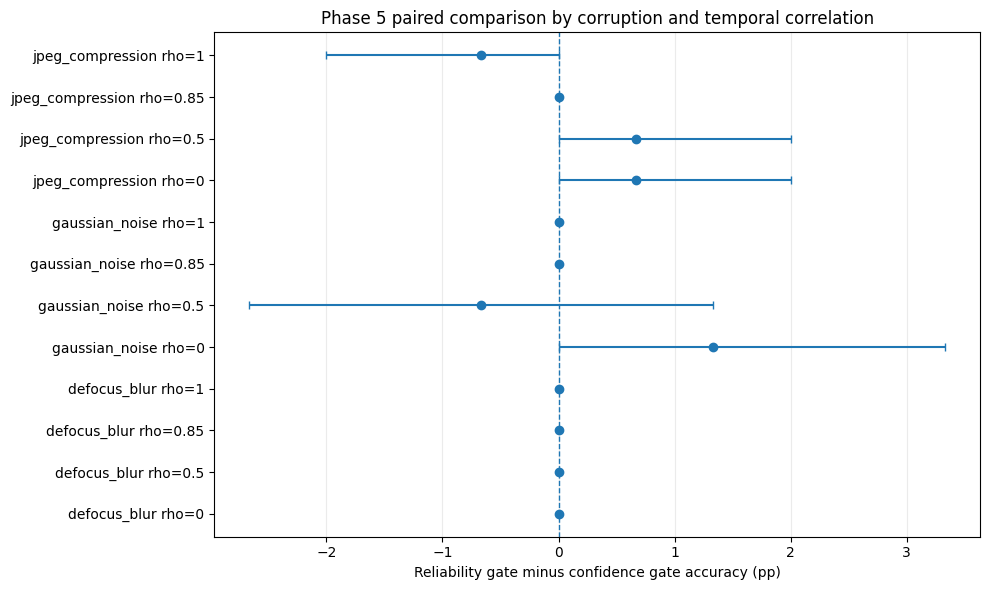


✅ Phase 6 paired analysis complete.
Condition results: /kaggle/working/phase5_v2_paired_condition_stats.csv
Overall results: /kaggle/working/phase5_v2_paired_overall_stats.csv
Figure: /kaggle/working/phase5_v2_paired_accuracy_difference.png
Checkpoint ZIP: /kaggle/working/AFML_Phase5_Paired_Stats_20261025_065248.zip
ZIP size: 0.11 MB


/kaggle/working/AFML_Phase5_Paired_Stats_20261025_065248.zip


Note: These intervals are conditional on the saved stream ordering; repeated randomized stream runs would be needed for stronger algorithm-level replication.


In [2]:
# ============================================================
# PHASE 6 — Paired Phase 5 Statistical Analysis
# UPDATED INPUT: /kaggle/input/datasets/faizz106/afml-final
# No video inference or adaptation is performed.
# ============================================================

import os
import glob
import json
import time
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

DATASET_DIR = "/kaggle/input/datasets/faizz106/afml-final"
ROOT = "/kaggle/working"

ALL_NAME = "phase5_v2_lr0.0001_all_results.csv"
SUMMARY_NAME = "phase5_v2_summary.csv"


# ------------------------------------------------------------
# 1. Locate files in Kaggle dataset and working directories
# ------------------------------------------------------------

def locate_artifact(filename, required=True):
    # Prefer the uploaded dataset so that the saved source is explicit.
    candidates = glob.glob(
        os.path.join(DATASET_DIR, "**", filename),
        recursive=True
    )
    candidates += glob.glob(
        os.path.join(ROOT, "**", filename),
        recursive=True
    )

    # Remove duplicate paths while preserving order.
    candidates = list(dict.fromkeys(
        os.path.abspath(p)
        for p in candidates
        if os.path.isfile(p)
    ))

    if not candidates:
        if required:
            raise FileNotFoundError(
                f"Could not find {filename} in:\n"
                f"  {DATASET_DIR}\n"
                f"  {ROOT}"
            )
        return None

    # Prefer a direct dataset match over any previous working copy.
    src = candidates[0]
    dst = os.path.join(ROOT, filename)

    if os.path.abspath(src) != os.path.abspath(dst):
        shutil.copy2(src, dst)
        print(f"Copied {filename} into /kaggle/working")
    else:
        print(f"Using existing working file: {filename}")

    return dst


ALL_PATH = locate_artifact(ALL_NAME, required=True)
SUMMARY_PATH = locate_artifact(SUMMARY_NAME, required=False)

print("\nInput Phase 5 results:", ALL_PATH)
if SUMMARY_PATH:
    print("Input Phase 5 summary:", SUMMARY_PATH)


# ------------------------------------------------------------
# 2. Load and validate all 12 conditions
# ------------------------------------------------------------

res = pd.read_csv(ALL_PATH)

required_columns = {
    "video", "corruption", "rho", "order",
    "source_correct", "ungated_correct",
    "conf_gate_correct", "r_gate_correct",
    "ungated_updated", "conf_gate_updated", "r_gate_updated"
}

missing = required_columns - set(res.columns)
if missing:
    raise ValueError(
        f"Missing columns in saved Phase 5 results: {sorted(missing)}"
    )

res["rho"] = res["rho"].astype(float)

expected_conditions = {
    (corruption, rho)
    for corruption in (
        "gaussian_noise",
        "defocus_blur",
        "jpeg_compression"
    )
    for rho in (0.0, 0.5, 0.85, 1.0)
}

observed_conditions = {
    (str(c), float(r))
    for c, r in res[
        ["corruption", "rho"]
    ].drop_duplicates().itertuples(index=False, name=None)
}

if observed_conditions != expected_conditions:
    raise ValueError(
        "Phase 5 condition mismatch.\n"
        f"Missing: {sorted(expected_conditions - observed_conditions)}\n"
        f"Extra: {sorted(observed_conditions - expected_conditions)}"
    )

# Confirm 150 unique held-out videos and consistent stream order
base_video_order = None

for (corruption, rho), group in res.groupby(
    ["corruption", "rho"], sort=False
):
    group = group.sort_values("order")

    if len(group) != 150 or group["video"].nunique() != 150:
        raise ValueError(
            f"{corruption}, rho={rho}: expected 150 unique videos; "
            f"got {len(group)} rows and "
            f"{group['video'].nunique()} unique videos"
        )

    order = group["order"].to_numpy(dtype=int)
    if not np.array_equal(order, np.arange(150)):
        raise ValueError(
            f"{corruption}, rho={rho}: expected order 0..149"
        )

    names = group["video"].astype(str).to_numpy()

    if base_video_order is None:
        base_video_order = names
    elif not np.array_equal(names, base_video_order):
        raise ValueError(
            f"Video ordering mismatch for {corruption}, rho={rho}"
        )

print(
    f"\n✅ Validated {len(res)} result rows, "
    "12 conditions, and 150 consistently ordered videos."
)


# ------------------------------------------------------------
# 3. Paired comparison metrics
# ------------------------------------------------------------

# Accuracy differences and coverage differences are in percentage
# points. Harmful/helpful rates are conditional on source correctness.
#
# Online adaptation is order-dependent, so we bootstrap contiguous
# blocks of stream positions rather than independent CSV rows.
# Intervals are conditional on this one saved stream ordering.

N_BOOT = 3000
BLOCK_LEN = 10
rng = np.random.default_rng(20261025)


def circular_block_indices(n, block_len, generator):
    n_blocks = int(np.ceil(n / block_len))
    starts = generator.integers(0, n, size=n_blocks)

    return np.concatenate([
        (start + np.arange(block_len)) % n
        for start in starts
    ])[:n]


def calculate_metrics(
    source,
    conf_gate,
    reliability_gate,
    ungated,
    conf_updated,
    reliability_updated
):
    arrays = [
        np.asarray(x, dtype=float)
        for x in (
            source, conf_gate, reliability_gate, ungated,
            conf_updated, reliability_updated
        )
    ]

    arrays = [
        x[:, None] if x.ndim == 1 else x
        for x in arrays
    ]

    source, conf_gate, reliability_gate, ungated, \
        conf_updated, reliability_updated = arrays

    source_correct_n = int(source.sum())
    source_wrong_n = int((1 - source).sum())

    def conditional_harm(adapted):
        if source_correct_n == 0:
            return np.nan

        return float(
            (((source == 1) & (adapted == 0)).sum())
            / source_correct_n
        )

    def conditional_help(adapted):
        if source_wrong_n == 0:
            return np.nan

        return float(
            (((source == 0) & (adapted == 1)).sum())
            / source_wrong_n
        )

    return {
        # Paired accuracy differences, in percentage points
        "r_minus_conf_accuracy_pp":
            float((reliability_gate - conf_gate).mean() * 100),

        "r_minus_ungated_accuracy_pp":
            float((reliability_gate - ungated).mean() * 100),

        "conf_minus_ungated_accuracy_pp":
            float((conf_gate - ungated).mean() * 100),

        # Conditional harmful adaptation differences
        "r_minus_conf_HAR_conditional_pp":
            float(
                (conditional_harm(reliability_gate)
                 - conditional_harm(conf_gate)) * 100
            ),

        "r_minus_ungated_HAR_conditional_pp":
            float(
                (conditional_harm(reliability_gate)
                 - conditional_harm(ungated)) * 100
            ),

        # Conditional helpful adaptation difference
        "r_minus_conf_help_conditional_pp":
            float(
                (conditional_help(reliability_gate)
                 - conditional_help(conf_gate)) * 100
            ),

        # Update coverage difference
        "r_minus_conf_update_coverage_pp":
            float(
                (reliability_updated - conf_updated).mean() * 100
            ),

        # Accuracy of each method
        "source_accuracy_pct": float(source.mean() * 100),
        "ungated_accuracy_pct": float(ungated.mean() * 100),
        "conf_gate_accuracy_pct": float(conf_gate.mean() * 100),
        "r_gate_accuracy_pct": float(reliability_gate.mean() * 100),

        # Conditional harmful adaptation rates
        "ungated_HAR_conditional_pct":
            conditional_harm(ungated) * 100,

        "conf_gate_HAR_conditional_pct":
            conditional_harm(conf_gate) * 100,

        "r_gate_HAR_conditional_pct":
            conditional_harm(reliability_gate) * 100,

        # Conditional helpful adaptation rates
        "ungated_help_conditional_pct":
            conditional_help(ungated) * 100,

        "conf_gate_help_conditional_pct":
            conditional_help(conf_gate) * 100,

        "r_gate_help_conditional_pct":
            conditional_help(reliability_gate) * 100,

        # Fraction of videos that received updates
        "conf_gate_update_coverage_pct":
            float(conf_updated.mean() * 100),

        "r_gate_update_coverage_pct":
            float(reliability_updated.mean() * 100),
    }


def bootstrap_one_condition(group):
    group = group.sort_values("order")

    columns = [
        "source_correct",
        "conf_gate_correct",
        "r_gate_correct",
        "ungated_correct",
        "conf_gate_updated",
        "r_gate_updated"
    ]

    arrays = {
        col: group[col].to_numpy(dtype=float)
        for col in columns
    }

    point = calculate_metrics(
        arrays["source_correct"],
        arrays["conf_gate_correct"],
        arrays["r_gate_correct"],
        arrays["ungated_correct"],
        arrays["conf_gate_updated"],
        arrays["r_gate_updated"]
    )

    boot_values = {key: [] for key in point}

    for _ in range(N_BOOT):
        idx = circular_block_indices(
            len(group), BLOCK_LEN, rng
        )

        values = calculate_metrics(
            arrays["source_correct"][idx],
            arrays["conf_gate_correct"][idx],
            arrays["r_gate_correct"][idx],
            arrays["ungated_correct"][idx],
            arrays["conf_gate_updated"][idx],
            arrays["r_gate_updated"][idx]
        )

        for key, value in values.items():
            if np.isfinite(value):
                boot_values[key].append(value)

    output = {}

    for key, estimate in point.items():
        samples = np.asarray(boot_values[key], dtype=float)
        output[key] = estimate

        if key.endswith("_pp"):
            base = key[:-3]
            low_key = f"{base}_ci_low_pp"
            high_key = f"{base}_ci_high_pp"
        else:
            low_key = f"{key}_ci_low"
            high_key = f"{key}_ci_high"

        output[low_key] = (
            float(np.quantile(samples, 0.025))
            if len(samples) else np.nan
        )
        output[high_key] = (
            float(np.quantile(samples, 0.975))
            if len(samples) else np.nan
        )

    return output


# ------------------------------------------------------------
# 4. Per-condition paired comparisons
# ------------------------------------------------------------

condition_rows = []

for (corruption, rho), group in res.groupby(
    ["corruption", "rho"], sort=False
):
    metrics = bootstrap_one_condition(group)

    metrics.update({
        "corruption": corruption,
        "rho": float(rho),
        "n": len(group),
        "bootstrap": "circular moving blocks, length 10"
    })

    condition_rows.append(metrics)

condition_stats = (
    pd.DataFrame(condition_rows)
    .sort_values(["corruption", "rho"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Overall macro-average across the 12 conditions
# ------------------------------------------------------------

def make_matrix(column):
    wide = res.pivot(
        index="order",
        columns=["corruption", "rho"],
        values=column
    ).sort_index(axis=1).sort_index()

    if wide.shape != (150, 12) or wide.isna().any().any():
        raise ValueError(
            f"Unexpected shape or missing values for {column}: "
            f"{wide.shape}"
        )

    return wide.to_numpy(dtype=float)


matrix_columns = [
    "source_correct",
    "ungated_correct",
    "conf_gate_correct",
    "r_gate_correct",
    "conf_gate_updated",
    "r_gate_updated"
]

matrices = {
    column: make_matrix(column)
    for column in matrix_columns
}

overall_point = calculate_metrics(
    matrices["source_correct"],
    matrices["conf_gate_correct"],
    matrices["r_gate_correct"],
    matrices["ungated_correct"],
    matrices["conf_gate_updated"],
    matrices["r_gate_updated"]
)

overall_boot = {key: [] for key in overall_point}

for _ in range(N_BOOT):
    idx = circular_block_indices(150, BLOCK_LEN, rng)

    metrics = calculate_metrics(
        matrices["source_correct"][idx, :],
        matrices["conf_gate_correct"][idx, :],
        matrices["r_gate_correct"][idx, :],
        matrices["ungated_correct"][idx, :],
        matrices["conf_gate_updated"][idx, :],
        matrices["r_gate_updated"][idx, :]
    )

    for key, value in metrics.items():
        if np.isfinite(value):
            overall_boot[key].append(value)

overall_rows = []

for metric, estimate in overall_point.items():
    samples = np.asarray(overall_boot[metric], dtype=float)

    overall_rows.append({
        "metric": metric,
        "estimate": estimate,
        "ci_low": (
            float(np.quantile(samples, 0.025))
            if len(samples) else np.nan
        ),
        "ci_high": (
            float(np.quantile(samples, 0.975))
            if len(samples) else np.nan
        ),
        "n_videos": 150,
        "n_conditions": 12,
        "bootstrap": (
            f"{N_BOOT} circular block resamples; "
            f"block length {BLOCK_LEN}"
        )
    })

overall_stats = pd.DataFrame(overall_rows)


# ------------------------------------------------------------
# 6. Save tables and print results
# ------------------------------------------------------------

OUT_COND = (
    f"{ROOT}/phase5_v2_paired_condition_stats.csv"
)
OUT_OVERALL = (
    f"{ROOT}/phase5_v2_paired_overall_stats.csv"
)

condition_stats.to_csv(OUT_COND, index=False)
overall_stats.to_csv(OUT_OVERALL, index=False)

print("\n" + "=" * 75)
print("OVERALL PAIRED COMPARISON")
print("Differences are percentage points.")
print("=" * 75)

print(
    overall_stats[
        overall_stats["metric"].str.contains("minus")
    ].round(3).to_string(index=False)
)

print("\n" + "=" * 75)
print("PER-CONDITION: RELIABILITY GATE VS CONFIDENCE GATE")
print("=" * 75)

columns_to_show = [
    "corruption",
    "rho",
    "r_minus_conf_accuracy_pp",
    "r_minus_conf_accuracy_ci_low_pp",
    "r_minus_conf_accuracy_ci_high_pp",
    "r_minus_conf_HAR_conditional_pp",
    "r_minus_conf_HAR_conditional_ci_low_pp",
    "r_minus_conf_HAR_conditional_ci_high_pp",
    "r_minus_conf_update_coverage_pp"
]

print(
    condition_stats[columns_to_show]
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 7. Plot accuracy differences
# ------------------------------------------------------------

plot_df = condition_stats.copy()

plot_df["label"] = (
    plot_df["corruption"]
    + " rho="
    + plot_df["rho"].map(lambda x: f"{x:g}")
)

plot_df = plot_df.sort_values(
    ["corruption", "rho"]
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(plot_df))

low = plot_df[
    "r_minus_conf_accuracy_ci_low_pp"
].to_numpy()

high = plot_df[
    "r_minus_conf_accuracy_ci_high_pp"
].to_numpy()

estimate = plot_df[
    "r_minus_conf_accuracy_pp"
].to_numpy()

ax.errorbar(
    estimate,
    y,
    xerr=[
        np.maximum(0, estimate - low),
        np.maximum(0, high - estimate)
    ],
    fmt="o",
    capsize=3
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(plot_df["label"])
ax.set_xlabel(
    "Reliability gate minus confidence gate accuracy (pp)"
)
ax.set_title(
    "Phase 5 paired comparison by corruption and temporal correlation"
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

FIG_PATH = (
    f"{ROOT}/phase5_v2_paired_accuracy_difference.png"
)

fig.savefig(FIG_PATH, dpi=200, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 8. Package analysis checkpoint
# ------------------------------------------------------------

stamp = time.strftime("%Y%m%d_%H%M%S")

ZIP_PATH = (
    f"{ROOT}/AFML_Phase5_Paired_Stats_{stamp}.zip"
)

files_to_package = [
    ALL_PATH,
    SUMMARY_PATH,
    OUT_COND,
    OUT_OVERALL,
    FIG_PATH
]

manifest = {
    "analysis": "Paired Phase 5 comparison",
    "input_dataset": DATASET_DIR,
    "conditions": 12,
    "held_out_videos": 150,
    "bootstrap": "Circular moving-block bootstrap",
    "block_length": BLOCK_LEN,
    "replicates": N_BOOT,
    "interpretation": (
        "Intervals quantify uncertainty conditional on the one "
        "saved stream ordering. They do not replace repeated "
        "randomized stream-order runs."
    )
}

with zipfile.ZipFile(
    ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zf:
    for path in files_to_package:
        if os.path.isfile(path):
            zf.write(
                path,
                arcname=os.path.basename(path)
            )

    zf.writestr(
        "analysis_manifest.json",
        json.dumps(manifest, indent=2)
    )

print("\n✅ Phase 6 paired analysis complete.")
print("Condition results:", OUT_COND)
print("Overall results:", OUT_OVERALL)
print("Figure:", FIG_PATH)
print("Checkpoint ZIP:", ZIP_PATH)
print(
    "ZIP size: %.2f MB"
    % (os.path.getsize(ZIP_PATH) / (1024 ** 2))
)

display(FileLink(ZIP_PATH))

print(
    "\nNote: These intervals are conditional on the saved stream "
    "ordering; repeated randomized stream runs would be needed "
    "for stronger algorithm-level replication."
)


Phase 5 input: /kaggle/working/phase5_full_v2_lr0.0001_all_results.csv
File size: 0.37 MB

PHASE 5 RESULTS VALIDATED
Rows: 6000
Unique videos in stream: 150
Conditions: 40
Videos per condition: 150
Methods: vitta_style, conf_gate, r_gate

PHASE 6 — OVERALL METHOD SUMMARY
                      method  accuracy_pct  accuracy_ci_low  accuracy_ci_high  gain_over_source_pp  update_coverage_pct
                Source model        54.250           48.616            59.500                0.000                0.000
ViTTA-style entropy baseline        54.333           48.899            59.384                0.083              100.000
             Confidence gate        55.050           49.500            60.183                0.800               47.183
     Reliability gate (ours)        55.133           49.650            60.250                0.883               47.367

OVERALL PAIRED ACCURACY DIFFERENCES
Reliability gate minus confidence gate (pp): 0.083 (95% block-bootstrap CI 0.000 to 0.183)

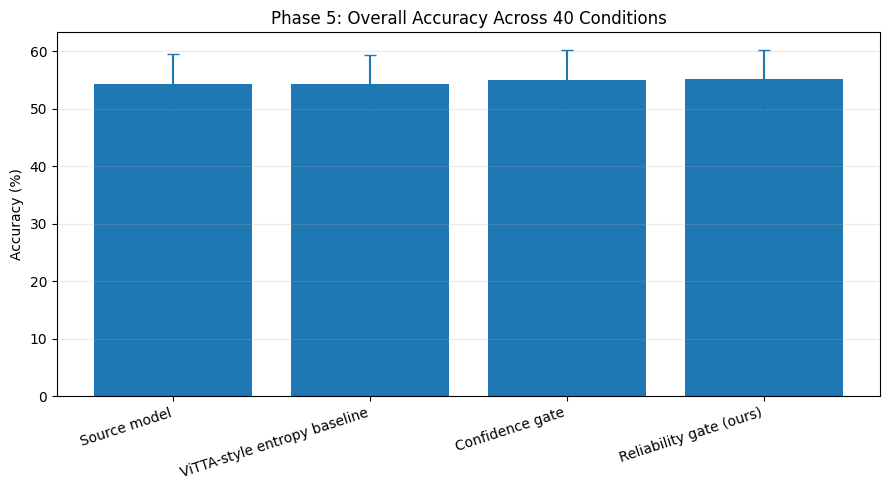

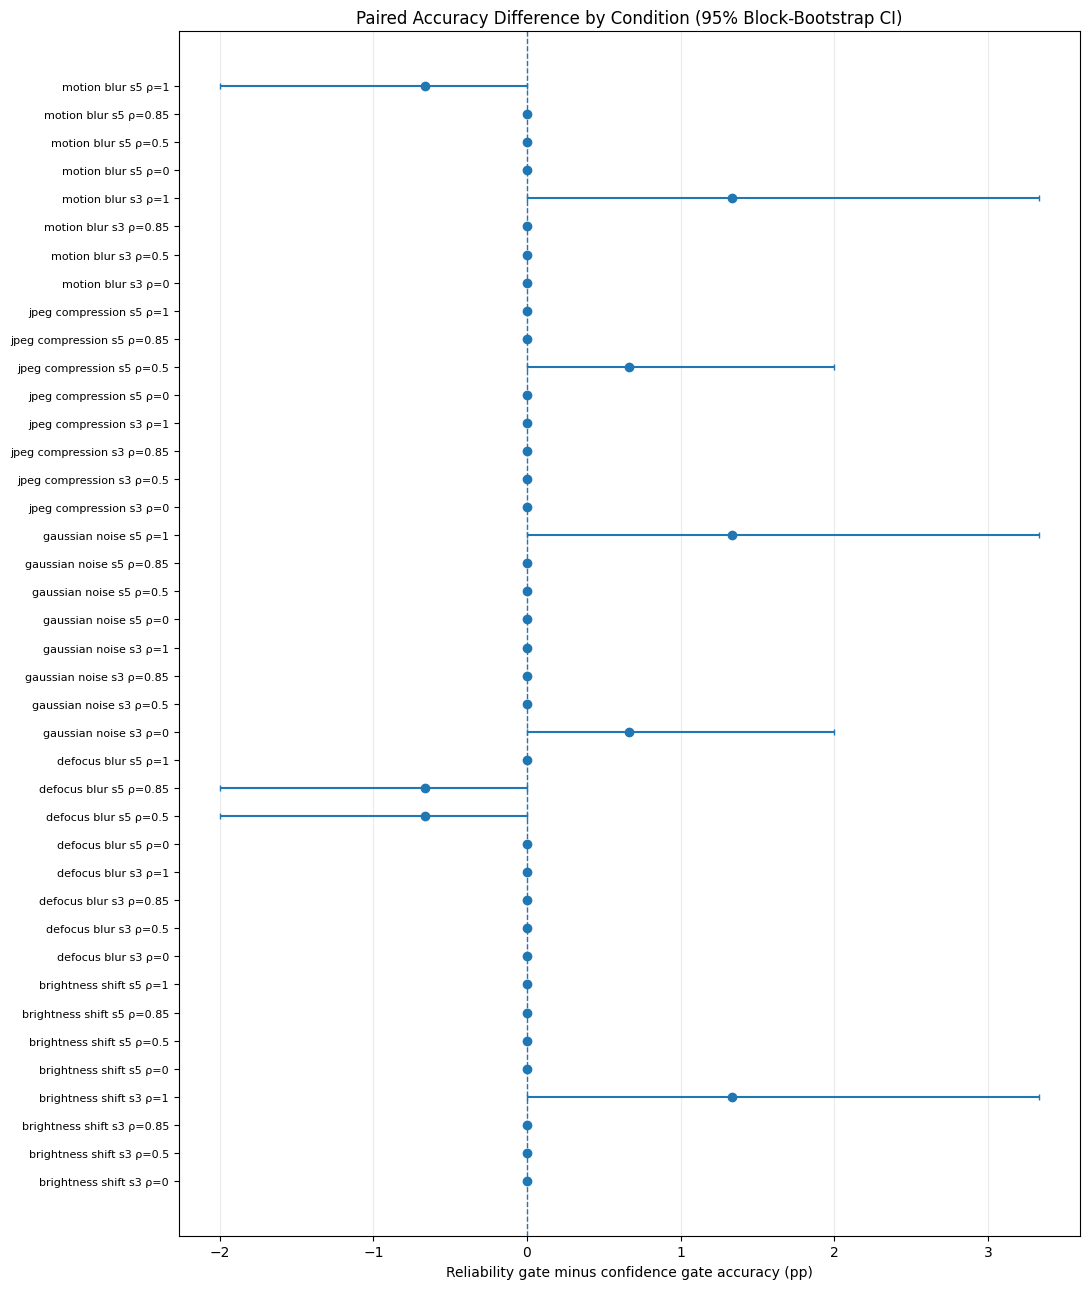

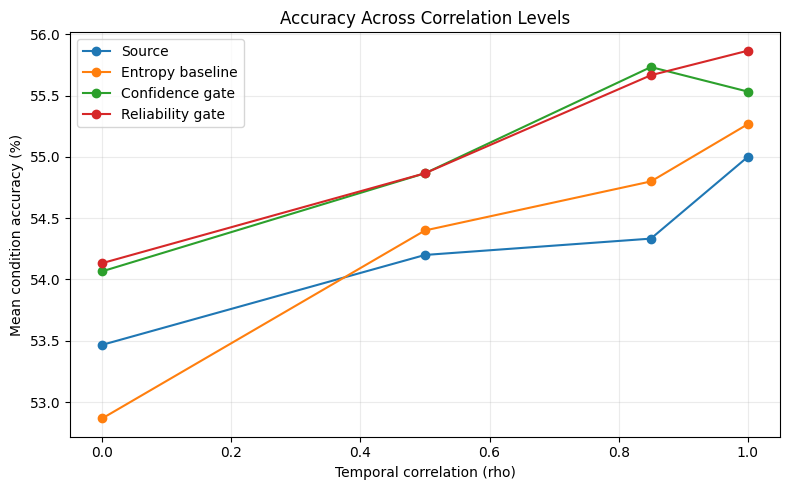


✅ PHASE 6 FULL ANALYSIS COMPLETE
Condition table: /kaggle/working/phase6_full_v2_condition_metrics.csv
Overall metrics: /kaggle/working/phase6_full_v2_overall_metrics.csv
Method summary: /kaggle/working/phase6_full_v2_method_summary.csv
By corruption/severity: /kaggle/working/phase6_full_v2_by_corruption_severity.csv
By rho: /kaggle/working/phase6_full_v2_by_rho.csv
Analysis ZIP: /kaggle/working/AFML_Phase6_Full_Analysis_20261026_182523.zip
ZIP size: 0.44 MB


/kaggle/working/AFML_Phase6_Full_Analysis_20261026_182523.zip


Next: inspect the overall paired differences and their 95% intervals. An interval containing zero does not provide clear evidence of a difference under this bootstrap; it does not prove the methods are equal.


In [16]:
# ============================================================
# PHASE 6 — FINAL STATISTICAL ANALYSIS (FULL 40-CONDITION MATRIX)
#
# Input:
#   phase5_full_v2_lr0.0001_all_results.csv  (6,000 rows)
#   phase5_full_v2_summary.csv              (120 rows, optional)
#
# Methods:
#   vitta_style = ungated entropy-minimization comparator
#   conf_gate   = confidence-gated adaptation
#   r_gate      = proposed reliability-gated adaptation
#
# Outputs:
#   Per-condition statistics and paired bootstrap CIs
#   Overall accuracy, gains, help/harm transition metrics
#   Corruption/severity and correlation summaries
#   Figures + downloadable analysis ZIP
#
# IMPORTANT:
#   No model inference or adaptation runs in this cell.
# ============================================================

import os
import glob
import json
import time
import zipfile
import shutil
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working")
ROOT.mkdir(parents=True, exist_ok=True)

ALL_NAME = "phase5_full_v2_lr0.0001_all_results.csv"
SUMMARY_NAME = "phase5_full_v2_summary.csv"

CORRUPTIONS = [
    "gaussian_noise",
    "defocus_blur",
    "motion_blur",
    "jpeg_compression",
    "brightness_shift",
]
SEVERITIES = [3, 5]
RHOS = [0.0, 0.5, 0.85, 1.0]

N_BOOT = 3000
BLOCK_LEN = 10
SEED = 20261026

rng = np.random.default_rng(SEED)


# ------------------------------------------------------------
# 1. Locate the final Phase 5 data
# ------------------------------------------------------------

ALL_PATH = ROOT / ALL_NAME
SUMMARY_PATH = ROOT / SUMMARY_NAME

if not ALL_PATH.is_file():
    # Search attached Kaggle datasets for the aggregate CSV.
    matches = glob.glob(
        f"/kaggle/input/**/{ALL_NAME}",
        recursive=True
    )

    if matches:
        shutil.copy2(matches[0], ALL_PATH)
        print("Restored Phase 5 results from:", matches[0])

if not ALL_PATH.is_file():
    # If only the final checkpoint ZIP is attached, extract the
    # aggregate results and summary from that ZIP.
    archives = glob.glob(
        "/kaggle/input/**/AFML_Phase5_FullMatrix_Checkpoint_*40of40.zip",
        recursive=True
    )

    if not archives:
        raise FileNotFoundError(
            f"Cannot find {ALL_NAME} or a complete 40/40 checkpoint ZIP.\n"
            "Attach the final Phase 5 checkpoint as a Kaggle input, "
            "or restore the final aggregate CSV to /kaggle/working."
        )

    # Timestamped filenames sort chronologically.
    checkpoint = sorted(archives)[-1]
    print("Reading completed checkpoint:", checkpoint)

    with zipfile.ZipFile(checkpoint, "r") as zf:
        available = {
            Path(info.filename).name: info
            for info in zf.infolist()
            if not info.is_dir()
        }

        if ALL_NAME not in available:
            raise FileNotFoundError(
                f"{ALL_NAME} is not present in {checkpoint}"
            )

        with zf.open(available[ALL_NAME]) as src:
            ALL_PATH.write_bytes(src.read())

        if SUMMARY_NAME in available:
            with zf.open(available[SUMMARY_NAME]) as src:
                SUMMARY_PATH.write_bytes(src.read())

print("\nPhase 5 input:", ALL_PATH)
print("File size: %.2f MB" % (ALL_PATH.stat().st_size / 1024**2))


# ------------------------------------------------------------
# 2. Load and strictly validate the full result matrix
# ------------------------------------------------------------

df = pd.read_csv(ALL_PATH)

required = [
    "video", "corruption", "severity", "rho", "order",
    "source_correct",
    "vitta_style_correct", "vitta_style_updated",
    "conf_gate_correct", "conf_gate_updated",
    "r_gate_correct", "r_gate_updated",
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns in Phase 5 CSV: {missing}")

df["video"] = df["video"].astype(str)
df["corruption"] = df["corruption"].astype(str)
df["severity"] = pd.to_numeric(df["severity"], errors="raise").astype(int)
df["rho"] = pd.to_numeric(df["rho"], errors="raise").round(2)
df["order"] = pd.to_numeric(df["order"], errors="raise").astype(int)

binary_cols = [
    "source_correct",
    "vitta_style_correct", "vitta_style_updated",
    "conf_gate_correct", "conf_gate_updated",
    "r_gate_correct", "r_gate_updated",
]

for c in binary_cols:
    df[c] = pd.to_numeric(df[c], errors="raise").astype(int)

    if not set(df[c].unique()).issubset({0, 1}):
        raise ValueError(f"{c} contains values other than 0 and 1.")

expected_conditions = set(product(CORRUPTIONS, SEVERITIES, RHOS))

observed_conditions = set(
    zip(
        df["corruption"],
        df["severity"],
        df["rho"]
    )
)

if observed_conditions != expected_conditions:
    raise ValueError(
        "The completed condition matrix is incorrect.\n"
        f"Missing: {sorted(expected_conditions - observed_conditions)}\n"
        f"Unexpected: {sorted(observed_conditions - expected_conditions)}"
    )

if len(df) != 6000:
    raise ValueError(f"Expected 6,000 rows; found {len(df)}.")

if df.duplicated(["corruption", "severity", "rho", "order"]).any():
    raise ValueError("Duplicate rows detected for a condition/order pair.")

# Confirm 150 ordered videos in each condition, with consistent
# stream identity and order across all 40 conditions.
base_order = None

for key, group in df.groupby(
    ["corruption", "severity", "rho"], sort=False
):
    group = group.sort_values("order")

    if len(group) != 150 or group["video"].nunique() != 150:
        raise ValueError(f"{key}: expected 150 unique videos.")

    if not np.array_equal(group["order"].to_numpy(), np.arange(150)):
        raise ValueError(f"{key}: order must be 0 through 149.")

    current_order = group["video"].to_numpy()

    if base_order is None:
        base_order = current_order
    elif not np.array_equal(current_order, base_order):
        raise ValueError(
            f"{key}: video stream/order differs from other conditions."
        )

df = df.sort_values(
    ["corruption", "severity", "rho", "order"]
).reset_index(drop=True)

print("\n" + "=" * 70)
print("PHASE 5 RESULTS VALIDATED")
print("=" * 70)
print("Rows:", len(df))
print("Unique videos in stream:", df["video"].nunique())
print("Conditions:", len(observed_conditions))
print("Videos per condition: 150")
print("Methods: vitta_style, conf_gate, r_gate")


# ------------------------------------------------------------
# 3. Metric definitions
# ------------------------------------------------------------
#
# Accuracy: percentage correct.
# Gain: method accuracy minus source accuracy, in percentage points.
#
# Harmful transition:
#   Source prediction was correct, method prediction was incorrect.
#
# Helpful transition:
#   Source prediction was incorrect, method prediction was correct.
#
# Conditional harmful/helpful rates use source-correct/source-wrong
# cases as their respective denominators.
#
# Important protocol caveat:
# The runner predicts on each video BEFORE performing that video's
# optimizer update. Therefore the "updated" flag on a row describes
# the update after that row's prediction. It must not be interpreted
# as the direct causal effect of that same-row update.
# Transition metrics below compare the stream's method predictions
# against the frozen source model; they do not isolate each update's
# immediate causal effect.
# ------------------------------------------------------------

METHODS = {
    "vitta_style": "ViTTA-style entropy baseline",
    "conf_gate": "Confidence gate",
    "r_gate": "Reliability gate (ours)",
}


def safe_div(num, den):
    return float(num / den) if den > 0 else np.nan


def calculate_metrics(arr):
    """
    Calculate metrics over 1-D arrays for one condition OR
    2-D arrays of shape (stream positions, conditions) overall.
    Every array is aligned by video order.
    """
    source = np.asarray(arr["source_correct"], dtype=float)
    vitta = np.asarray(arr["vitta_style_correct"], dtype=float)
    conf = np.asarray(arr["conf_gate_correct"], dtype=float)
    reli = np.asarray(arr["r_gate_correct"], dtype=float)

    upd_vitta = np.asarray(arr["vitta_style_updated"], dtype=float)
    upd_conf = np.asarray(arr["conf_gate_updated"], dtype=float)
    upd_reli = np.asarray(arr["r_gate_updated"], dtype=float)

    source_correct_n = int((source == 1).sum())
    source_wrong_n = int((source == 0).sum())

    def accuracy(a):
        return float(np.mean(a) * 100)

    def harmful_conditional(a):
        # Among source-correct cases, how often is the method wrong?
        return safe_div(
            int(((source == 1) & (a == 0)).sum()),
            source_correct_n
        ) * 100 if source_correct_n else np.nan

    def helpful_conditional(a):
        # Among source-wrong cases, how often is the method correct?
        return safe_div(
            int(((source == 0) & (a == 1)).sum()),
            source_wrong_n
        ) * 100 if source_wrong_n else np.nan

    def harmful_unconditional(a):
        return float(((source == 1) & (a == 0)).mean() * 100)

    def helpful_unconditional(a):
        return float(((source == 0) & (a == 1)).mean() * 100)

    out = {
        "source_accuracy_pct": accuracy(source),
        "vitta_accuracy_pct": accuracy(vitta),
        "conf_accuracy_pct": accuracy(conf),
        "r_accuracy_pct": accuracy(reli),

        "vitta_gain_pp": accuracy(vitta) - accuracy(source),
        "conf_gain_pp": accuracy(conf) - accuracy(source),
        "r_gain_pp": accuracy(reli) - accuracy(source),

        "r_minus_conf_accuracy_pp": accuracy(reli) - accuracy(conf),
        "r_minus_vitta_accuracy_pp": accuracy(reli) - accuracy(vitta),
        "conf_minus_vitta_accuracy_pp": accuracy(conf) - accuracy(vitta),

        "vitta_harm_conditional_pct": harmful_conditional(vitta),
        "conf_harm_conditional_pct": harmful_conditional(conf),
        "r_harm_conditional_pct": harmful_conditional(reli),

        "vitta_help_conditional_pct": helpful_conditional(vitta),
        "conf_help_conditional_pct": helpful_conditional(conf),
        "r_help_conditional_pct": helpful_conditional(reli),

        "vitta_harm_unconditional_pct": harmful_unconditional(vitta),
        "conf_harm_unconditional_pct": harmful_unconditional(conf),
        "r_harm_unconditional_pct": harmful_unconditional(reli),

        "vitta_help_unconditional_pct": helpful_unconditional(vitta),
        "conf_help_unconditional_pct": helpful_unconditional(conf),
        "r_help_unconditional_pct": helpful_unconditional(reli),

        "vitta_update_coverage_pct": float(np.mean(upd_vitta) * 100),
        "conf_update_coverage_pct": float(np.mean(upd_conf) * 100),
        "r_update_coverage_pct": float(np.mean(upd_reli) * 100),

        "r_minus_conf_harm_conditional_pp":
            harmful_conditional(reli) - harmful_conditional(conf),

        "r_minus_vitta_harm_conditional_pp":
            harmful_conditional(reli) - harmful_conditional(vitta),

        "r_minus_conf_help_conditional_pp":
            helpful_conditional(reli) - helpful_conditional(conf),

        "r_minus_vitta_help_conditional_pp":
            helpful_conditional(reli) - helpful_conditional(vitta),

        "r_minus_conf_update_coverage_pp":
            float(np.mean(upd_reli) * 100 - np.mean(upd_conf) * 100),
    }

    return out


def arrays_from_frame(group):
    group = group.sort_values("order")

    return {
        c: group[c].to_numpy(dtype=float)
        for c in binary_cols
    }


# ------------------------------------------------------------
# 4. Paired circular-block bootstrap
# ------------------------------------------------------------
#
# Online adaptation is order-dependent. Bootstrap contiguous blocks
# of stream positions rather than treating every CSV row as
# independent. These intervals are conditional on this saved stream
# and order; they do not replace repeated stream-order experiments.
# ------------------------------------------------------------

def circular_block_indices(n, block_len, generator):
    n_blocks = int(np.ceil(n / block_len))
    starts = generator.integers(0, n, size=n_blocks)

    idx = np.concatenate([
        (s + np.arange(block_len)) % n
        for s in starts
    ])

    return idx[:n]


def bootstrap_metrics(arr, n_boot=N_BOOT):
    point = calculate_metrics(arr)
    samples = {key: [] for key in point}

    # All arrays have the same number of stream positions on axis 0.
    n = len(arr["source_correct"])

    for _ in range(n_boot):
        idx = circular_block_indices(n, BLOCK_LEN, rng)

        resampled = {
            key: value[idx, ...]
            for key, value in arr.items()
        }

        metrics = calculate_metrics(resampled)

        for key, value in metrics.items():
            if np.isfinite(value):
                samples[key].append(value)

    result = {}

    for key, estimate in point.items():
        vals = np.asarray(samples[key], dtype=float)

        result[key] = estimate
        result[f"{key}_ci_low"] = (
            float(np.quantile(vals, 0.025)) if len(vals) else np.nan
        )
        result[f"{key}_ci_high"] = (
            float(np.quantile(vals, 0.975)) if len(vals) else np.nan
        )

    return result


# ------------------------------------------------------------
# 5. Per-condition analysis: 40 conditions
# ------------------------------------------------------------

condition_rows = []

for (corruption, severity, rho), group in df.groupby(
    ["corruption", "severity", "rho"], sort=True
):
    arrays = arrays_from_frame(group)
    stats = bootstrap_metrics(arrays)

    stats.update({
        "corruption": corruption,
        "severity": int(severity),
        "rho": float(rho),
        "n_videos": len(group),
        "bootstrap": f"{N_BOOT} circular-block resamples, block={BLOCK_LEN}",
    })

    condition_rows.append(stats)

condition_stats = pd.DataFrame(condition_rows).sort_values(
    ["corruption", "severity", "rho"]
).reset_index(drop=True)

condition_path = ROOT / "phase6_full_v2_condition_metrics.csv"
condition_stats.to_csv(condition_path, index=False)


# ------------------------------------------------------------
# 6. Overall analysis: all 6,000 video-condition rows
# ------------------------------------------------------------

def make_matrix(column):
    wide = df.pivot(
        index="order",
        columns=["corruption", "severity", "rho"],
        values=column
    ).sort_index(axis=1).sort_index()

    if wide.shape != (150, 40) or wide.isna().any().any():
        raise ValueError(
            f"Invalid matrix for {column}: shape={wide.shape}"
        )

    return wide.to_numpy(dtype=float)


matrices = {column: make_matrix(column) for column in binary_cols}

overall_boot = bootstrap_metrics(matrices)

overall_rows = []

for metric, estimate in calculate_metrics(matrices).items():
    overall_rows.append({
        "metric": metric,
        "estimate": estimate,
        "ci_low": overall_boot[f"{metric}_ci_low"],
        "ci_high": overall_boot[f"{metric}_ci_high"],
        "n_videos_per_condition": 150,
        "n_conditions": 40,
        "n_video_condition_rows": 6000,
        "bootstrap": f"{N_BOOT} circular-block resamples, block={BLOCK_LEN}",
    })

overall_stats = pd.DataFrame(overall_rows)

overall_path = ROOT / "phase6_full_v2_overall_metrics.csv"
overall_stats.to_csv(overall_path, index=False)


# ------------------------------------------------------------
# 7. Easy-to-read method summary
# ------------------------------------------------------------

overall_lookup = overall_stats.set_index("metric")

method_metric_keys = {
    "Source model": ("source_accuracy_pct", None, None),
    "ViTTA-style entropy baseline": (
        "vitta_accuracy_pct", "vitta_gain_pp", "vitta_update_coverage_pct"
    ),
    "Confidence gate": (
        "conf_accuracy_pct", "conf_gain_pp", "conf_update_coverage_pct"
    ),
    "Reliability gate (ours)": (
        "r_accuracy_pct", "r_gain_pp", "r_update_coverage_pct"
    ),
}

method_rows = []

for name, (acc_key, gain_key, coverage_key) in method_metric_keys.items():
    acc_row = overall_lookup.loc[acc_key]

    row = {
        "method": name,
        "accuracy_pct": acc_row["estimate"],
        "accuracy_ci_low": acc_row["ci_low"],
        "accuracy_ci_high": acc_row["ci_high"],
        "gain_over_source_pp": (
            overall_lookup.loc[gain_key, "estimate"]
            if gain_key else 0.0
        ),
        "update_coverage_pct": (
            overall_lookup.loc[coverage_key, "estimate"]
            if coverage_key else 0.0
        ),
    }
    method_rows.append(row)

method_summary = pd.DataFrame(method_rows)

method_path = ROOT / "phase6_full_v2_method_summary.csv"
method_summary.to_csv(method_path, index=False)


# ------------------------------------------------------------
# 8. Macro summaries by corruption/severity and by rho
# ------------------------------------------------------------
#
# Each condition has equal video count, so averaging condition-level
# metrics produces an equal-condition macro average. These grouped
# tables are descriptive summaries; their intervals are not pooled
# grouped bootstrap intervals.
# ------------------------------------------------------------

metric_cols = [
    "source_accuracy_pct",
    "vitta_accuracy_pct",
    "conf_accuracy_pct",
    "r_accuracy_pct",
    "vitta_gain_pp",
    "conf_gain_pp",
    "r_gain_pp",
    "r_minus_conf_accuracy_pp",
    "r_minus_vitta_accuracy_pp",
    "conf_minus_vitta_accuracy_pp",
    "vitta_harm_conditional_pct",
    "conf_harm_conditional_pct",
    "r_harm_conditional_pct",
    "vitta_help_conditional_pct",
    "conf_help_conditional_pct",
    "r_help_conditional_pct",
    "vitta_update_coverage_pct",
    "conf_update_coverage_pct",
    "r_update_coverage_pct",
]

by_corruption_severity = (
    condition_stats
    .groupby(["corruption", "severity"], as_index=False)[metric_cols]
    .mean()
)

by_rho = (
    condition_stats
    .groupby("rho", as_index=False)[metric_cols]
    .mean()
)

by_corruption_path = ROOT / "phase6_full_v2_by_corruption_severity.csv"
by_rho_path = ROOT / "phase6_full_v2_by_rho.csv"

by_corruption_severity.to_csv(by_corruption_path, index=False)
by_rho.to_csv(by_rho_path, index=False)


# ------------------------------------------------------------
# 9. Print final results
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("PHASE 6 — OVERALL METHOD SUMMARY")
print("=" * 85)

print(
    method_summary.round(3).to_string(index=False)
)

def print_metric(key, label):
    row = overall_lookup.loc[key]
    print(
        f"{label}: {row['estimate']:.3f} "
        f"(95% block-bootstrap CI "
        f"{row['ci_low']:.3f} to {row['ci_high']:.3f})"
    )

print("\nOVERALL PAIRED ACCURACY DIFFERENCES")
print_metric(
    "r_minus_conf_accuracy_pp",
    "Reliability gate minus confidence gate (pp)"
)
print_metric(
    "r_minus_vitta_accuracy_pp",
    "Reliability gate minus entropy baseline (pp)"
)
print_metric(
    "conf_minus_vitta_accuracy_pp",
    "Confidence gate minus entropy baseline (pp)"
)

print("\nCONDITIONAL HARMFUL TRANSITIONS")
print_metric(
    "vitta_harm_conditional_pct",
    "Entropy baseline: source-correct -> method-wrong (%)"
)
print_metric(
    "conf_harm_conditional_pct",
    "Confidence gate: source-correct -> method-wrong (%)"
)
print_metric(
    "r_harm_conditional_pct",
    "Reliability gate: source-correct -> method-wrong (%)"
)

print("\n" + "=" * 85)
print("RELIABILITY GATE VS CONFIDENCE GATE — ALL 40 CONDITIONS")
print("=" * 85)

display_cols = [
    "corruption", "severity", "rho",
    "r_accuracy_pct", "conf_accuracy_pct",
    "r_minus_conf_accuracy_pp",
    "r_minus_conf_accuracy_pp_ci_low",
    "r_minus_conf_accuracy_pp_ci_high",
]

print(
    condition_stats[display_cols]
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 10. Plots
# ------------------------------------------------------------

# Plot A: overall method accuracy
fig, ax = plt.subplots(figsize=(9, 5))

plot_data = method_summary
x = np.arange(len(plot_data))

err_low = (
    plot_data["accuracy_pct"] - plot_data["accuracy_ci_low"]
).to_numpy()
err_high = (
    plot_data["accuracy_ci_high"] - plot_data["accuracy_pct"]
).to_numpy()

ax.bar(x, plot_data["accuracy_pct"])
ax.errorbar(
    x,
    plot_data["accuracy_pct"],
    yerr=np.vstack([err_low, err_high]),
    fmt="none",
    capsize=4
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data["method"], rotation=18, ha="right")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Phase 5: Overall Accuracy Across 40 Conditions")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

plot_accuracy_path = ROOT / "phase6_full_v2_overall_accuracy.png"
fig.savefig(plot_accuracy_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)


# Plot B: Reliability minus confidence by condition
plot_df = condition_stats.sort_values(
    ["corruption", "severity", "rho"]
).reset_index(drop=True)

labels = [
    f"{r.corruption.replace('_', ' ')} s{r.severity} ρ={r.rho:g}"
    for r in plot_df.itertuples()
]

estimate = plot_df["r_minus_conf_accuracy_pp"].to_numpy()
low = plot_df["r_minus_conf_accuracy_pp_ci_low"].to_numpy()
high = plot_df["r_minus_conf_accuracy_pp_ci_high"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 13))
y = np.arange(len(plot_df))

ax.errorbar(
    estimate, y,
    xerr=np.vstack([
        np.maximum(0, estimate - low),
        np.maximum(0, high - estimate)
    ]),
    fmt="o", capsize=2
)

ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel("Reliability gate minus confidence gate accuracy (pp)")
ax.set_title("Paired Accuracy Difference by Condition (95% Block-Bootstrap CI)")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

plot_difference_path = ROOT / "phase6_full_v2_r_minus_conf_by_condition.png"
fig.savefig(plot_difference_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)


# Plot C: performance as temporal correlation varies
fig, ax = plt.subplots(figsize=(8, 5))

for key, label in [
    ("source_accuracy_pct", "Source"),
    ("vitta_accuracy_pct", "Entropy baseline"),
    ("conf_accuracy_pct", "Confidence gate"),
    ("r_accuracy_pct", "Reliability gate"),
]:
    ax.plot(by_rho["rho"], by_rho[key], marker="o", label=label)

ax.set_xlabel("Temporal correlation (rho)")
ax.set_ylabel("Mean condition accuracy (%)")
ax.set_title("Accuracy Across Correlation Levels")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()

plot_rho_path = ROOT / "phase6_full_v2_accuracy_by_rho.png"
fig.savefig(plot_rho_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 11. Save manifest and package all deliverables
# ------------------------------------------------------------

stamp = time.strftime("%Y%m%d_%H%M%S")
manifest = {
    "phase": 6,
    "analysis": "Full Phase 5 paired statistical analysis",
    "input_file": ALL_NAME,
    "rows": 6000,
    "conditions": 40,
    "videos_per_condition": 150,
    "methods": list(METHODS.keys()),
    "bootstrap": {
        "method": "circular moving-block bootstrap",
        "replicates": N_BOOT,
        "block_length": BLOCK_LEN,
        "seed": SEED,
    },
    "interpretation_notes": [
        "Intervals are conditional on one saved video stream order.",
        "Condition-wise intervals are exploratory and are not corrected "
        "for 40 simultaneous comparisons.",
        "Each method predicts the current video before its current-row "
        "optimizer update. Help/harm transition metrics compare stream "
        "outcomes to the source model; they do not isolate the causal "
        "effect of the current-row update.",
        "The vitta_style comparator is ungated entropy minimization, "
        "not a verified exact reproduction of published ViTTA.",
    ],
}

manifest_path = ROOT / "phase6_full_v2_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2))

zip_path = ROOT / f"AFML_Phase6_Full_Analysis_{stamp}.zip"

files_to_package = [
    ALL_PATH,
    SUMMARY_PATH,
    condition_path,
    overall_path,
    method_path,
    by_corruption_path,
    by_rho_path,
    plot_accuracy_path,
    plot_difference_path,
    plot_rho_path,
    manifest_path,
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in files_to_package:
        if path is not None and Path(path).is_file():
            zf.write(path, arcname=Path(path).name)

print("\n" + "=" * 85)
print("✅ PHASE 6 FULL ANALYSIS COMPLETE")
print("=" * 85)
print("Condition table:", condition_path)
print("Overall metrics:", overall_path)
print("Method summary:", method_path)
print("By corruption/severity:", by_corruption_path)
print("By rho:", by_rho_path)
print("Analysis ZIP:", zip_path)
print("ZIP size: %.2f MB" % (zip_path.stat().st_size / 1024**2))

display(FileLink(str(zip_path)))

print(
    "\nNext: inspect the overall paired differences and their 95% intervals. "
    "An interval containing zero does not provide clear evidence of a "
    "difference under this bootstrap; it does not prove the methods are equal."
)

---
<a id="section-7-advanced-research-pivots-pivots-a-b--c"></a>
# Section 7: Advanced Research Pivots (Pivots A, B & C)

**Goal:** Explore edge cases and online deployment strategies to address faculty and reviewer inquiries:

* **Pivot A (Early-Stream Dynamics):** Does early-stream reliability predict long-term adaptation trajectory?
* **Pivot B (Leakage-Controlled Stream Safety Policy):** Can the initial $N$ videos dictate a global adaptation policy for the remainder of the stream?
* **Pivot C (Phase 5c Online Reset Strategies):** Testing dynamic weight restoration mechanisms (Periodic resets, Entropy Drift resets, and Source Disagreement resets).

In [31]:
from pathlib import Path
import zipfile
import pandas as pd
import shutil

ROOT = Path("/kaggle/working")
INPUT = Path("/kaggle/input")

AGGREGATE = "phase5_full_v2_lr0.0001_all_results.csv"

full_results = None
source_description = None

# 1. Search attached ZIP files for a final 40/40 checkpoint.
archives = sorted(INPUT.rglob("*.zip"))

final_archives = [
    p for p in archives
    if "phase5_fullmatrix_checkpoint_" in p.name.lower()
    and "40of40" in p.name.lower()
]

print("Final 40/40 checkpoint ZIPs found:", len(final_archives))

for archive in reversed(final_archives):
    try:
        with zipfile.ZipFile(archive, "r") as zf:
            matches = [
                name for name in zf.namelist()
                if Path(name).name == AGGREGATE
            ]

            for name in matches:
                with zf.open(name) as f:
                    candidate = pd.read_csv(f)

                print(f"{archive.name}: {len(candidate)} rows")

                if len(candidate) == 6000:
                    full_results = candidate
                    source_description = str(archive)
                    break

        if full_results is not None:
            break

    except (OSError, zipfile.BadZipFile) as e:
        print("Could not read:", archive.name, e)

# 2. If no full ZIP was found, search extracted INPUT files.
if full_results is None:
    for path in INPUT.rglob(AGGREGATE):
        try:
            candidate = pd.read_csv(path)
            print(f"{path}: {len(candidate)} rows")

            if len(candidate) == 6000:
                full_results = candidate
                source_description = str(path)
                break
        except Exception as e:
            print("Could not read:", path, e)

# 3. Never silently fall back to the stale 4,800-row working CSV.
if full_results is None:
    raise FileNotFoundError(
        "\nNo complete 6,000-row results file was found in Kaggle Inputs.\n"
        "Upload and attach your downloaded final checkpoint:\n"
        "AFML_Phase5_FullMatrix_Checkpoint_20261026_181730_40of40.zip\n"
        "Then rerun this cell. Do not rerun Phase 5."
    )

# 4. Validate the full matrix before replacing the working CSV.
required = {"corruption", "severity", "rho", "order", "video"}
missing = required - set(full_results.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

conditions = full_results[
    ["corruption", "severity", "rho"]
].drop_duplicates()

if len(conditions) != 40:
    raise ValueError(f"Expected 40 conditions; found {len(conditions)}")

counts = full_results.groupby(
    ["corruption", "severity", "rho"]
).size()

if not (counts == 150).all():
    raise ValueError("Not all 40 conditions contain exactly 150 rows.")

if full_results.duplicated(
    ["corruption", "severity", "rho", "order"]
).any():
    raise ValueError("Duplicate video-order rows detected.")

# Now replace the old 4,800-row file safely.
destination = ROOT / AGGREGATE
temporary = ROOT / (AGGREGATE + ".tmp")

full_results.to_csv(temporary, index=False)
temporary.replace(destination)

print("\n✅ COMPLETE RESULTS RESTORED")
print("Source:", source_description)
print("Rows:", len(full_results))
print("Conditions:", len(conditions))
print("Rows per condition:", sorted(counts.unique().tolist()))
print("Working CSV:", destination)

Final 40/40 checkpoint ZIPs found: 0
/kaggle/input/datasets/madamaxboi/afml-phase5-fullmatrix-checkpoint-40/phase5_full_v2_lr0.0001_all_results.csv: 6000 rows

✅ COMPLETE RESULTS RESTORED
Source: /kaggle/input/datasets/madamaxboi/afml-phase5-fullmatrix-checkpoint-40/phase5_full_v2_lr0.0001_all_results.csv
Rows: 6000
Conditions: 40
Rows per condition: [150]
Working CSV: /kaggle/working/phase5_full_v2_lr0.0001_all_results.csv


In [12]:
from pathlib import Path
import shutil
import zipfile
import pandas as pd
import re

INPUT = Path("/kaggle/input")
ROOT = Path("/kaggle/working")
ROOT.mkdir(parents=True, exist_ok=True)


def restore_file(filename):
    """Find an exact filename in attached inputs or checkpoint ZIPs."""
    destination = ROOT / filename

    if destination.is_file() and destination.stat().st_size > 0:
        print(f"Already available: {filename}")
        return destination

    # First search extracted Kaggle input files.
    direct = [
        p for p in INPUT.rglob(filename)
        if p.is_file()
    ]

    if direct:
        direct.sort(
            key=lambda p: (
                "full" in str(p).lower(),
                filename.lower() in str(p).lower()
            ),
            reverse=True
        )
        shutil.copy2(direct[0], destination)
        print(f"Restored from input: {filename}")
        return destination

    # Search checkpoint ZIP contents by exact basename.
    archives = sorted(INPUT.rglob("*.zip"))
    preferred = [
        p for p in archives
        if (
            ("phase3" in filename.lower() and "phase3" in p.name.lower())
            or ("phase4" in filename.lower() and "phase4" in p.name.lower())
            or ("phase5" in filename.lower() and "phase5" in p.name.lower())
        )
    ]
    archives = preferred + [p for p in archives if p not in preferred]

    for archive in archives:
        try:
            with zipfile.ZipFile(archive, "r") as zf:
                matches = [
                    info for info in zf.infolist()
                    if not info.is_dir()
                    and Path(info.filename).name == filename
                ]

                if matches:
                    with zf.open(matches[0]) as src:
                        destination.write_bytes(src.read())
                    print(f"Restored from {archive.name}: {filename}")
                    return destination
        except (zipfile.BadZipFile, OSError):
            continue

    raise FileNotFoundError(
        f"Could not find {filename} in /kaggle/input or attached ZIPs."
    )


# 1. Restore Phase 3 and Phase 4 inputs.
required_files = [
    "phase3_signals_full_v2.csv",
    "phase4_video_split_full_v2.csv",
    "phase4_test_scores_full_v2.csv",
]

for filename in required_files:
    restore_file(filename)

# 2. Restore the completed Phase 5 aggregate.
aggregate_name = "phase5_full_v2_lr0.0001_all_results.csv"
aggregate_path = restore_file(aggregate_name)

# 3. Reconstruct per-condition CSVs expected by Pivot B.
results = pd.read_csv(aggregate_path)

needed_columns = {
    "video", "corruption", "severity", "rho", "order",
    "source_correct", "vitta_style_correct",
    "vitta_style_updated", "conf_gate_correct",
    "conf_gate_updated", "r_gate_correct", "r_gate_updated",
}

missing = needed_columns - set(results.columns)
if missing:
    raise ValueError(
        f"Phase 5 aggregate is missing columns: {sorted(missing)}"
    )

if len(results) != 6000:
    raise ValueError(
        f"Expected 6000 Phase 5 rows; found {len(results)}."
    )

results["rho"] = results["rho"].round(2)

for (corruption, severity, rho), group in results.groupby(
    ["corruption", "severity", "rho"]
):
    group = group.sort_values("order")

    if len(group) != 150:
        raise ValueError(
            f"{corruption}, severity={severity}, rho={rho}: "
            f"expected 150 rows, found {len(group)}."
        )

    rho_tag = f"{rho:.2f}".replace(".", "p")
    filename = (
        f"phase5_full_v2_lr0.0001_{corruption}_"
        f"sev{int(severity)}_rho{rho_tag}.csv"
    )

    group.to_csv(ROOT / filename, index=False)

# 4. Validate the columns needed by the Pivot B analysis.
sig = pd.read_csv(ROOT / "phase3_signals_full_v2.csv")
split = pd.read_csv(ROOT / "phase4_video_split_full_v2.csv")
ts = pd.read_csv(ROOT / "phase4_test_scores_full_v2.csv")

print("\nPhase 3 columns:", sig.columns.tolist())
print("Phase 4 split columns:", split.columns.tolist())
print("Phase 4 test-score columns:", ts.columns.tolist())

required_sig = {"video", "corruption", "correct", "conf"}
required_split = {"video", "split"}
required_ts = {
    "video", "corruption", "severity", "rho", "conf", "r_learned"
}

if not required_sig.issubset(sig.columns):
    raise ValueError(
        "Phase 3 signals have unexpected columns. "
        "Check the printed column names above."
    )

if not required_split.issubset(split.columns):
    raise ValueError(
        "Phase 4 split has unexpected columns. "
        "Check the printed column names above."
    )

if not required_ts.issubset(ts.columns):
    raise ValueError(
        "Phase 4 scores lack columns required by Pivot B. "
        "Check the printed column names above."
    )

print("\n✅ Pivot B inputs restored.")
print("Phase 5 rows:", len(results))
print("Condition CSVs:", len(list(
    ROOT.glob("phase5_full_v2_lr0.0001_*_sev*_rho*.csv")
)))
print("Next: rerun your original Pivot B analysis cell.")

Restored from input: phase3_signals_full_v2.csv
Already available: phase4_video_split_full_v2.csv
Already available: phase4_test_scores_full_v2.csv
Restored from input: phase5_full_v2_lr0.0001_all_results.csv

Phase 3 columns: ['pred', 'correct', 'conf', 'entropy', 'C_temp_soft', 'C_temp_hard', 'C_spat_soft', 'C_spat_hard', 'cos_ts', 'video', 'gt', 'corruption', 'severity', 'rho']
Phase 4 split columns: ['video', 'split']
Phase 4 test-score columns: ['pred', 'correct', 'conf', 'entropy', 'C_temp_soft', 'C_temp_hard', 'C_spat_soft', 'C_spat_hard', 'cos_ts', 'video', 'gt', 'corruption', 'severity', 'rho', 'neg_entropy', 'split', 'r_simple', 'r_learned']

✅ Pivot B inputs restored.
Phase 5 rows: 6000
Condition CSVs: 40
Next: rerun your original Pivot B analysis cell.


clean-train: n=200  acc=0.790  ATC threshold=0.359

conditions: 40 | adaptation better: 24 | equal: 8 | worse: 8 | harmful (<=-0.03): 4

STAGE 1: estimate quality
estimator   N  MAE_vs_source_acc  spearman_with_acc  spearman_with_gain  AUROC_flags_harm
       AC  20              0.149              0.900               0.361             0.910
       AC  50              0.115              0.920               0.366             0.951
       AC 150              0.128              0.947               0.377             0.965
      DoC  20              0.060              0.900               0.361             0.910
      DoC  50              0.078              0.920               0.366             0.951
      DoC 150              0.066              0.947               0.377             0.965
      ATC  20              0.090              0.809               0.371             0.844
      ATC  50              0.059              0.894               0.371             0.958
      ATC 150              

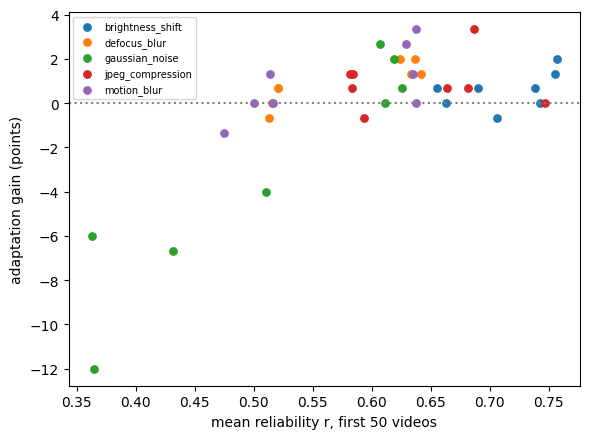

In [12]:
import glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

ROOT, METHOD, NS = "/kaggle/working", "vitta_style", (20, 50, 150)   # vitta_style = ungated entropy minimization
HARM_T = -0.03                                                        # "harmful" = gain <= -3 points

sig   = pd.read_csv(f"{ROOT}/phase3_signals_full_v2.csv")
split = pd.read_csv(f"{ROOT}/phase4_video_split_full_v2.csv")
ts    = pd.read_csv(f"{ROOT}/phase4_test_scores_full_v2.csv"); ts["rho"] = ts.rho.round(2)
key   = ["video", "corruption", "severity", "rho"]

# source statistics for ATC/DoC come from clean TRAIN videos only
cl = sig[(sig.corruption == "clean") & sig.video.isin(set(split.loc[split.split == "train", "video"]))]
acc_cl, conf_cl = cl.correct.mean(), cl.conf.to_numpy()
t_atc = np.quantile(conf_cl, 1 - acc_cl)
print(f"clean-train: n={len(cl)}  acc={acc_cl:.3f}  ATC threshold={t_atc:.3f}")

rows = []
for f in sorted(glob.glob(f"{ROOT}/phase5_full_v2_lr0.0001_*_sev*_rho*.csv")):
    d = pd.read_csv(f)
    if len(d) != 150: print("skip incomplete:", f); continue
    d["rho"] = d.rho.round(2)
    d = d.merge(ts[key + ["conf", "r_learned"]], on=key, how="left").sort_values("order")
    assert d.conf.notna().all(), f"missing scores for {f}"
    rec = dict(corruption=d.corruption.iloc[0], severity=int(d.severity.iloc[0]), rho=float(d.rho.iloc[0]),
               source_acc=d.source_correct.mean(), adapted_acc=d[f"{METHOD}_correct"].mean())
    rec["gain"] = rec["adapted_acc"] - rec["source_acc"]
    for n in NS:
        h = d.head(n); cf = h.conf.to_numpy()
        rec[f"AC@{n}"], rec[f"DoC@{n}"] = cf.mean(), acc_cl - (conf_cl.mean() - cf.mean())
        rec[f"ATC@{n}"], rec[f"meanR@{n}"] = (cf > t_atc).mean(), h.r_learned.mean()
    rows.append(rec)
C = pd.DataFrame(rows); harm = (C.gain <= HARM_T).astype(int)
print(f"\nconditions: {len(C)} | adaptation better: {(C.gain>0).sum()} | equal: {(C.gain==0).sum()} | worse: {(C.gain<0).sum()} | harmful (<={HARM_T:+.2f}): {harm.sum()}")

# Stage 1: does the label-free estimate track accuracy, and does it flag harm?
tab = []
for e in ["AC", "DoC", "ATC", "meanR"]:
    for n in NS:
        x = C[f"{e}@{n}"]
        tab.append(dict(estimator=e, N=n, MAE_vs_source_acc=(x - C.source_acc).abs().mean(),
                        spearman_with_acc=spearmanr(x, C.source_acc)[0], spearman_with_gain=spearmanr(x, C.gain)[0],
                        AUROC_flags_harm=roc_auc_score(harm, -x) if 0 < harm.sum() < len(harm) else np.nan))
print("\nSTAGE 1: estimate quality"); print(pd.DataFrame(tab).round(3).to_string(index=False))

# Stage 2: policy "adapt only if estimated accuracy >= tau"; tau is fit on OTHER conditions only
def value(df, est, tau): return np.where(df[est] >= tau, df.adapted_acc, df.source_acc)
def fit_tau(df, est):
    u = np.sort(df[est].unique()); cands = np.r_[-np.inf, (u[:-1] + u[1:]) / 2, np.inf]
    return max(cands, key=lambda t: (value(df, est, t).mean(), t))      # ties go to the more cautious (higher) tau
def loo(est, by):
    out = np.zeros(len(C))
    for g in C[by].unique():
        te = (C[by] == g).to_numpy()
        out[te] = value(C[te], est, fit_tau(C[~te], est))
    return out
C["cond"] = C.corruption + "_s" + C.severity.astype(str) + "_r" + C.rho.astype(str)
res = [dict(policy="never adapt (source-only)", acc=C.source_acc.mean(), worse_than_source=0),
       dict(policy="always adapt (ungated)", acc=C.adapted_acc.mean(), worse_than_source=int((C.gain < 0).sum())),
       dict(policy="oracle (best per condition)", acc=np.maximum(C.source_acc, C.adapted_acc).mean(), worse_than_source=0)]
for e in ["AC", "DoC", "ATC", "meanR"]:
    for n in (20, 50):
        for by in ("cond", "corruption"):
            v = loo(f"{e}@{n}", by)
            res.append(dict(policy=f"{e}@{n}, leave-one-{by}-out", acc=v.mean(), worse_than_source=int((v < C.source_acc.to_numpy() - 1e-9).sum())))
print("\nSTAGE 2: mean accuracy over conditions"); print(pd.DataFrame(res).round(4).to_string(index=False))

C.to_csv(f"{ROOT}/pivotB_condition_table.csv", index=False)
plt.figure(figsize=(6, 4.5))
for c, g in C.groupby("corruption"): plt.scatter(g["meanR@50"], g.gain * 100, label=c, s=28)
plt.axhline(0, c="gray", ls=":"); plt.xlabel("mean reliability r, first 50 videos"); plt.ylabel("adaptation gain (points)")
plt.legend(fontsize=7); plt.tight_layout(); plt.show()

In [13]:
# ============================================================
# PIVOT B — LEAKAGE-CONTROLLED STREAM-LEVEL SAFETY EVALUATION
# Initial N videos determine the decision.
# Only the remaining videos are used to evaluate that decision.
# CPU-only analysis. No model inference.
# ============================================================

import glob
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

ROOT = Path("/kaggle/working")
METHOD = "vitta_style"
NS = (20, 50)
HARM_T = -0.03

sig = pd.read_csv(ROOT / "phase3_signals_full_v2.csv")
split = pd.read_csv(ROOT / "phase4_video_split_full_v2.csv")
ts = pd.read_csv(ROOT / "phase4_test_scores_full_v2.csv")

key = ["video", "corruption", "severity", "rho"]
ts["rho"] = ts["rho"].round(2)

# Set an out-of-domain threshold using clean TRAIN videos only.
clean_train = sig[
    (sig["corruption"] == "clean")
    & sig["video"].isin(
        set(split.loc[split["split"] == "train", "video"])
    )
]

acc_clean = clean_train["correct"].mean()
conf_clean = clean_train["conf"].to_numpy()
atc_threshold = np.quantile(conf_clean, 1 - acc_clean)

print(
    f"Clean training data: n={len(clean_train)}, "
    f"accuracy={acc_clean:.3f}, "
    f"ATC threshold={atc_threshold:.3f}"
)

files = sorted(
    glob.glob(
        str(ROOT / "phase5_full_v2_lr0.0001_*_sev*_rho*.csv")
    )
)

if len(files) != 40:
    raise ValueError(
        f"Expected 40 per-condition CSVs; found {len(files)}. "
        "Restore/reconstruct these from the final 40of40 checkpoint first."
    )

records = []

for filename in files:
    d = pd.read_csv(filename)
    d["rho"] = d["rho"].round(2)
    d = d.sort_values("order").reset_index(drop=True)

    if len(d) != 150:
        raise ValueError(f"{filename}: expected 150 rows, got {len(d)}")

    # Add confidence and learned reliability from the saved test scores.
    d = d.merge(
        ts[key + ["conf", "r_learned"]],
        on=key,
        how="left",
        validate="one_to_one"
    )

    if d["conf"].isna().any() or d["r_learned"].isna().any():
        raise ValueError(f"Missing phase-4 scores while reading {filename}")

    for n in NS:
        initial = d.iloc[:n]
        future = d.iloc[n:]

        cf = initial["conf"].to_numpy()

        # These estimates only use information in the initial N videos.
        estimates = {
            "AC": cf.mean(),
            "DoC": acc_clean - (conf_clean.mean() - cf.mean()),
            "ATC": (cf > atc_threshold).mean(),
            "meanR": initial["r_learned"].mean(),
        }

        # Crucial correction: all performance targets come from the
        # FUTURE portion only. Initial videos aren't scored again.
        source_future = future["source_correct"].mean()
        adapted_future = future[f"{METHOD}_correct"].mean()

        records.append({
            "corruption": d["corruption"].iloc[0],
            "severity": int(d["severity"].iloc[0]),
            "rho": float(d["rho"].iloc[0]),
            "N": n,
            **{f"{k}": v for k, v in estimates.items()},
            "source_future_acc": source_future,
            "adapted_future_acc": adapted_future,
            "future_gain": adapted_future - source_future,
            "harmful": int(
                adapted_future - source_future <= HARM_T
            ),
        })

C = pd.DataFrame(records)
C["condition"] = (
    C["corruption"]
    + "_s" + C["severity"].astype(str)
    + "_r" + C["rho"].astype(str)
)

print("\nConditions evaluated:", C["condition"].nunique())
print("Rows (40 conditions × 2 initial-window sizes):", len(C))

# ------------------------------------------------------------
# STAGE 1: How well do early estimates predict FUTURE outcomes?
# ------------------------------------------------------------

stage1 = []

for n in NS:
    D = C[C["N"] == n].copy()

    for est in ["AC", "DoC", "ATC", "meanR"]:
        x = D[est].to_numpy()
        source_y = D["source_future_acc"].to_numpy()
        gain_y = D["future_gain"].to_numpy()
        harm_y = D["harmful"].to_numpy()

        auc = (
            roc_auc_score(harm_y, -x)
            if len(np.unique(harm_y)) == 2
            else np.nan
        )

        stage1.append({
            "estimator": est,
            "initial_videos": n,
            "MAE_source_future_accuracy": np.mean(
                np.abs(x - source_y)
            ),
            "spearman_vs_future_source_accuracy":
                spearmanr(x, source_y).statistic,
            "spearman_vs_future_adaptation_gain":
                spearmanr(x, gain_y).statistic,
            "AUROC_detect_future_harm": auc,
            "harmful_future_conditions": int(harm_y.sum()),
        })

stage1_df = pd.DataFrame(stage1)
print("\nSTAGE 1 — Future outcome prediction")
print(stage1_df.round(3).to_string(index=False))

# ------------------------------------------------------------
# STAGE 2: Fit threshold on other conditions, test future accuracy
# ------------------------------------------------------------

def policy_value(D, estimator, threshold):
    return np.where(
        D[estimator].to_numpy() >= threshold,
        D["adapted_future_acc"].to_numpy(),
        D["source_future_acc"].to_numpy()
    )


def fit_threshold(train, estimator):
    values = np.sort(train[estimator].unique())

    if len(values) == 0:
        raise ValueError("No training values available for threshold.")

    candidates = np.r_[
        -np.inf,
        (values[:-1] + values[1:]) / 2,
        np.inf
    ]

    # Fit on training conditions' future outcomes only.
    # Ties favor the more cautious/higher threshold.
    return max(
        candidates,
        key=lambda t: (
            policy_value(train, estimator, t).mean(),
            t
        )
    )


def cross_validate_policy(D, estimator, grouping):
    output = np.full(len(D), np.nan)

    for group in D[grouping].unique():
        test_mask = D[grouping].eq(group).to_numpy()
        train = D.loc[~test_mask]
        test = D.loc[test_mask]

        threshold = fit_threshold(train, estimator)
        output[test_mask] = policy_value(
            test, estimator, threshold
        )

    return output


stage2 = []

for n in NS:
    D = C[C["N"] == n].copy()

    baselines = {
        "never adapt (source-only)": D["source_future_acc"].to_numpy(),
        "always adapt": D["adapted_future_acc"].to_numpy(),
        "oracle upper bound (not deployable)": np.maximum(
            D["source_future_acc"].to_numpy(),
            D["adapted_future_acc"].to_numpy()
        ),
    }

    for policy, values in baselines.items():
        stage2.append({
            "initial_videos": n,
            "policy": policy,
            "mean_future_accuracy": values.mean(),
            "conditions_below_source": int(
                (values < D["source_future_acc"].to_numpy() - 1e-9).sum()
            ),
        })

    for est in ["AC", "DoC", "ATC", "meanR"]:
        for grouping in ["condition", "corruption"]:
            predicted = cross_validate_policy(D, est, grouping)

            stage2.append({
                "initial_videos": n,
                "policy": f"{est}, leave-one-{grouping}-out",
                "mean_future_accuracy": predicted.mean(),
                "conditions_below_source": int(
                    (
                        predicted
                        < D["source_future_acc"].to_numpy() - 1e-9
                    ).sum()
                ),
            })

stage2_df = pd.DataFrame(stage2)
print("\nSTAGE 2 — Future-only policy evaluation")
print(stage2_df.round(4).to_string(index=False))

# Save the results.
C.to_csv(ROOT / "pivotB_future_condition_table.csv", index=False)
stage1_df.to_csv(ROOT / "pivotB_future_estimator_quality.csv", index=False)
stage2_df.to_csv(ROOT / "pivotB_future_policy_results.csv", index=False)

print("\n✅ Saved:")
print(ROOT / "pivotB_future_condition_table.csv")
print(ROOT / "pivotB_future_estimator_quality.csv")
print(ROOT / "pivotB_future_policy_results.csv")

Clean training data: n=200, accuracy=0.790, ATC threshold=0.359

Conditions evaluated: 40
Rows (40 conditions × 2 initial-window sizes): 80

STAGE 1 — Future outcome prediction
estimator  initial_videos  MAE_source_future_accuracy  spearman_vs_future_source_accuracy  spearman_vs_future_adaptation_gain  AUROC_detect_future_harm  harmful_future_conditions
       AC              20                       0.148                               0.858                               0.374                     0.910                          4
      DoC              20                       0.064                               0.858                               0.374                     0.910                          4
      ATC              20                       0.095                               0.760                               0.375                     0.844                          4
    meanR              20                       0.057                               0.813                  

In [14]:
import copy, time, os, glob
from collections import deque
import numpy as np, pandas as pd, torch, torch.nn as nn

ROOT = "/kaggle/working"
LR_C, MB = 1e-4, 2
W, K_PERIOD, REPEATS = 20, 50, 1          # window (videos), periodic-reset interval, stream repeats (>1 = longer stream, new noise draws)
CONDS_C   = [("gaussian_noise", 5, 0.0), ("gaussian_noise", 5, 0.5), ("gaussian_noise", 5, 0.85), ("gaussian_noise", 5, 1.0),
             ("defocus_blur", 5, 0.0), ("jpeg_compression", 5, 1.0)]       # 4 harmful conditions + 2 harmless controls
METHODS_C = ["periodic", "entropy_drift", "src_disagree", "src_diversity", "oracle_reset"]
LAB = globals().get("label2id") or globals().get("l2i")

class Monitor:
    """One reset policy. update() sees what the adapted model predicted (pre-update) and returns True to reset it to source."""
    def __init__(self, kind, W=20, K=50, tau_d=0.5, tau_v=0.6, z_k=2.5, alpha=0.1, warm=10, cool=None, oracle_drop=0.10):
        self.kind, self.W, self.K, self.tau_d, self.tau_v = kind, W, K, tau_d, tau_v
        self.z_k, self.alpha, self.warm, self.oracle_drop = z_k, alpha, warm, oracle_drop
        self.cool = W if cool is None else cool
        self.t = 0; self.reset_state()
    def reset_state(self):
        self.win = deque(maxlen=self.W); self.m = None; self.v = 0.0; self.n_ent = 0; self.since = 0
    def update(self, pred_a, pred_s, correct_a, correct_s, entropy):
        self.t += 1; self.since += 1
        self.win.append((pred_a, pred_s, correct_a, correct_s)); fire = False
        if self.kind == "periodic":                                   # RDumb-style: fixed schedule
            fire = self.t % self.K == 0
        elif self.kind == "entropy_drift":                            # RDumb++-style: z-score of own prediction entropy
            if self.m is None: self.m = entropy
            else:
                if self.n_ent >= self.warm and self.since >= self.cool:
                    fire = abs((entropy - self.m) / np.sqrt(self.v + 1e-6)) > self.z_k
                d = entropy - self.m; self.m += self.alpha * d; self.v = (1 - self.alpha) * (self.v + self.alpha * d * d)
            self.n_ent += 1
        elif len(self.win) == self.W and self.since >= self.cool:
            a = np.array(self.win)
            if self.kind == "src_disagree":                           # ours: adapted vs frozen source disagree too often
                fire = float((a[:, 0] != a[:, 1]).mean()) > self.tau_d
            elif self.kind == "src_diversity":                        # ours: adapted predictions collapse to few classes vs source
                fire = len(set(a[:, 0])) / max(len(set(a[:, 1])), 1) < self.tau_v
            elif self.kind == "oracle_reset":                         # uses labels: ceiling for any reset rule
                fire = float(a[:, 2].mean()) < float(a[:, 3].mean()) - self.oracle_drop
        if fire: self.reset_state()
        return fire                                                   # kind "none" never fires (= ungated)

class Adapter:
    def __init__(self, lr):
        self.model = copy.deepcopy(model).to(device).eval()
        for p in self.model.parameters(): p.requires_grad_(False)
        self.params = []
        for mod in self.model.modules():
            if isinstance(mod, nn.LayerNorm):
                for p in (mod.weight, mod.bias): p.requires_grad_(True); self.params.append(p)
        self.init = [p.detach().clone() for p in self.params]; self.lr = lr
        self.opt = torch.optim.Adam(self.params, lr=lr)
    def reset(self):                                                  # back to source weights, fresh optimizer state
        with torch.no_grad():
            for p, q in zip(self.params, self.init): p.copy_(q)
        self.opt = torch.optim.Adam(self.params, lr=self.lr)

def make_x(seq): return torch.cat([processor(seq[m*16:(m+1)*16], return_tensors="pt")["pixel_values"] for m in range(4)]).to(device)

def step(ad, x):
    """Predict on this video first, then update; probabilities returned are from the PRE-update forward pass."""
    n = x.shape[0]; ad.opt.zero_grad(set_to_none=True); probs = []
    for i in range(0, n, MB):
        p = torch.softmax(ad.model(pixel_values=x[i:i+MB]).logits, -1)
        (-(p * torch.log(p + 1e-8)).sum(-1).sum() / n).backward(); probs.append(p.detach())
    ad.opt.step(); return torch.cat(probs)

# ---- calibrate the two source-referenced thresholds on a CLEAN validation stream (no labels, no test conditions) ----
split = pd.read_csv(f"{ROOT}/phase4_video_split_full_v2.csv")
val_names = sorted(split.loc[split.split == "validation", "video"])
def calibrate(names, lr, W):
    src, ad = copy.deepcopy(model).to(device).eval(), Adapter(lr); s_hist, a_hist, ok_a, ok_s = [], [], [], []
    for name in names:
        x = make_x(load_segments(path_of[name], 4, 16)); gt = LAB[path_of[name].split("/")[-2]]
        with torch.no_grad(): s = int(torch.softmax(src(pixel_values=x).logits, -1).mean(0).argmax())
        a = int(step(ad, x).mean(0).argmax()); s_hist.append(s); a_hist.append(a); ok_a.append(a == gt); ok_s.append(s == gt)
    a, s = np.array(a_hist), np.array(s_hist); n = len(a) - W + 1
    dis = [float((a[i:i+W] != s[i:i+W]).mean()) for i in range(n)]
    div = [len(set(a[i:i+W])) / max(len(set(s[i:i+W])), 1) for i in range(n)]
    thr = dict(tau_d=float(np.clip(np.percentile(dis, 95) + 0.10, 0.30, 0.80)), tau_v=float(np.clip(np.percentile(div, 5) - 0.10, 0.30, 0.80)))
    info = dict(clean_val_source_acc=float(np.mean(ok_s)), clean_val_adapted_acc=float(np.mean(ok_a)),
                max_window_disagree=max(dis), min_window_diversity_ratio=min(div))
    del src, ad; torch.cuda.empty_cache(); return thr, info
THR_C, info = calibrate(val_names, LR_C, W)
print("calibration (clean validation stream):", {k: round(v, 3) for k, v in info.items()})
print("thresholds:", {k: round(v, 3) for k, v in THR_C.items()}, "| entropy-drift z=2.5 (RDumb++ default) | periodic every", K_PERIOD)

calibration (clean validation stream): {'clean_val_source_acc': 0.76, 'clean_val_adapted_acc': 0.76, 'max_window_disagree': 0.0, 'min_window_diversity_ratio': 1.0}
thresholds: {'tau_d': 0.3, 'tau_v': 0.8} | entropy-drift z=2.5 (RDumb++ default) | periodic every 50


In [15]:
def rho_tag(r): return f"{float(r):.2f}".replace(".", "p")
def run_condition_c(cname, sev, rho, names, lr=LR_C, methods=METHODS_C, repeats=REPEATS):
    methods = ["none"] + list(methods)                                # "none" = ungated, no reset, run inside the same loop
    src = copy.deepcopy(model).to(device).eval()
    ads  = {m: Adapter(lr) for m in methods}
    mons = {m: Monitor(m, W=W, K=K_PERIOD, **THR_C) for m in methods}
    rows, t0, order = [], time.time(), 0
    for rep in range(repeats):
        for name in names:
            path = path_of[name]; gt = LAB[path.split("/")[-2]]
            x = make_x(corrupt_video(load_segments(path, 4, 16), cname, sev, rho, seed=vid_index[name] + 1000 * rep))
            with torch.no_grad(): s = int(torch.softmax(src(pixel_values=x).logits, -1).mean(0).argmax())
            rec = dict(video=name, rep=rep, order=order, corruption=cname, severity=sev, rho=rho, src_pred=s, source_correct=int(s == gt))
            for m in methods:
                P = step(ads[m], x); a = int(P.mean(0).argmax()); H = float(-(P * torch.log(P + 1e-8)).sum(-1).mean())
                fired = mons[m].update(a, s, int(a == gt), int(s == gt), H)
                if fired: ads[m].reset()                              # takes effect from the NEXT video
                rec.update({f"{m}_correct": int(a == gt), f"{m}_pred": a, f"{m}_entropy": H, f"{m}_reset": int(fired)})
            rows.append(rec); order += 1
            if order % 25 == 0:
                d = pd.DataFrame(rows)
                print(f"  {cname} s{sev} rho={rho}: {order} | {(time.time()-t0)/60:.1f} min | source {d.source_correct.mean():.3f} | " +
                      " | ".join(f"{m} {d[m+'_correct'].mean():.3f}({int(d[m+'_reset'].sum())}r)" for m in methods))
    del src, ads; torch.cuda.empty_cache(); return pd.DataFrame(rows)

for cname, sev, rho in CONDS_C:
    out = f"{ROOT}/phase5c_reset_{cname}_sev{sev}_rho{rho_tag(rho)}.csv"
    if os.path.exists(out): print("exists, skipping:", out); continue
    print(f"\n=== {cname}, severity {sev}, rho={rho} ==="); df = run_condition_c(cname, sev, rho, stream_names)
    df.to_csv(out, index=False); print("saved", out)


=== gaussian_noise, severity 5, rho=0.0 ===
  gaussian_noise s5 rho=0.0: 25 | 4.3 min | source 0.160 | none 0.160(0r) | periodic 0.160(0r) | entropy_drift 0.160(0r) | src_disagree 0.160(0r) | src_diversity 0.160(0r) | oracle_reset 0.160(0r)
  gaussian_noise s5 rho=0.0: 50 | 8.6 min | source 0.200 | none 0.180(0r) | periodic 0.180(1r) | entropy_drift 0.180(1r) | src_disagree 0.180(0r) | src_diversity 0.180(1r) | oracle_reset 0.180(0r)
  gaussian_noise s5 rho=0.0: 75 | 12.9 min | source 0.253 | none 0.200(0r) | periodic 0.240(1r) | entropy_drift 0.240(2r) | src_disagree 0.227(1r) | src_diversity 0.227(1r) | oracle_reset 0.200(1r)
  gaussian_noise s5 rho=0.0: 100 | 17.1 min | source 0.250 | none 0.180(0r) | periodic 0.240(2r) | entropy_drift 0.240(3r) | src_disagree 0.230(1r) | src_diversity 0.220(2r) | oracle_reset 0.210(1r)
  gaussian_noise s5 rho=0.0: 125 | 21.4 min | source 0.280 | none 0.168(0r) | periodic 0.272(2r) | entropy_drift 0.272(4r) | src_disagree 0.240(2r) | src_diversity 

In [16]:
import glob, numpy as np, pandas as pd
ROOT = "/kaggle/working"; rng = np.random.default_rng(0)
ALL = ["none", "periodic", "entropy_drift", "src_disagree", "src_diversity", "oracle_reset"]
rows = []
for f in sorted(glob.glob(f"{ROOT}/phase5c_reset_*.csv")):
    d = pd.read_csv(f); n = len(d); s = d.source_correct.to_numpy(); c0 = d["none_correct"].to_numpy()
    ref = {}                                                           # existing gated baselines (same stream, same seeds) if present
    rt = f"{float(d.rho.iloc[0]):.2f}".replace(".", "p")
    g = glob.glob(f"{ROOT}/phase5_full_v2_lr0.0001_{d.corruption.iloc[0]}_sev{int(d.severity.iloc[0])}_rho{rt}.csv")
    if g and d.rep.max() == 0:
        r = pd.read_csv(g[0]).sort_values("order")
        if len(r) == n and (r.video.to_numpy() == d.video.to_numpy()).all(): ref = {"conf_gate": r.conf_gate_correct.to_numpy(), "r_gate": r.r_gate_correct.to_numpy()}
    for m in ALL + list(ref):
        a = ref[m] if m in ref else d[f"{m}_correct"].to_numpy()
        diff = a - c0; bs = [diff[rng.integers(0, n, n)].mean() for _ in range(1000)]; lo, hi = np.percentile(bs, [2.5, 97.5])
        resets = int(d[f"{m}_reset"].sum()) if f"{m}_reset" in d else 0
        first = int(d.loc[d[f"{m}_reset"] == 1, "order"].min()) if resets else np.nan
        rows.append(dict(condition=f"{d.corruption.iloc[0][:5]} s{d.severity.iloc[0]} r{d.rho.iloc[0]}", method=m, n=n, source=s.mean(), acc=a.mean(),
                         gain_vs_source=a.mean() - s.mean(), vs_ungated=a.mean() - c0.mean(), vs_ungated_ci=f"[{lo:+.3f},{hi:+.3f}]",
                         HAR=((s == 1) & (a == 0)).mean(), resets=resets, first_reset=first))
T = pd.DataFrame(rows)
print(T.round(3).to_string(index=False))
print("\nMEAN OVER CONDITIONS"); print(T.groupby("method")[["acc", "gain_vs_source", "vs_ungated", "HAR", "resets"]].mean().round(3).reindex(ALL + ["conf_gate", "r_gate"]).dropna(how="all"))
T.to_csv(f"{ROOT}/phase5c_reset_summary.csv", index=False)

     condition        method   n  source   acc  gain_vs_source  vs_ungated   vs_ungated_ci   HAR  resets  first_reset
 defoc s5 r0.0          none 150   0.413 0.420           0.007       0.000 [+0.000,+0.000] 0.007       0          NaN
 defoc s5 r0.0      periodic 150   0.413 0.420           0.007       0.000 [-0.027,+0.027] 0.000       3         49.0
 defoc s5 r0.0 entropy_drift 150   0.413 0.407          -0.007      -0.013 [-0.033,+0.000] 0.007       3         25.0
 defoc s5 r0.0  src_disagree 150   0.413 0.420           0.007       0.000 [+0.000,+0.000] 0.007       0          NaN
 defoc s5 r0.0 src_diversity 150   0.413 0.407          -0.007      -0.013 [-0.033,+0.000] 0.007       1         84.0
 defoc s5 r0.0  oracle_reset 150   0.413 0.420           0.007       0.000 [+0.000,+0.000] 0.007       0          NaN
 defoc s5 r0.0     conf_gate 150   0.413 0.427           0.013       0.007 [-0.027,+0.040] 0.000       0          NaN
 defoc s5 r0.0        r_gate 150   0.413 0.427          

In [17]:
from pathlib import Path
import zipfile
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working")
ZIP_PATH = ROOT / "AFML_Phase5C_Reset_Results.zip"

# Find all Pivot C reset experiment CSVs
csv_files = sorted(ROOT.glob("phase5c_reset_*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No phase5c_reset_*.csv files found in /kaggle/working"
    )

# Create ZIP
with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for file in csv_files:
        zf.write(file, arcname=file.name)

print("✅ ZIP created successfully!")
print(f"CSV files included: {len(csv_files)}")
for file in csv_files:
    print(f"  - {file.name}")

print(f"\nZIP size: {ZIP_PATH.stat().st_size / 1024:.1f} KB")
print("\nDownload your results:")
display(FileLink(str(ZIP_PATH)))

✅ ZIP created successfully!
CSV files included: 7
  - phase5c_reset_defocus_blur_sev5_rho0p00.csv
  - phase5c_reset_gaussian_noise_sev5_rho0p00.csv
  - phase5c_reset_gaussian_noise_sev5_rho0p50.csv
  - phase5c_reset_gaussian_noise_sev5_rho0p85.csv
  - phase5c_reset_gaussian_noise_sev5_rho1p00.csv
  - phase5c_reset_jpeg_compression_sev5_rho1p00.csv
  - phase5c_reset_summary.csv

ZIP size: 59.0 KB

Download your results:


/kaggle/working/AFML_Phase5C_Reset_Results.zip

In [1]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import FileLink, display

ROOT = Path("/kaggle/working")

files = sorted(ROOT.glob("phase5c_reset_*.csv"))
if len(files) != 6:
    # Check for zip archives in working or attached input datasets
    zip_candidates = list(ROOT.glob("*Phase5C*.zip")) + list(Path("/kaggle/input").glob("**/*Phase5C*.zip")) + list(Path("./Checkpoints").glob("*Phase5C*.zip"))
    if zip_candidates:
        print(f"Unpacking {zip_candidates[0]} to {ROOT}...")
        with zipfile.ZipFile(zip_candidates[0], "r") as z: z.extractall(ROOT)
        files = sorted(ROOT.glob("phase5c_reset_*.csv"))
if len(files) != 6:
    raise ValueError(
        f"Expected 6 Pivot C condition CSVs, found {len(files)}. "
        "Check that all six condition files have been saved."
    )

methods = [
    "none",
    "periodic",
    "entropy_drift",
    "src_disagree",
    "src_diversity",
    "oracle_reset",
]

condition_rows = []

for file in files:
    d = pd.read_csv(file)

    required = {"video", "order", "source_correct"}
    missing = required - set(d.columns)

    if missing:
        raise ValueError(f"{file.name}: missing columns {sorted(missing)}")

    if len(d) != 150:
        raise ValueError(f"{file.name}: expected 150 rows, found {len(d)}")

    source = d["source_correct"].astype(int).to_numpy()

    row = {
        "condition_file": file.name,
        "corruption": d["corruption"].iloc[0],
        "severity": int(d["severity"].iloc[0]),
        "rho": float(d["rho"].iloc[0]),
        "n_videos": len(d),
        "source_accuracy": source.mean(),
    }

    for method in methods:
        correct_col = f"{method}_correct"
        reset_col = f"{method}_reset"

        if correct_col not in d.columns or reset_col not in d.columns:
            raise ValueError(
                f"{file.name}: missing {correct_col} or {reset_col}"
            )

        pred = d[correct_col].astype(int).to_numpy()
        resets = d[reset_col].astype(int).to_numpy()

        row[f"{method}_accuracy"] = pred.mean()
        row[f"{method}_gain_vs_source"] = pred.mean() - source.mean()

        # Fraction of all videos where source was correct but
        # the method was wrong. This is an unconditional rate.
        row[f"{method}_harmful_transition_rate"] = (
            ((source == 1) & (pred == 0)).mean()
        )

        row[f"{method}_reset_count"] = int(resets.sum())

    condition_rows.append(row)

conditions = pd.DataFrame(condition_rows).sort_values(
    ["corruption", "severity", "rho"]
)

conditions.to_csv(ROOT / "phase5c_reset_by_condition.csv", index=False)

# Macro-average over the six tested conditions.
summary_rows = []

for method in methods:
    summary_rows.append({
        "method": method,
        "mean_accuracy_pct": 100 * conditions[f"{method}_accuracy"].mean(),
        "mean_gain_vs_source_pp": (
            100 * conditions[f"{method}_gain_vs_source"].mean()
        ),
        "mean_harmful_transition_pct": (
            100 * conditions[
                f"{method}_harmful_transition_rate"
            ].mean()
        ),
        "mean_resets_per_condition": (
            conditions[f"{method}_reset_count"].mean()
        ),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(ROOT / "phase5c_reset_summary.csv", index=False)

print("PIVOT C — CONDITION RESULTS")
print(conditions.round(4).to_string(index=False))

print("\nPIVOT C — MACRO AVERAGE OVER SIX CONDITIONS")
print(summary.round(4).to_string(index=False))

# Accuracy plot
plt.figure(figsize=(10, 5))
plt.bar(summary["method"], summary["mean_accuracy_pct"])
plt.ylabel("Mean condition accuracy (%)")
plt.xlabel("Method")
plt.title("Pivot C: Reset Strategy Comparison")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plot_path = ROOT / "phase5c_reset_accuracy.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Package original data and summary artifacts.
zip_path = ROOT / "AFML_Phase5C_Final_Analysis.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file in files:
        zf.write(file, arcname=file.name)

    for name in [
        "phase5c_reset_by_condition.csv",
        "phase5c_reset_summary.csv",
        "phase5c_reset_accuracy.png",
    ]:
        path = ROOT / name
        zf.write(path, arcname=path.name)

print("\n✅ Pivot C summary created.")
print("Condition table:", ROOT / "phase5c_reset_by_condition.csv")
print("Summary table:", ROOT / "phase5c_reset_summary.csv")
print("Analysis ZIP:", zip_path)

display(FileLink(str(zip_path)))

ValueError: Expected 6 Pivot C condition CSVs, found 0. Check that all six condition files have been saved.

---
<a id="section-8-unified-project-deliverables--artifact-exporter"></a>
# Section 8: Unified Project Deliverables & Artifact Exporter

**Goal:** Consolidate all generated experimental artifacts, figures, predictions, and summary tables into a single timestamped master distribution archive.

In [ ]:
# FINAL BACKUP: run this after the pipeline. Download the ZIP to your computer.
import glob, os
backup_patterns = [
    "/kaggle/working/phase2_*_v2.*", "/kaggle/working/phase3_*_v2.*",
    "/kaggle/working/phase4_*_v2.csv", "/kaggle/working/phase4_video_split_v2.csv",
    "/kaggle/working/phase4_reliability_estimator_v2.joblib", "/kaggle/working/phase4_oof_scores_v2_exploratory.csv",
    "/kaggle/working/phase5_*_v2*.csv", "/kaggle/working/test_videos.txt",
]
backup_files = sorted({p for pattern in backup_patterns for p in glob.glob(pattern) if os.path.isfile(p)})
print("Files included in final backup:")
for p in backup_files: print(f"  {os.path.basename(p)} ({os.path.getsize(p)/1024/1024:.2f} MB)")
if not backup_files: print("WARNING: no artifacts found; nothing will be recoverable from this runtime.")
checkpoint_files("AFML_FINAL_BACKUP", backup_files)
